# INN Hotels Project

## Context

A significant number of hotel bookings are called-off due to cancellations or no-shows. The typical reasons for cancellations include change of plans, scheduling conflicts, etc. This is often made easier by the option to do so free of charge or preferably at a low cost which is beneficial to hotel guests but it is a less desirable and possibly revenue-diminishing factor for hotels to deal with. Such losses are particularly high on last-minute cancellations.

The new technologies involving online booking channels have dramatically changed customers’ booking possibilities and behavior. This adds a further dimension to the challenge of how hotels handle cancellations, which are no longer limited to traditional booking and guest characteristics.

The cancellation of bookings impact a hotel on various fronts:
* Loss of resources (revenue) when the hotel cannot resell the room.
* Additional costs of distribution channels by increasing commissions or paying for publicity to help sell these rooms.
* Lowering prices last minute, so the hotel can resell a room, resulting in reducing the profit margin.
* Human resources to make arrangements for the guests.

## Objective
The increasing number of cancellations calls for a Machine Learning based solution that can help in predicting which booking is likely to be canceled. INN Hotels Group has a chain of hotels in Portugal, they are facing problems with the high number of booking cancellations and have reached out to your firm for data-driven solutions. You as a data scientist have to analyze the data provided to find which factors have a high influence on booking cancellations, build a predictive model that can predict which booking is going to be canceled in advance, and help in formulating profitable policies for cancellations and refunds.

## Data Description
The data contains the different attributes of customers' booking details. The detailed data dictionary is given below.


**Data Dictionary**

* Booking_ID: unique identifier of each booking
* no_of_adults: Number of adults
* no_of_children: Number of Children
* no_of_weekend_nights: Number of weekend nights (Saturday or Sunday) the guest stayed or booked to stay at the hotel
* no_of_week_nights: Number of week nights (Monday to Friday) the guest stayed or booked to stay at the hotel
* type_of_meal_plan: Type of meal plan booked by the customer:
    * Not Selected – No meal plan selected
    * Meal Plan 1 – Breakfast
    * Meal Plan 2 – Half board (breakfast and one other meal)
    * Meal Plan 3 – Full board (breakfast, lunch, and dinner)
* required_car_parking_space: Does the customer require a car parking space? (0 - No, 1- Yes)
* room_type_reserved: Type of room reserved by the customer. The values are ciphered (encoded) by INN Hotels.
* lead_time: Number of days between the date of booking and the arrival date
* arrival_year: Year of arrival date
* arrival_month: Month of arrival date
* arrival_date: Date of the month
* market_segment_type: Market segment designation.
* repeated_guest: Is the customer a repeated guest? (0 - No, 1- Yes)
* no_of_previous_cancellations: Number of previous bookings that were canceled by the customer prior to the current booking
* no_of_previous_bookings_not_canceled: Number of previous bookings not canceled by the customer prior to the current booking
* avg_price_per_room: Average price per day of the reservation; prices of the rooms are dynamic. (in euros)
* no_of_special_requests: Total number of special requests made by the customer (e.g. high floor, view from the room, etc)
* booking_status: Flag indicating if the booking was canceled or not.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Importing necessary libraries and data

In [2]:
#C1
# Mount Drive Short
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive', force_remount=True)
%cd "./drive/MyDrive/Colab Notebooks/"

!ls *.ipynb

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks
'Copy of INNHotels_ScottHorning_FullCode.ipynb'
'INNHotels_ScottHorning_FullCode (1).ipynb'
 INNHotels_ScottHorning_FullCode.ipynb
'WSJ Cherry Picking 001.ipynb'


In [104]:
 #C2
 # House keeping... print the table of contents
import json


NB = Path("Copy of INNHotels_ScottHorning_FullCode.ipynb")

nb = json.loads(NB.read_text())

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "markdown":
        continue
    src = "".join(cell.get("source") or []).strip()
    if not src:
        continue
    first = src.splitlines()[0].rstrip()
    hashes = 0
    for ch in first:
        if ch == "#":
            hashes = hashes + 1
        else:
            break
    level = hashes if hashes > 0 else 0
    indent = "  " * max(level - 1, 0)
    print(f"{i:03d}  {indent}{first[:100]}")

000  # INN Hotels Project
002    ## Importing necessary libraries and data
007    ## Function Definitions
008      ###confusion_matrix_sklearn
010      ###model_performance_classification_sklearn
012      ###Category Pivot
014      ###intToMonthName
016      ###Glimpse
018      ###histogram_boxplot
020      ###labeled_barplot
021      ### category_boxplot
023      ###treat_outliers
025      ###distribution_plot_wrt_target
028      ###stacked_barplot
030      ###confusion_matrix_statsmodels
032      ###checking_vif
034      ###model_performance_classification_statsmodels
036    ## Data Overview
048  # Observation
049    ## Exploratory Data Analysis (EDA)
050      ###**Leading Questions**:
051        #### 1. What are the busiest months in the hotel?
053        ####2. Which market segment do most of the guests come from?
055        ####3. Room prices differ by market segment. Price is euros per room-day.
057        ####4. What percentage of bookings are canceled?
059        ####5. Repeati

In [4]:
#C3
import warnings

warnings.filterwarnings("ignore")
from statsmodels.tools.sm_exceptions import ConvergenceWarning

warnings.simplefilter("ignore", ConvergenceWarning)

# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)
# setting the precision of floating numbers to 5 decimal points
pd.set_option("display.float_format", lambda x: "%.5f" % x)

# Library to split data
from sklearn.model_selection import train_test_split

# To build model for prediction
import statsmodels.stats.api as sms
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from statsmodels.tools.tools import add_constant
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# To tune different models
from sklearn.model_selection import GridSearchCV


# To get diferent metric scores
from sklearn.metrics import    f1_score
from sklearn.metrics import    accuracy_score
from sklearn.metrics import    recall_score
from sklearn.metrics import    precision_score
from sklearn.metrics import    confusion_matrix
from sklearn.metrics import    roc_auc_score
# from sklearn.metrics import    plot_confusion_matrix
from sklearn.metrics import    precision_recall_curve
from sklearn.metrics import    roc_curve
from sklearn.metrics import    make_scorer



In [5]:
#C4
# Set up and document the 'home' directory for this excercise and any artifacts
# from google.colab import drive
# import os as os
#Set up and document the 'home' directory for this excercise and any artifacts
# drive.mount('/content/drive', force_remount=True)
path ='/content/drive/MyDrive/colab Notebooks/'
fn= 'INNHotelsGroup.csv'

pathfn = path+fn
print("\nFully formed file path and name is :",pathfn)

#df : a working editable copy of the data
#df_backup : is a reference copy of the original dataset... creating a copy of the data so that original data remains unchanged
df=pd.read_csv(fn)
df_backup = df.copy()



Fully formed file path and name is : /content/drive/MyDrive/colab Notebooks/INNHotelsGroup.csv


## Function Definitions
An area to define functions for code reuse

###confusion_matrix_sklearn

In [6]:
#C5
def confusion_matrix_sklearn(model, predictors, target):
    """
    Plot the confusion matrix with counts and percent of all rows.
    predict() uses the default 0.5 cutoff.
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

###model_performance_classification_sklearn

In [7]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn
#C6
def model_performance_classification_sklearn(model, predictors, target):
    """Accuracy, recall, precision, and F1 from model.predict (default 0.5)."""
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)
    recall = recall_score(target, pred)
    precision = precision_score(target, pred)
    f1 = f1_score(target, pred)

    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1},
        index=[0],
    )
    return df_perf

###Category Pivot

In [8]:
#C7
def category_pivot(df, cat, num):
    """Profile a numeric column by one category: count, mean, sample std, min, quartiles, max, share of rows."""
    def my25(g):
        return np.percentile(g, 25)

    def my50(g):
        return np.percentile(g, 50)

    def my75(g):
        return np.percentile(g, 75)

    my_table = df.pivot_table(
        index=cat,
        values=num,
        aggfunc={num: ["count", "mean", "std", "min", my25, my50, my75, "max"]},
        sort=False,
    )
    my_table.columns = [
        c[1] if isinstance(c, tuple) and c[1] else (c[0] if isinstance(c, tuple) else c)
        for c in my_table.columns
    ]
    my_table = my_table.reset_index()
    my_table["pct"] = 100 * my_table["count"] / my_table["count"].sum()
    return my_table

###intToMonthName

In [9]:
#C8
import datetime

def int_to_month_name(month_integer):
    return datetime.date(1900, int(month_integer), 1).strftime("%B")

###Glimpse

In [10]:
#C9
def glimpse(df):
    print(f"{df.shape[0]} rows and {df.shape[1]} columns")
    print("head")
    print(df.head(5).to_string())
    print("sample")
    print(df.sample(5, random_state=1).to_string())
    print("tail")
    print(df.tail(5).to_string())

###histogram_boxplot
The histogram_boxplot() function can be used to draw a histogram and a boxplot of a variable on thesame scale. The function takes as input a dataframe, the variable to be plotted, the size of the figure(set to 15x10 by default), whether or not to display the density curve on the histogram (set to falseby default), and the number of bins of the histogram (set to be automatically determined by seabornby default)

In [11]:
#C10
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    """Boxplot and histogram for one numeric column.
    Mean is green dashed; median is black.
    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )
    sns.boxplot(data=data, x=feature, ax=ax_box2, showmeans=True, color="violet")
    if bins:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins)
    else:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist2)
    ax_hist2.axvline(data[feature].mean(), color="green", linestyle="--")
    ax_hist2.axvline(data[feature].median(), color="black", linestyle="-")
    plt.show()
    print(data[feature].describe().to_string())

###labeled_barplot
The labeled_barplot() function can be used to display a bar graph with labels (count or percentage) above each of the bars. It takes as input a dataframe, the variable to be plotted, whether to display the count of percentages over the bars (set to counts by default) and the top n number of most frequent categories to display (set to all categories by default). The different blocks in the function work as follows:

### category_boxplot

In [12]:
#C12
def category_boxplot(data, cat, num, hue=None, wider=0, taller=0):
    """
    Boxplot of one numeric column by one category.
    data: dataframe
    cat: categorical column, drawn on x
    num: numeric column, drawn on y
    hue: optional second category
    wider, taller: added to the default figure size (15, 9)
    """
    plt.figure(figsize=(15 + wider, 9 + taller))
    ax = sns.boxplot(data=data, x=cat, y=num, hue=hue)
    plt.setp(ax.get_xticklabels(), rotation=45)
    plt.show()

###treat_outliers

Treating outliers

We will cap/clip the minimum and maximum value of these columns to the lower and upper whisker value of the boxplot found using Q1 - 1.5*IQR and Q3 + 1.5*IQR, respectively.

Note: Generally, a value of 1.5 * IQR is taken to cap the values of outliers to upper and lower whiskers but any number (example 0.5, 2, 3, etc) other than 1.5 can be chosen. The value depends upon the business problem statement.

In [13]:
#C13
def treat_outliers(df, col):
    """
    Treats outliers in a variable.
    Clip col to the 1.5 IQR fence.
    Changes df in place and returns it.
    col: str, name of the numerical variable
    df: dataframe
    col: name of the column
"""
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_whisker = Q1 - 1.5 * IQR
    upper_whisker = Q3 + 1.5 * IQR
    df[col] = np.clip(df[col], lower_whisker, upper_whisker)
    return df

def treat_outliers(df, col):
    """
    """
    Q1 = df[col].quantile(0.25)  # 25th quantile
    Q3 = df[col].quantile(0.75)  # 75th quantile
    IQR = Q3 - Q1                # Inter Quantile Range (75th perentile - 25th percentile)
    lower_whisker = Q1 - 1.5 * IQR
    upper_whisker = Q3 + 1.5 * IQR

    # all the values smaller than lower_whisker will be assigned the value of lower_whisker
    # all the values greater than upper_whisker will be assigned the value of upper_whisker
    # the assignment will be done by using the clip function of NumPy
    df[col] = np.clip(df[col], lower_whisker, upper_whisker)

    return df

###distribution_plot_wrt_target

In [14]:
#C14
def distribution_plot_wrt_target(data, predictor, target):
    """
    Predictor distribution with respect to the target.
    Outliers are hidden on the last boxplot only.
    The histograms are the predictor split by the target, not the distribution of the target. showfliers=False only hides points; it does not clip.
    """
    fig, axs = plt.subplots(2, 2, figsize=(12, 10))
    target_uniq = sorted(data[target].dropna().unique())

    axs[0, 0].set_title(f"{predictor} for {target} = {target_uniq[0]}")
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor, kde=True, ax=axs[0, 0], color="teal", stat="density",
    )

    axs[0, 1].set_title(f"{predictor} for {target} = {target_uniq[1]}")
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor, kde=True, ax=axs[0, 1], color="orange", stat="density",
    )

    axs[1, 0].set_title(f"{predictor} by {target}")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0])

    axs[1, 1].set_title(f"{predictor} by {target}, outliers hidden")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 1], showfliers=False)

    plt.tight_layout()
    plt.show()

In [15]:
#C11
def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with count or percentage labels.
    data: dataframe
    feature: one column
    perc: label bars as percent of rows if True (default False)
    n: plot the top n levels only (default None, all levels)
    """
    total = len(data[feature])
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 2, 6))
    else:
        plt.figure(figsize=(n + 2, 6))
    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
    )
    for p in ax.patches:
        if perc:
            label = "{:.1f}%".format(100 * p.get_height() / total)
        else:
            label = p.get_height()
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )
    plt.show()

    counts = data[feature].value_counts()
    percs = data[feature].value_counts(normalize=True).mul(100).round(1).astype(str) + "%"
    tmp_df = pd.concat([counts, percs], axis=1, keys=["count", "percentage"])
    print(tmp_df.to_string())

###stacked_barplot

In [16]:
#C15
def stacked_barplot(data, predictor, target):
    """Counts, then stacked row-share of target within each predictor level."""
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1.to_string())
    print("-" * 80)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 5, 5))
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

###confusion_matrix_statsmodels

In [17]:
#C16
def confusion_matrix_statsmodels(model, predictors, target, threshold=0.5):
    """
    Confusion matrix from statsmodels probabilities.
    Default cutoff is 0.5. True label on y, predicted on x.
    model: classifier
    predictors: independent variables
    target: dependent variable
    threshold: threshold for classifying the observation as class 1
    """
    y_pred = model.predict(predictors) > threshold
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

###checking_vif
There are different ways of detecting (or testing) multicollinearity. One such way is Variation Inflation Factor.

Variance Inflation factor: Variance inflation factors measure the inflation in the variances of the regression coefficients estimates due to collinearities that exist among the predictors. It is a measure of how much the variance of the estimated regression coefficient  βk  is "inflated" by the existence of correlation among the predictor variables in the model.

General Rule of Thumb:

If VIF is 1, then there is no correlation among the  k th predictor and the remaining predictor variables, and hence, the variance of  βk  is not inflated at all.
If VIF exceeds 5, we say there is moderate VIF, and if it is 10 or exceeding 10, it shows signs of high multi-collinearity.
The purpose of the analysis should dictate which threshold to use.

In [18]:
#C17
def checking_vif(predictors):
    """VIF for each column. predictors must be numeric and include the constant."""
    vif = pd.DataFrame()
    vif["feature"] = predictors.columns
    vif["VIF"] = [
        variance_inflation_factor(predictors.values, i)
        for i in range(len(predictors.columns))
    ]
    return vif

###model_performance_classification_statsmodels

In [19]:
#C18
def model_performance_classification_statsmodels(model, predictors, target, threshold=0.5):
    """Accuracy, recall, precision, and F1 from statsmodels probabilities."""
    pred = model.predict(predictors) > threshold

    acc = accuracy_score(target, pred)
    recall = recall_score(target, pred)
    precision = precision_score(target, pred)
    f1 = f1_score(target, pred)

    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1},
        index=[0],
    )
    return df_perf

## Data Overview

- Observations
- Sanity checks

In [20]:
#C19
# review head, sample, and tail
glimpse(df)

36275 rows and 19 columns
head
  Booking_ID  no_of_adults  no_of_children  no_of_weekend_nights  no_of_week_nights type_of_meal_plan  required_car_parking_space room_type_reserved  lead_time  arrival_year  arrival_month  arrival_date market_segment_type  repeated_guest  no_of_previous_cancellations  no_of_previous_bookings_not_canceled  avg_price_per_room  no_of_special_requests booking_status
0   INN00001             2               0                     1                  2       Meal Plan 1                           0        Room_Type 1        224          2017             10             2             Offline               0                             0                                     0            65.00000                       0   Not_Canceled
1   INN00002             2               0                     2                  3      Not Selected                           0        Room_Type 1          5          2018             11             6              Online               

In [21]:
#C20
print("The dataset", fn, "has", df.shape[0], "rows and", df.shape[1], "columns")

The dataset INNHotelsGroup.csv has 36275 rows and 19 columns


In [22]:
#C21
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date   

In [23]:
#C22
# Types stay as read. Do not cast parking or repeated guest to object.
# Year, month, and day stay integers. Their means are not scores.
# df = df.astype({"arrival_year": object})
# df = df.astype({"arrival_month": object})
# df = df.astype({"arrival_date": object})
# df = df.astype({"required_car_parking_space": object})
# df = df.astype({"repeated_guest": object})

In [24]:
#C23
object_columns = list(df.select_dtypes(["object"]).columns)
object_columns

['Booking_ID',
 'type_of_meal_plan',
 'room_type_reserved',
 'market_segment_type',
 'booking_status']

In [25]:
#C24
float_columns = list(df.select_dtypes(["float64"]).columns)
float_columns

['avg_price_per_room']

In [26]:
#C25
integer_columns = list(df.select_dtypes(["int64"]).columns)
integer_columns

['no_of_adults',
 'no_of_children',
 'no_of_weekend_nights',
 'no_of_week_nights',
 'required_car_parking_space',
 'lead_time',
 'arrival_year',
 'arrival_month',
 'arrival_date',
 'repeated_guest',
 'no_of_previous_cancellations',
 'no_of_previous_bookings_not_canceled',
 'no_of_special_requests']

In [27]:
#C26
numeric_columns = integer_columns + float_columns
numeric_columns

['no_of_adults',
 'no_of_children',
 'no_of_weekend_nights',
 'no_of_week_nights',
 'required_car_parking_space',
 'lead_time',
 'arrival_year',
 'arrival_month',
 'arrival_date',
 'repeated_guest',
 'no_of_previous_cancellations',
 'no_of_previous_bookings_not_canceled',
 'no_of_special_requests',
 'avg_price_per_room']

In [28]:
#C27
df.duplicated().sum()

np.int64(0)

In [29]:
#C28
print(df.isnull().sum())

Booking_ID                              0
no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
room_type_reserved                      0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
market_segment_type                     0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64


In [30]:
#C29
print(df.describe(include="all").T.to_string())

                                           count unique           top   freq       mean      std        min        25%        50%        75%        max
Booking_ID                                 36275  36275      INN36275      1        NaN      NaN        NaN        NaN        NaN        NaN        NaN
no_of_adults                         36275.00000    NaN           NaN    NaN    1.84496  0.51871    0.00000    2.00000    2.00000    2.00000    4.00000
no_of_children                       36275.00000    NaN           NaN    NaN    0.10528  0.40265    0.00000    0.00000    0.00000    0.00000   10.00000
no_of_weekend_nights                 36275.00000    NaN           NaN    NaN    0.81072  0.87064    0.00000    0.00000    1.00000    2.00000    7.00000
no_of_week_nights                    36275.00000    NaN           NaN    NaN    2.20430  1.41090    0.00000    1.00000    2.00000    3.00000   17.00000
type_of_meal_plan                          36275      4   Meal Plan 1  27835        NaN 

# Observation
# 36,275 bookings, 19 columns. Missing values 0. Exact duplicate rows 0.
# Booking_ID is unique: keep it here, drop it before dummies.
# Target is booking_status. Not_Canceled 24,390. Canceled 11,885, about 32.8 percent.
# Types stay as read: 5 object, 13 integer, 1 float. Parking and repeated guest stay 0/1.
# Lead time is days (median 57, max 443). Price is euros per room-day (median 99.45, max 540).
# Arrivals are 2017-2018.
# Parked, not treated: minimum 0 adults, maximum 10 children, minimum 0 euros.

## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

###**Leading Questions**:



#### 1. What are the busiest months in the hotel?
   * October is the busiest month followed by September and August. Januarary is the slowest month.

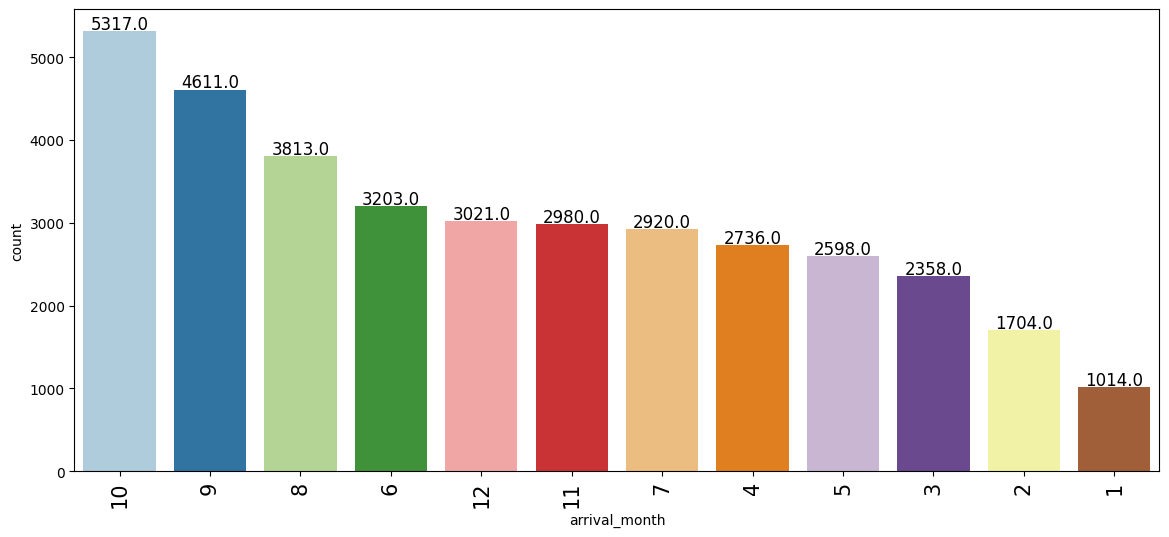

               count percentage
arrival_month                  
10              5317      14.7%
9               4611      12.7%
8               3813      10.5%
6               3203       8.8%
12              3021       8.3%
11              2980       8.2%
7               2920       8.0%
4               2736       7.5%
5               2598       7.2%
3               2358       6.5%
2               1704       4.7%
1               1014       2.8%


In [31]:
#C30
# What are the busiest months?
labeled_barplot(df, "arrival_month")

####2. Which market segment do most of the guests come from?
   The largest share of the market (64%) comes from online.
   * The smallest (0.3%) is from Aviation.


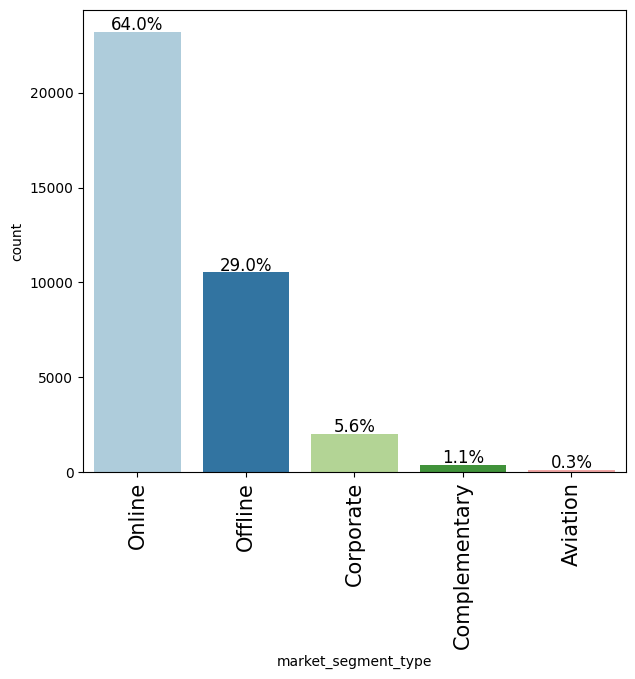

                     count percentage
market_segment_type                  
Online               23214      64.0%
Offline              10528      29.0%
Corporate             2017       5.6%
Complementary          391       1.1%
Aviation               125       0.3%


In [32]:
#C31
# Which market segment do most guests come from?
labeled_barplot(df, "market_segment_type", perc=True)

####3. Room prices differ by market segment. Price is euros per room-day.

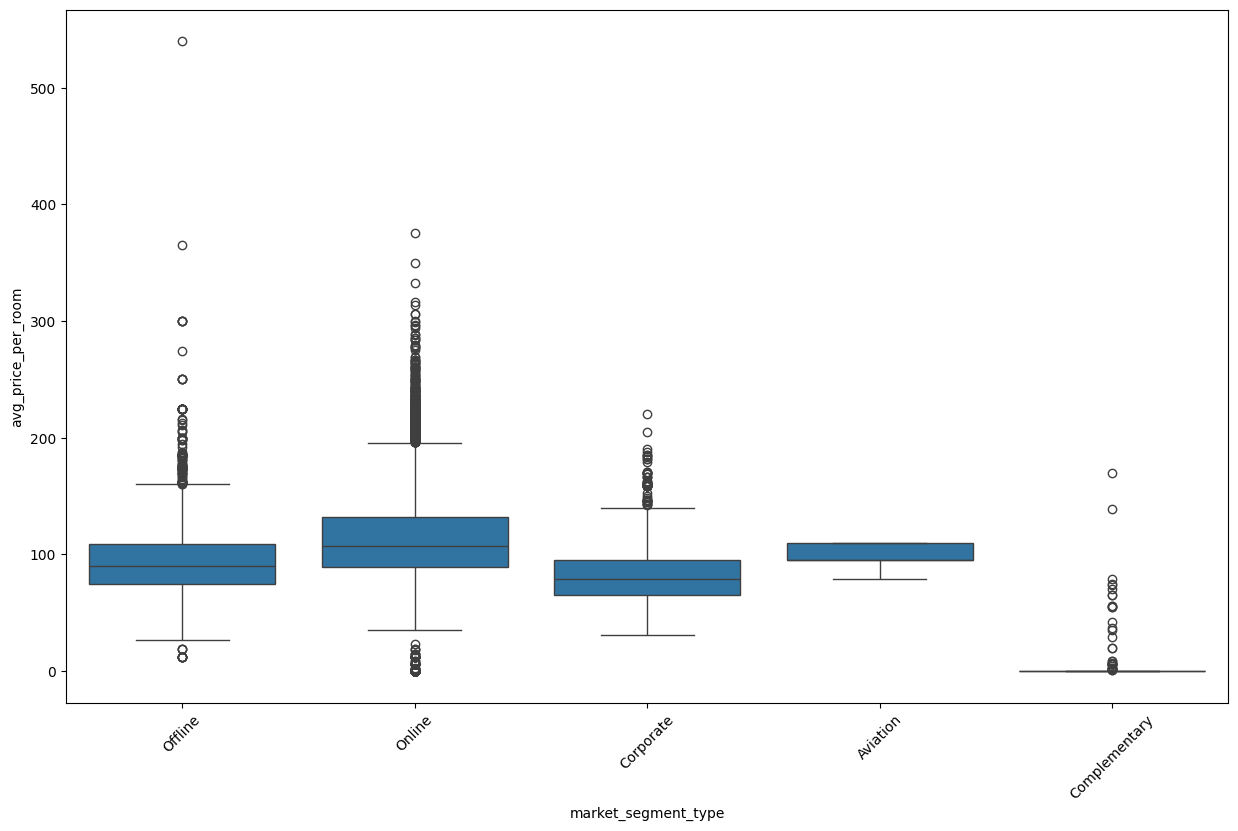

  market_segment_type  count      mean      std      min     my25      my50      my75       max      pct
0             Offline  10528  91.63268 24.99560 12.00000 75.00000  90.00000 109.00000 540.00000 29.02274
1              Online  23214 112.25685 35.22032  0.00000 89.00000 107.10000 131.75000 375.50000 63.99449
2           Corporate   2017  82.91174 23.69000 31.00000 65.00000  79.00000  95.00000 220.00000  5.56030
3            Aviation    125 100.70400  8.53836 79.00000 95.00000  95.00000 110.00000 110.00000  0.34459
4       Complementary    391   3.14176 15.51297  0.00000  0.00000   0.00000   0.00000 170.00000  1.07788


In [33]:
#C32
# Room price by market segment. Price is euros per room-day.
category_boxplot(df, "market_segment_type", "avg_price_per_room")
print(category_pivot(df, "market_segment_type", "avg_price_per_room").to_string())

####4. What percentage of bookings are canceled?
  Online is the largest segment (C31: 64 percent). Price comparisons wait on this pivot.


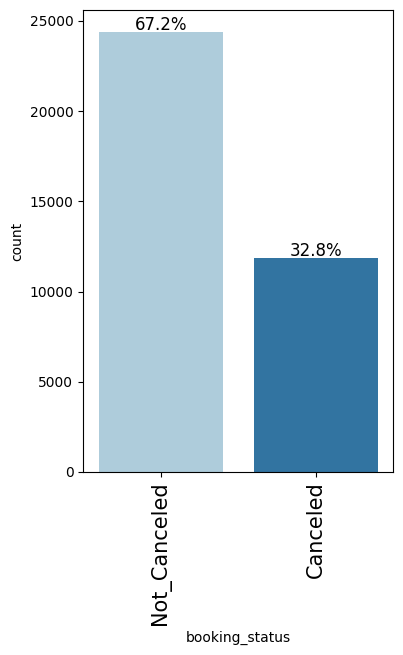

                count percentage
booking_status                  
Not_Canceled    24390      67.2%
Canceled        11885      32.8%


In [34]:
#C33
# What percentage of bookings are canceled?
labeled_barplot(df, "booking_status", perc=True)

####5. Repeating guests are the guests who stay in the hotel often and are important to brand equity. What percentage of repeating guests cancel?
  * out of 930 recurring only 16 canceled 16/930 is 1.7%




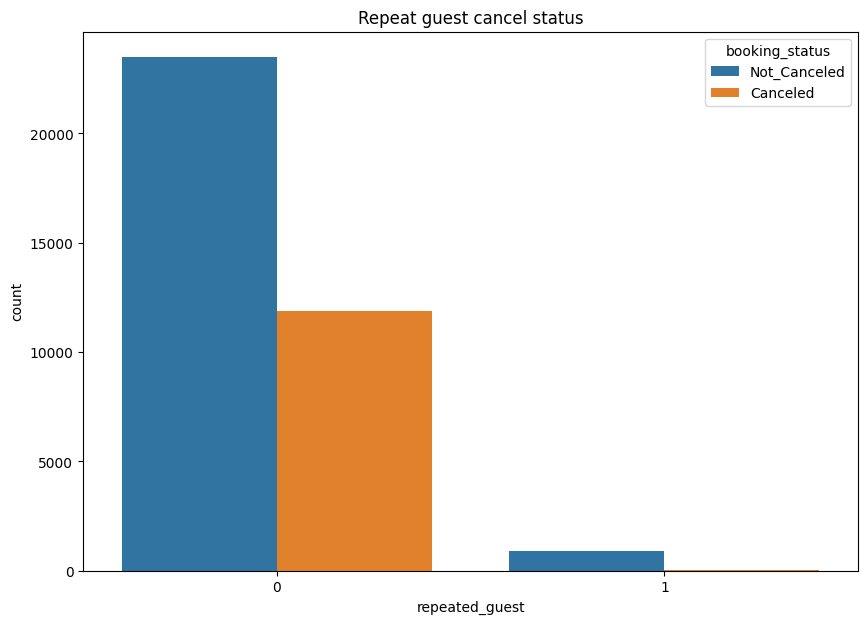

booking_status  Canceled  Not_Canceled
repeated_guest                        
0                  11869         23476
1                     16           914


In [35]:
#C34
# What percentage of repeating guests cancel?
plt.figure(figsize=(10, 7))
plt.title("Repeat guest cancel status")
sns.countplot(data=df, x="repeated_guest", hue="booking_status")
plt.xlabel("repeated_guest")
plt.show()

repeat_cancel = pd.crosstab(df["repeated_guest"], df["booking_status"])
print(repeat_cancel.to_string())

####6. Many guests have special requirements when booking a hotel room. Do these requirements affect booking cancellation?
  * Canceled bookings have fewer special requests than bookings that are kept:.

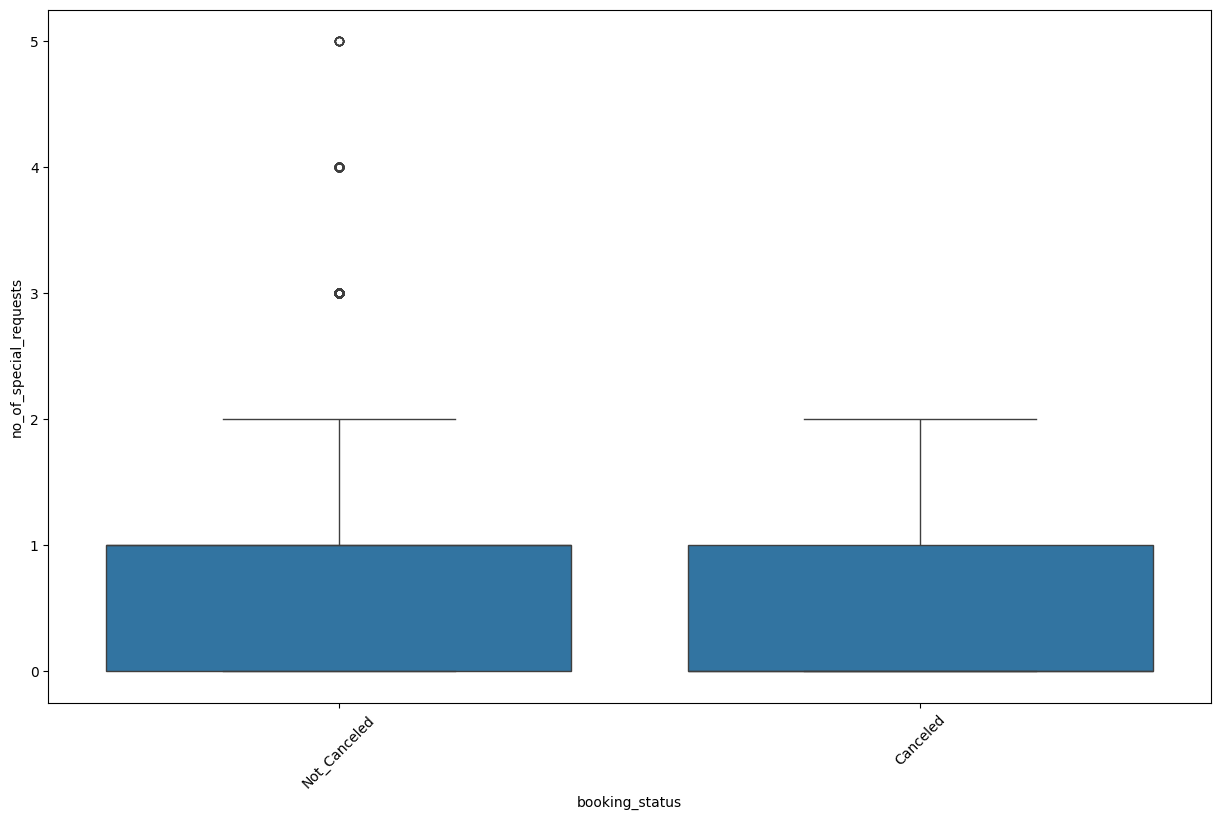

  booking_status  count    mean     std  min    my25    my50    my75  max      pct
0   Not_Canceled  24390 0.75855 0.83653    0 0.00000 1.00000 1.00000    5 67.23639
1       Canceled  11885 0.33462 0.57435    0 0.00000 0.00000 1.00000    2 32.76361


In [36]:
#C35
# Do special requests differ by booking status?
category_boxplot(df, cat="booking_status", num="no_of_special_requests")
print(category_pivot(df, "booking_status", "no_of_special_requests").to_string())

In [ ]:
#C36
## Data Preprocessing
# Missing values: none. No fill.
# Outliers parked, not treated: 0 adults, 10 children, 0 euros.
# Booking_ID drops at the modeling step, not here.
# Room type and arrival month stay until their bivariate plots.

## Data Preprocessing

- Missing value treatment (if needed)
  * **There are no missing values**

- Outlier detection and treatment (if needed)
  * Three values are  parked: 0 adults, 10 children, 0 euros. Leave untreated until that heading shows they are errors


In [37]:
#C36
# drop Booking_ID because it is an identiy key... it adds no value.
# df.drop(labels='Booking_ID', axis=1, inplace=True)


Univariate: type_of_meal_plan


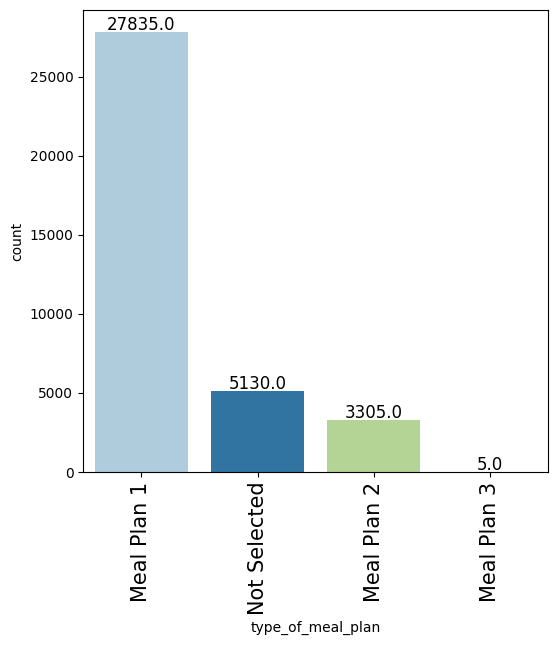

                   count percentage
type_of_meal_plan                  
Meal Plan 1        27835      76.7%
Not Selected        5130      14.1%
Meal Plan 2         3305       9.1%
Meal Plan 3            5       0.0%
type_of_meal_plan has 4 levels


Univariate: room_type_reserved


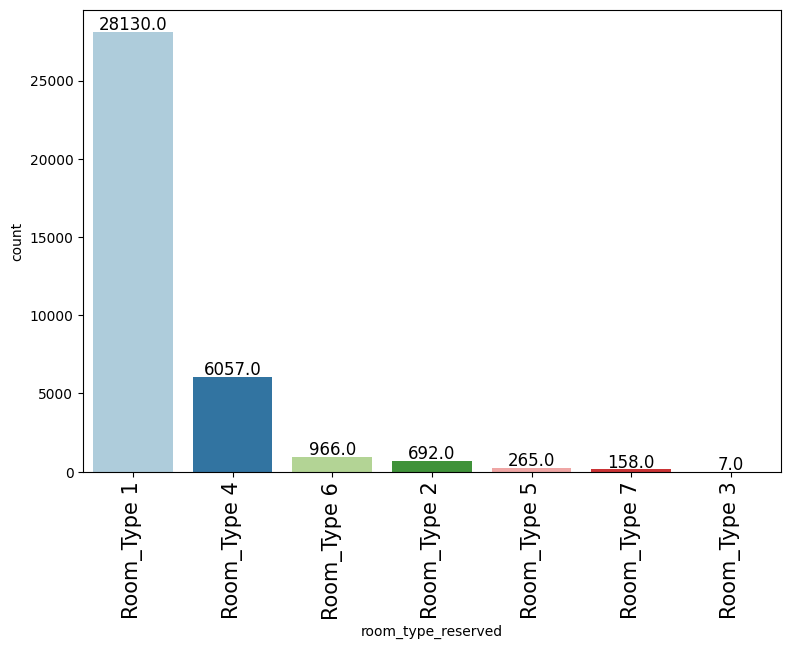

                    count percentage
room_type_reserved                  
Room_Type 1         28130      77.5%
Room_Type 4          6057      16.7%
Room_Type 6           966       2.7%
Room_Type 2           692       1.9%
Room_Type 5           265       0.7%
Room_Type 7           158       0.4%
Room_Type 3             7       0.0%
room_type_reserved has 7 levels


Univariate: market_segment_type


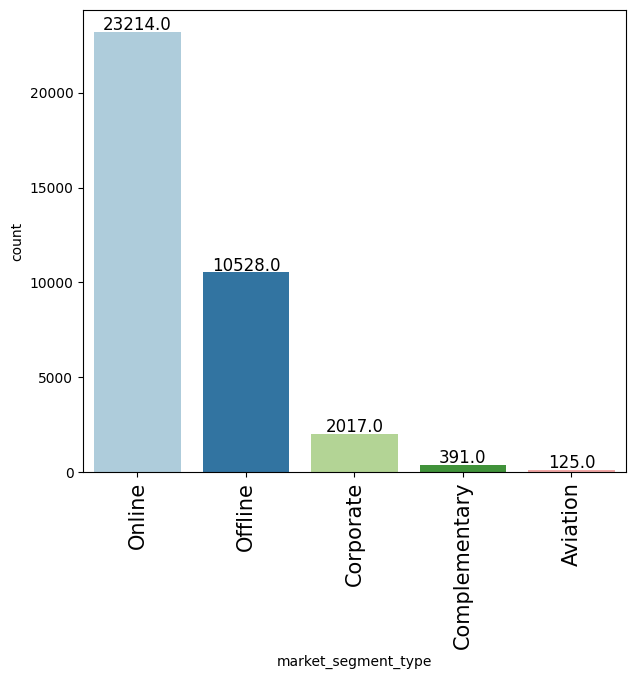

                     count percentage
market_segment_type                  
Online               23214      64.0%
Offline              10528      29.0%
Corporate             2017       5.6%
Complementary          391       1.1%
Aviation               125       0.3%
market_segment_type has 5 levels


Univariate: booking_status


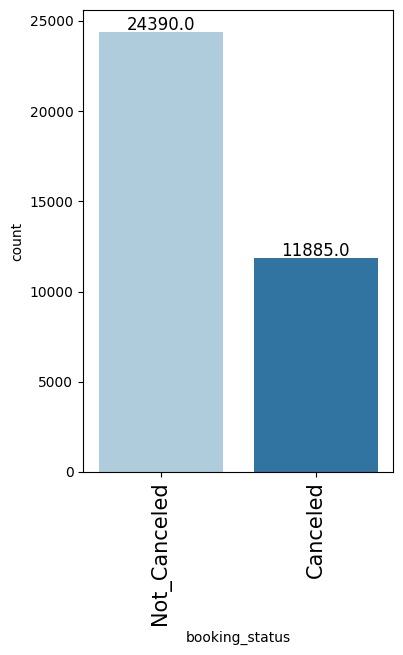

                count percentage
booking_status                  
Not_Canceled    24390      67.2%
Canceled        11885      32.8%
booking_status has 2 levels



In [38]:
#C37
# Univariate sweep. No cast.
sweep_categories = [
    "type_of_meal_plan",
    "room_type_reserved",
    "market_segment_type",
    "booking_status",
]
for col in sweep_categories:
    print("\nUnivariate:", col)
    labeled_barplot(df, col)
    print(col, "has", df[col].nunique(), "levels\n")

14 numeric columns

Univariate: no_of_adults


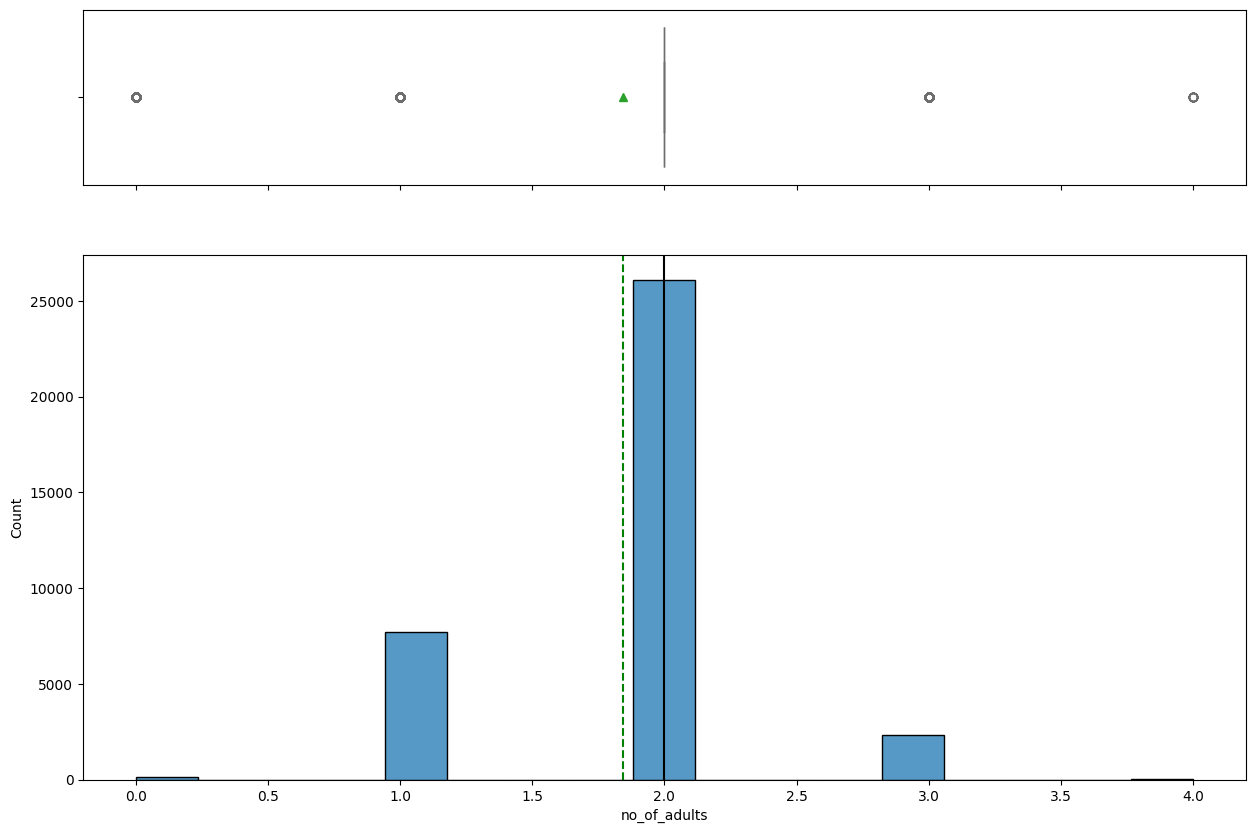

count   36275.00000
mean        1.84496
std         0.51871
min         0.00000
25%         2.00000
50%         2.00000
75%         2.00000
max         4.00000

Univariate: no_of_children


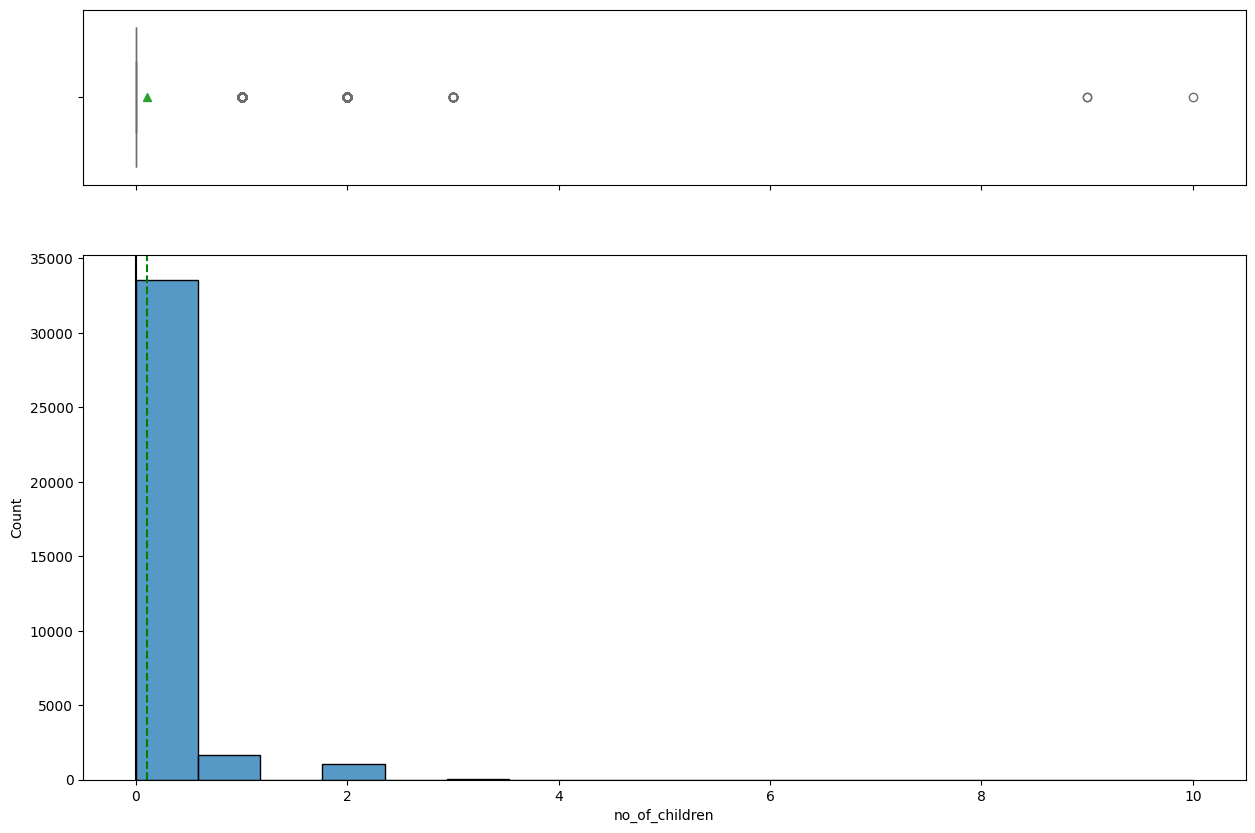

count   36275.00000
mean        0.10528
std         0.40265
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max        10.00000

Univariate: no_of_weekend_nights


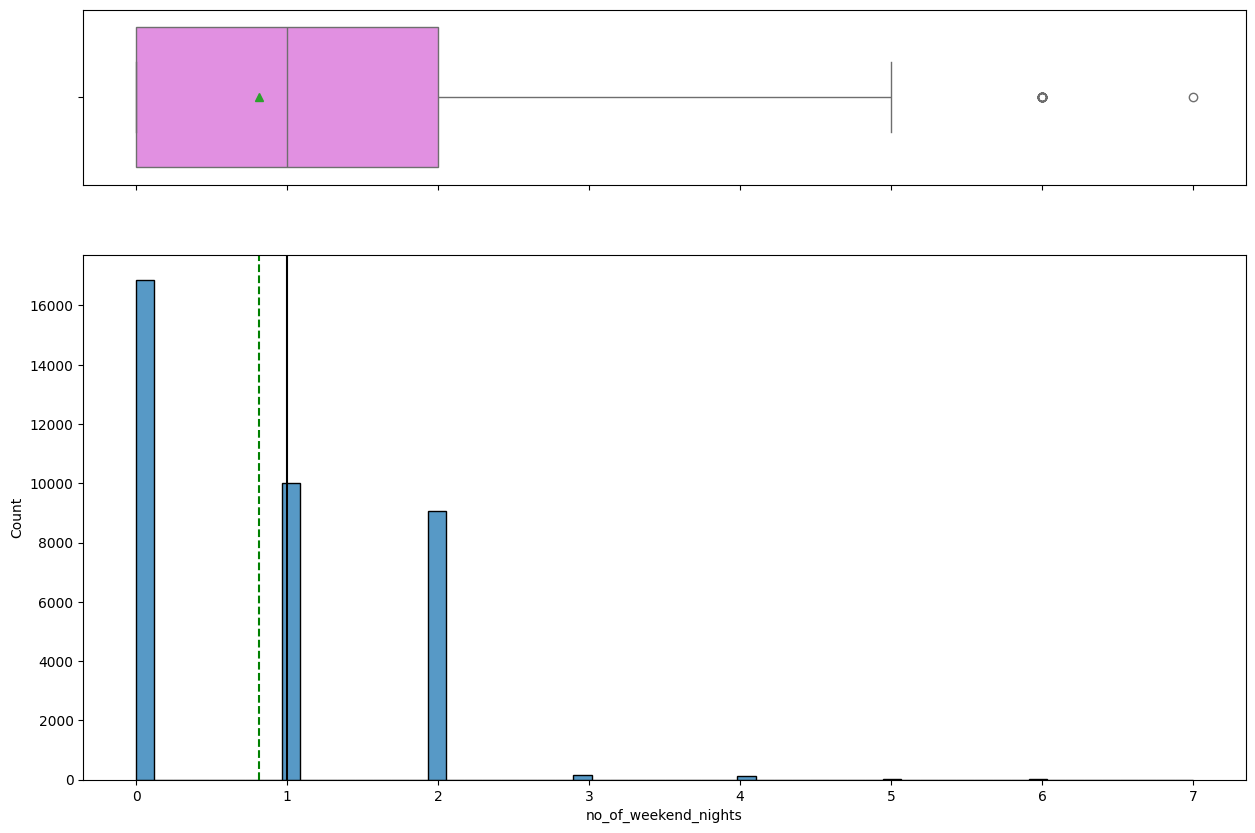

count   36275.00000
mean        0.81072
std         0.87064
min         0.00000
25%         0.00000
50%         1.00000
75%         2.00000
max         7.00000

Univariate: no_of_week_nights


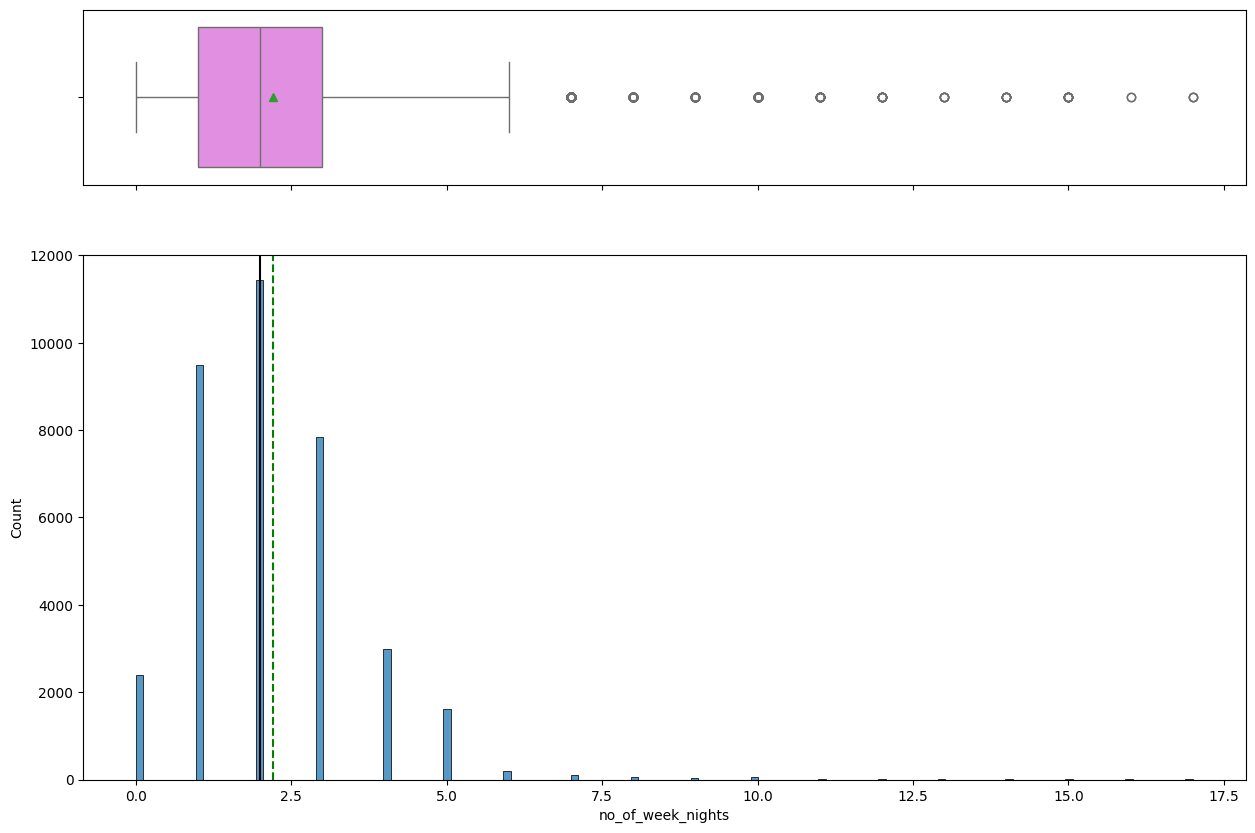

count   36275.00000
mean        2.20430
std         1.41090
min         0.00000
25%         1.00000
50%         2.00000
75%         3.00000
max        17.00000

Univariate: required_car_parking_space


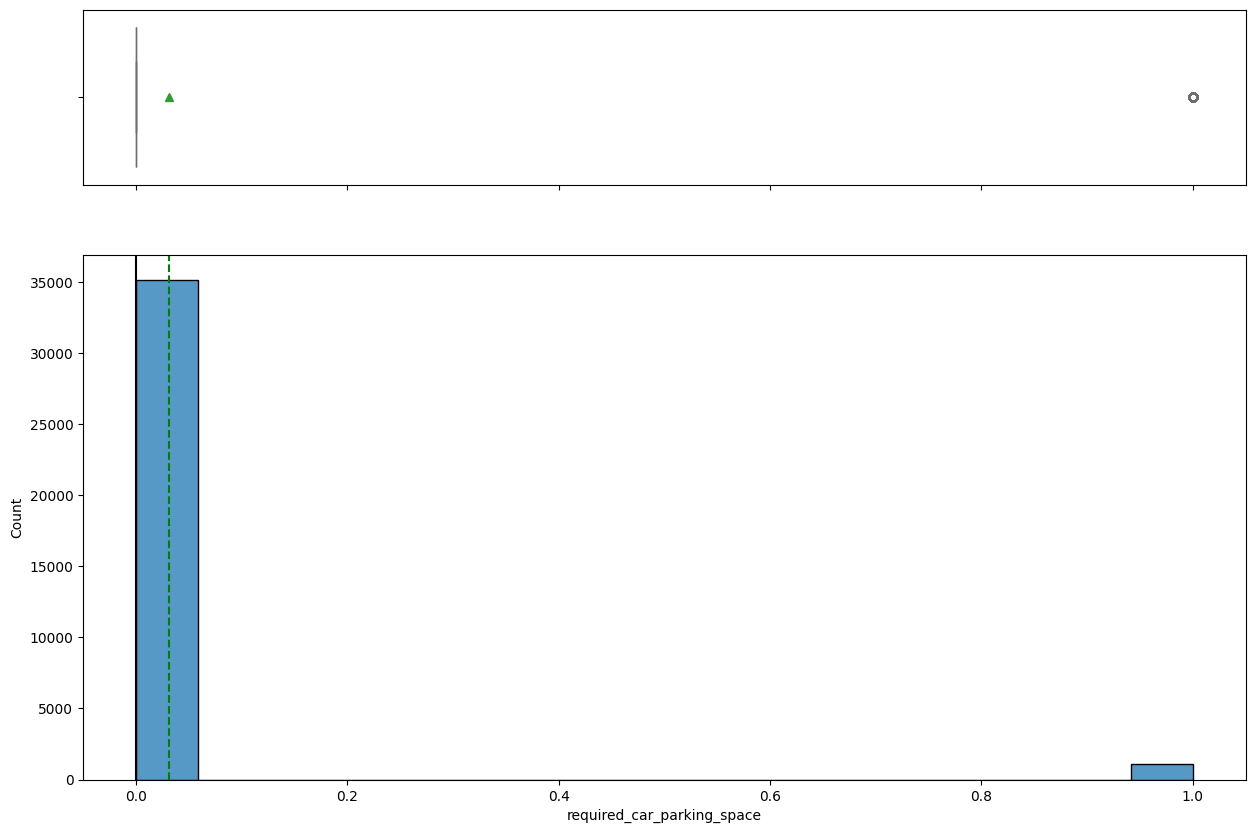

count   36275.00000
mean        0.03099
std         0.17328
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max         1.00000

Univariate: lead_time


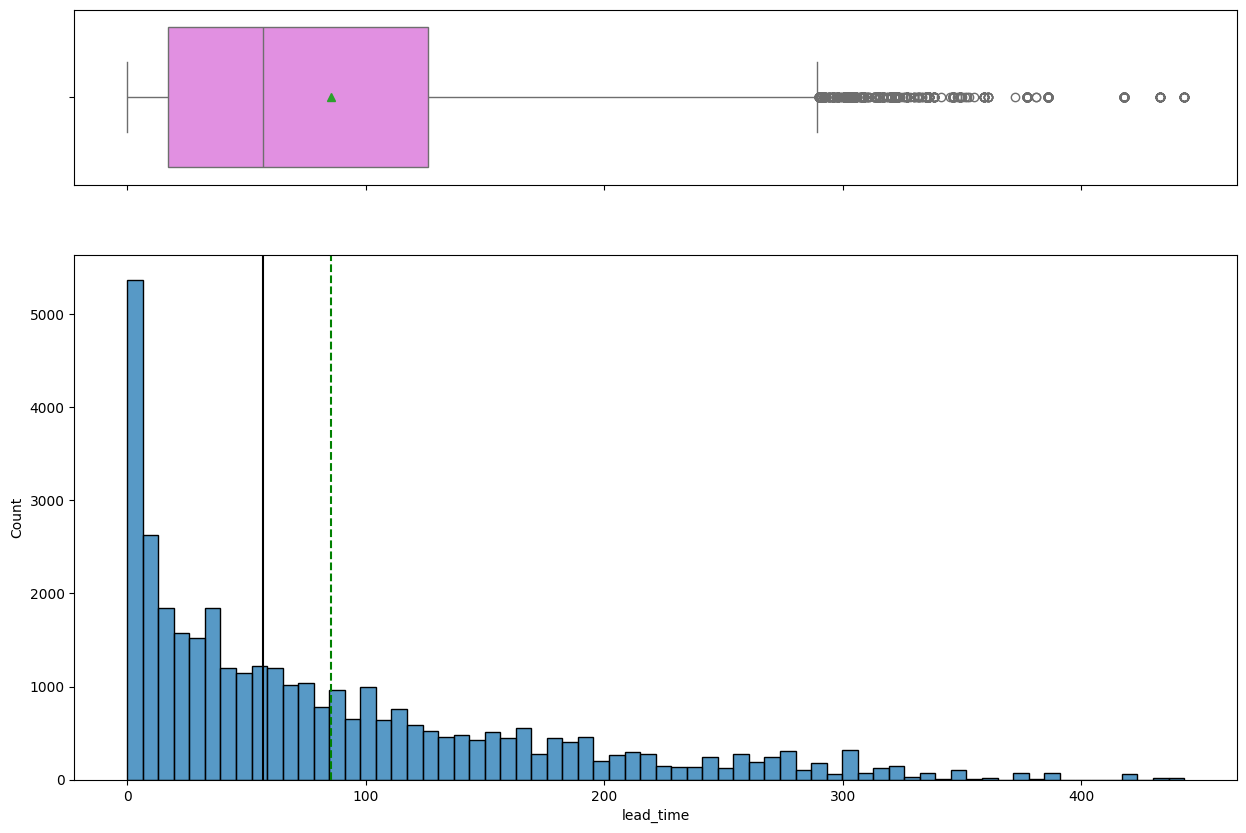

count   36275.00000
mean       85.23256
std        85.93082
min         0.00000
25%        17.00000
50%        57.00000
75%       126.00000
max       443.00000

Univariate: arrival_year


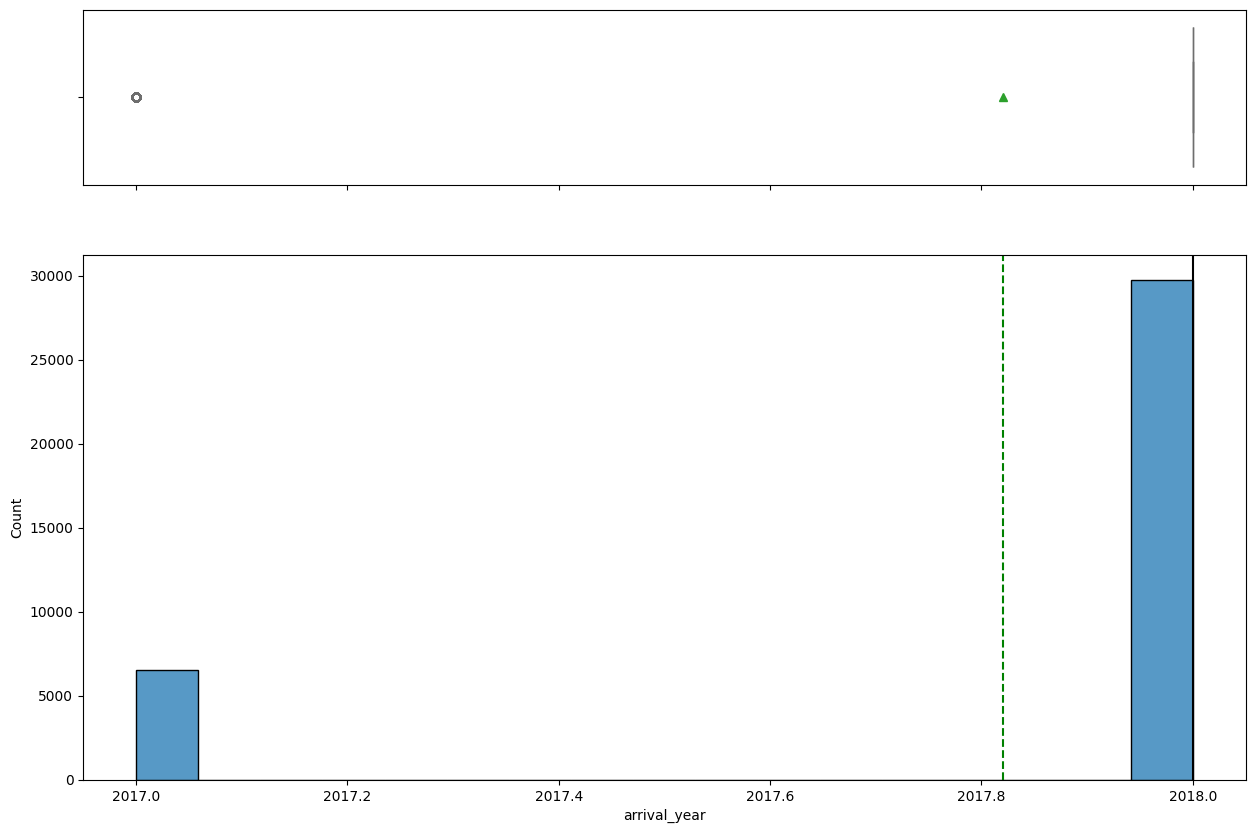

count   36275.00000
mean     2017.82043
std         0.38384
min      2017.00000
25%      2018.00000
50%      2018.00000
75%      2018.00000
max      2018.00000

Univariate: arrival_month


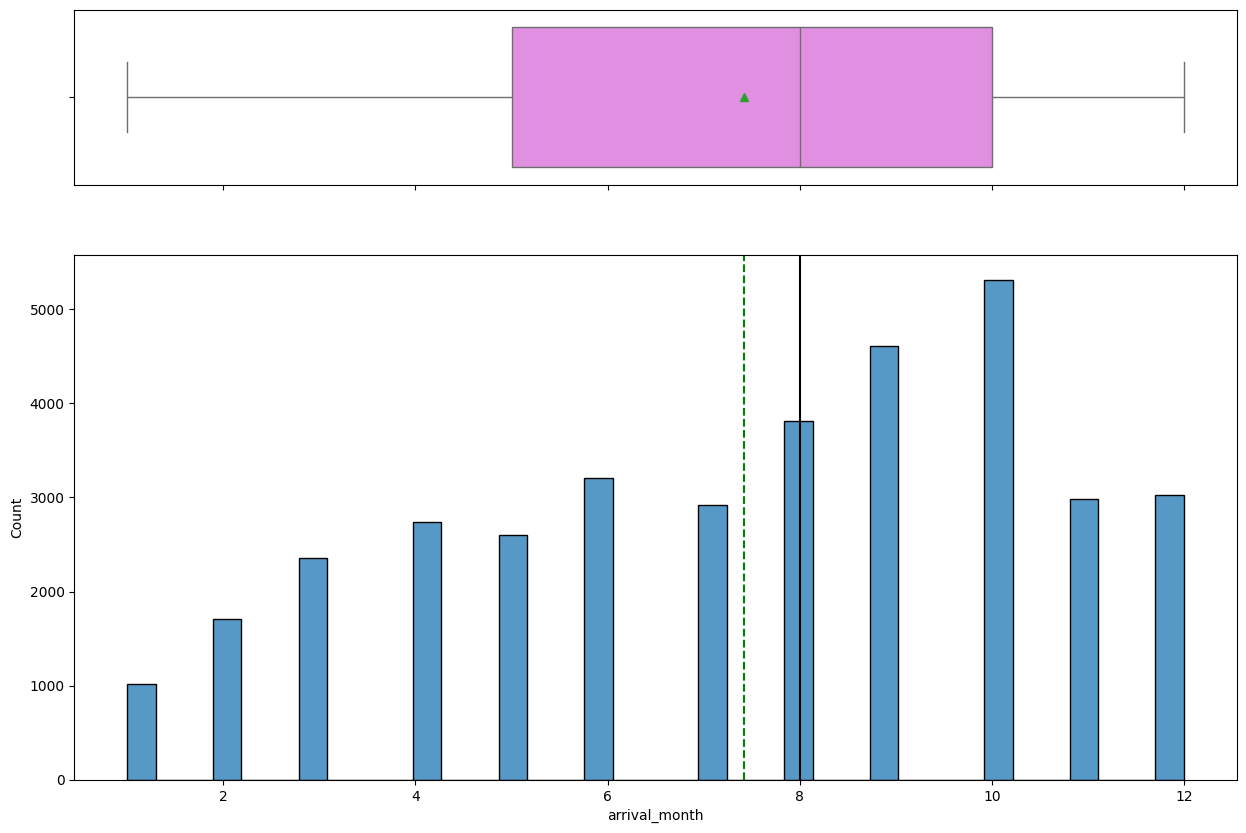

count   36275.00000
mean        7.42365
std         3.06989
min         1.00000
25%         5.00000
50%         8.00000
75%        10.00000
max        12.00000

Univariate: arrival_date


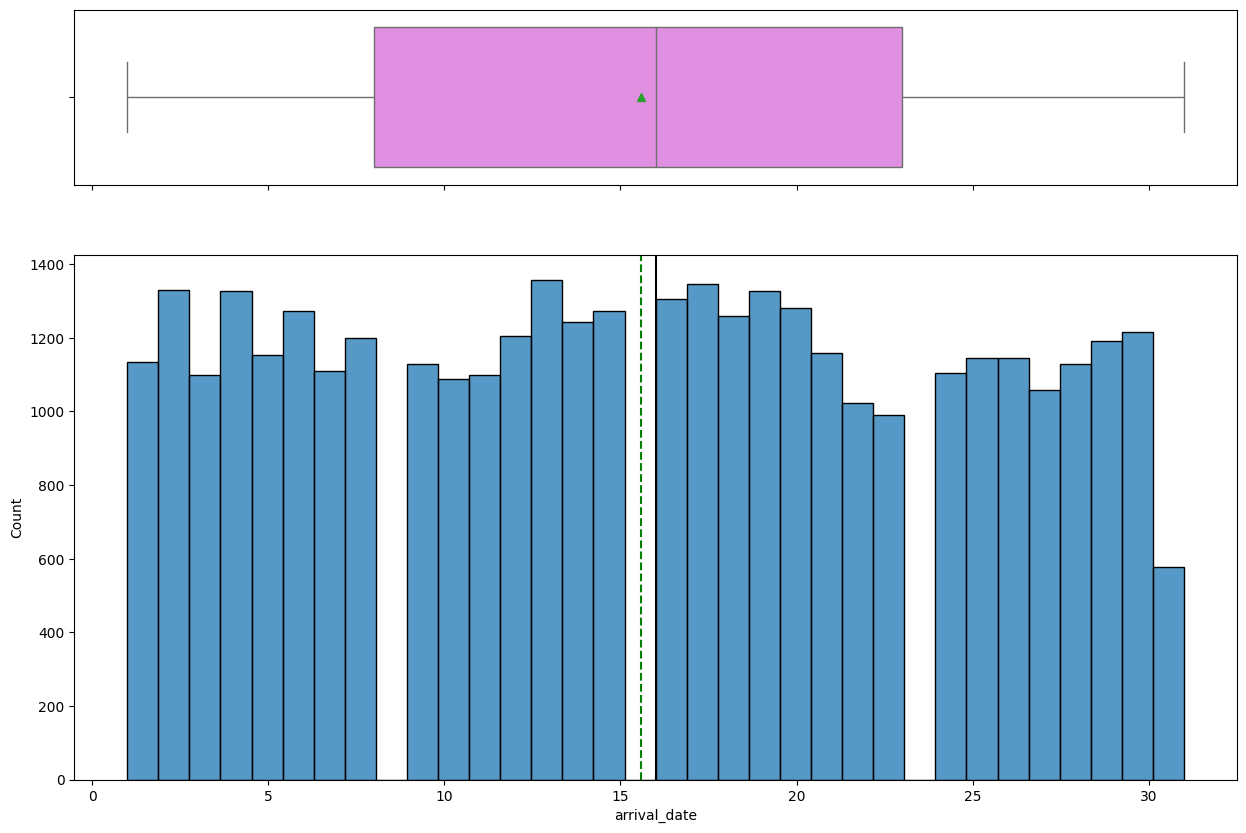

count   36275.00000
mean       15.59700
std         8.74045
min         1.00000
25%         8.00000
50%        16.00000
75%        23.00000
max        31.00000

Univariate: repeated_guest


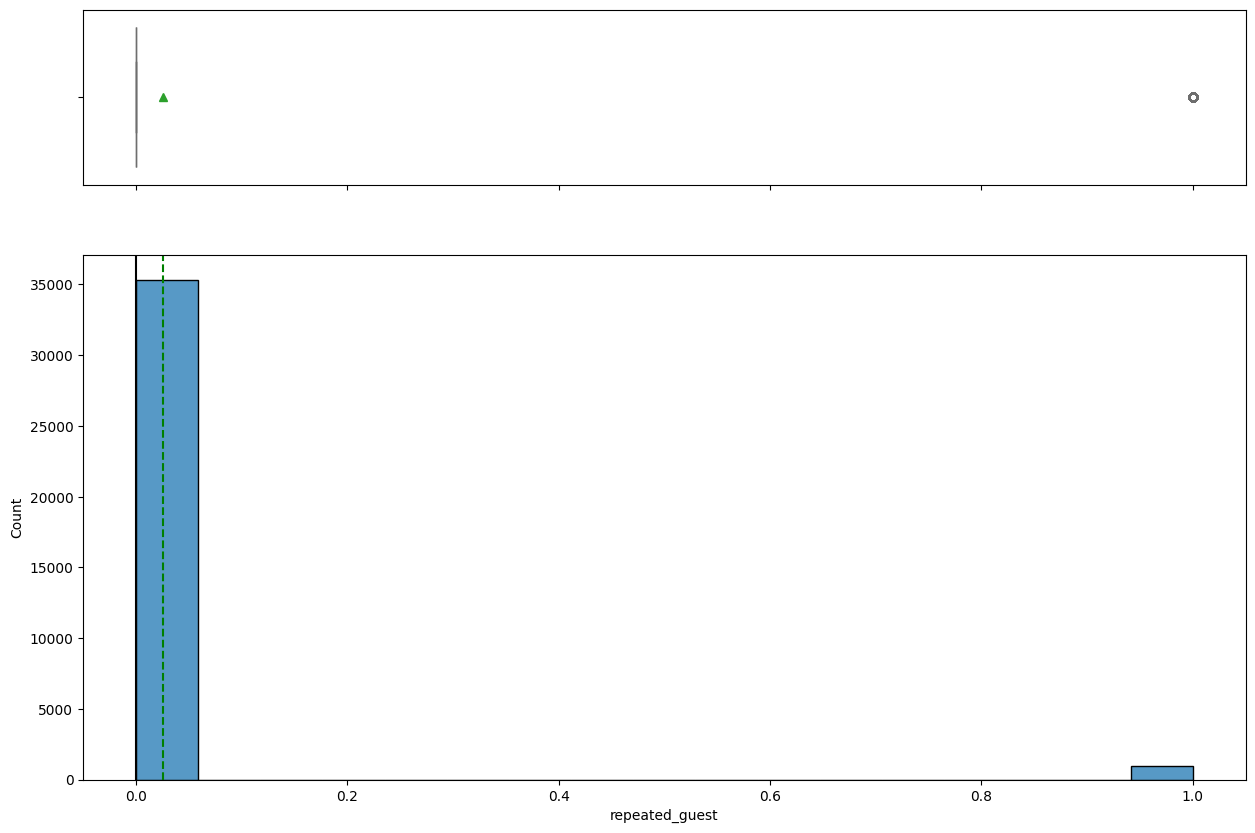

count   36275.00000
mean        0.02564
std         0.15805
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max         1.00000

Univariate: no_of_previous_cancellations


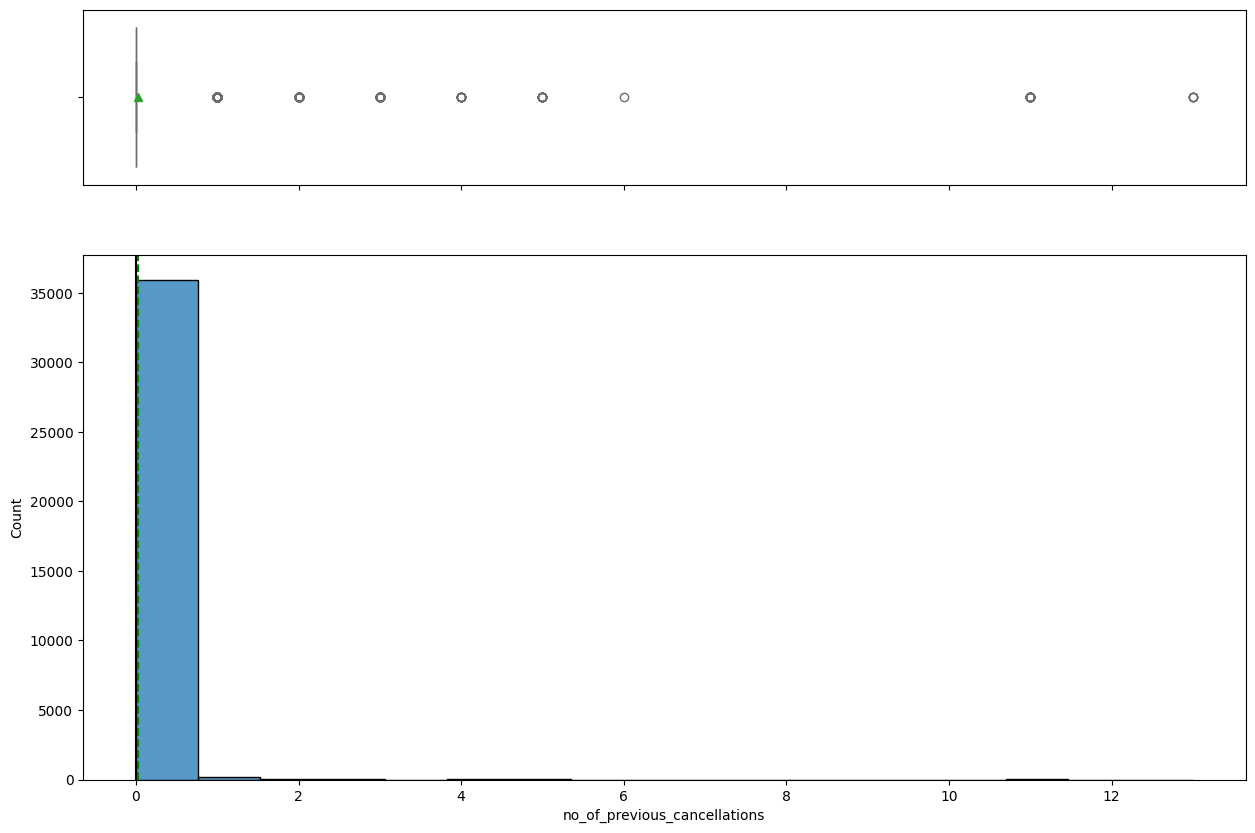

count   36275.00000
mean        0.02335
std         0.36833
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max        13.00000

Univariate: no_of_previous_bookings_not_canceled


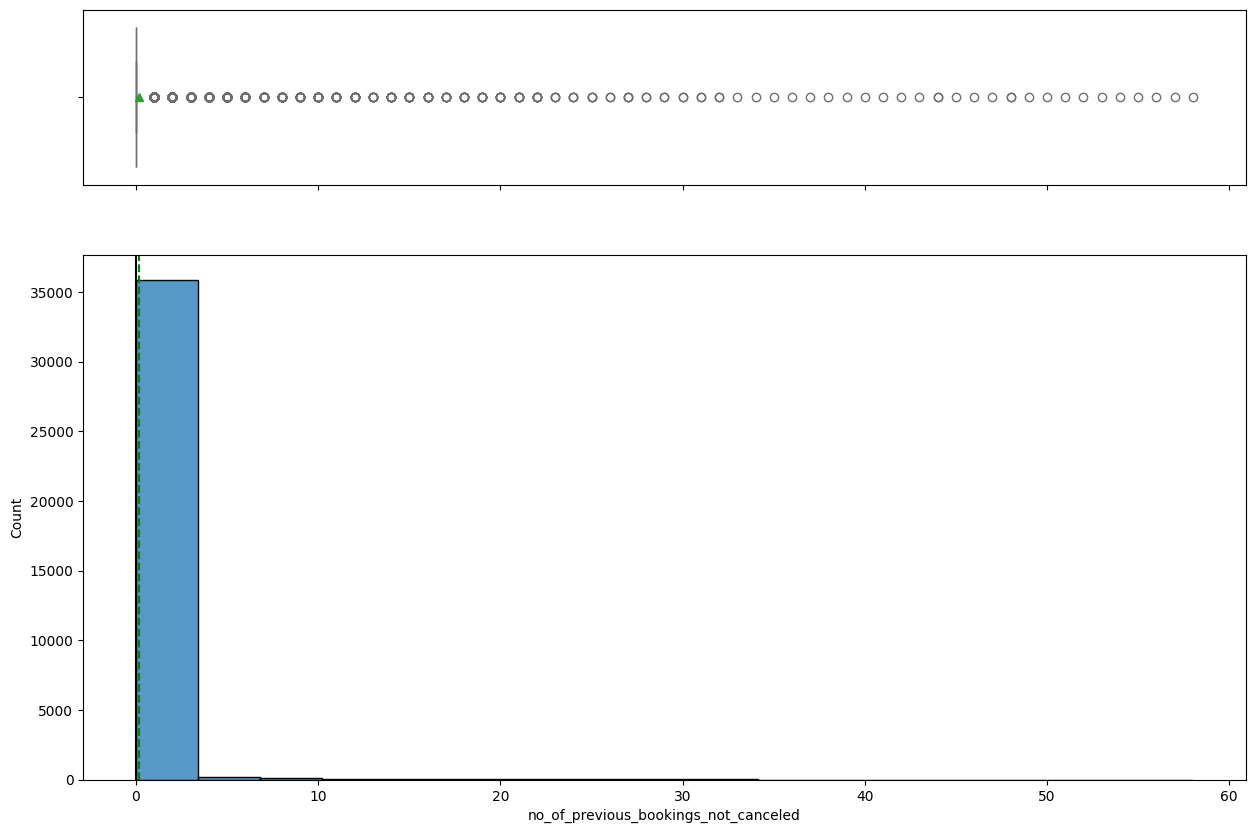

count   36275.00000
mean        0.15341
std         1.75417
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max        58.00000

Univariate: no_of_special_requests


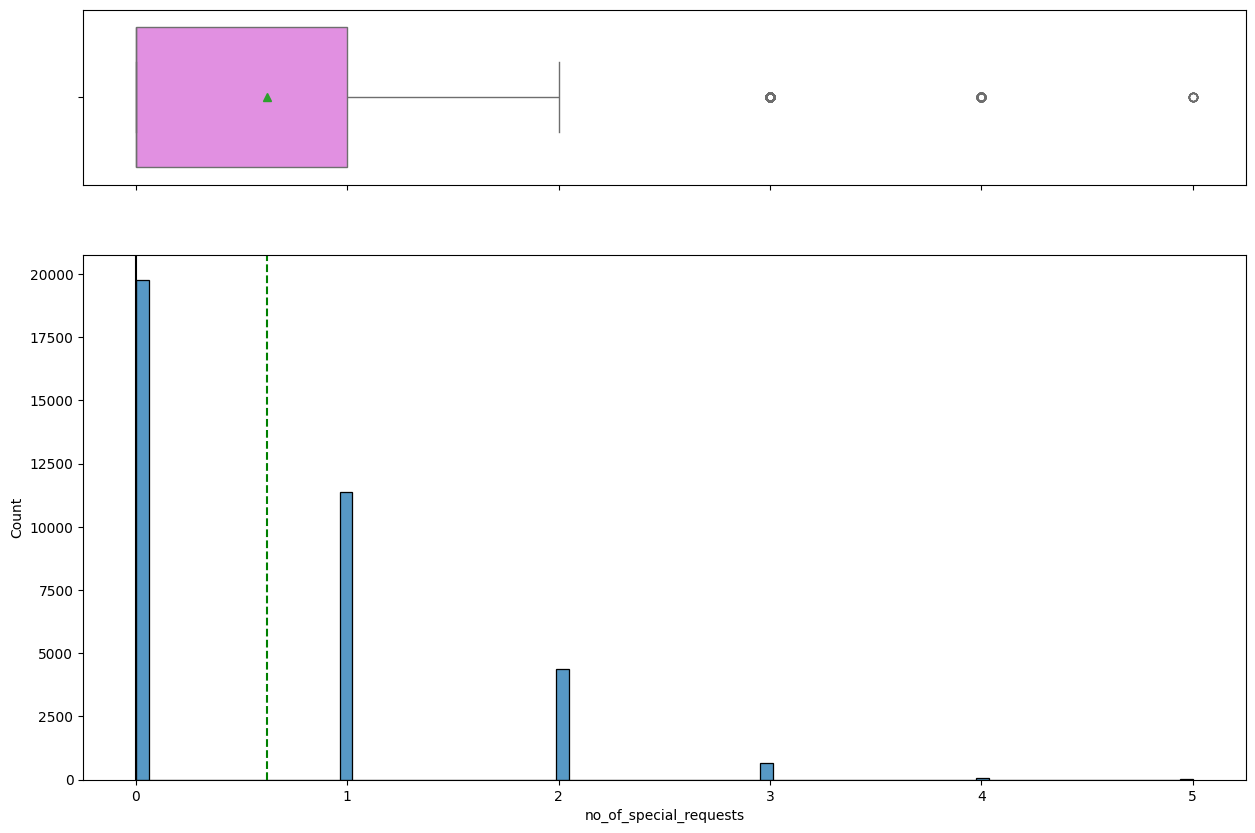

count   36275.00000
mean        0.61966
std         0.78624
min         0.00000
25%         0.00000
50%         0.00000
75%         1.00000
max         5.00000

Univariate: avg_price_per_room


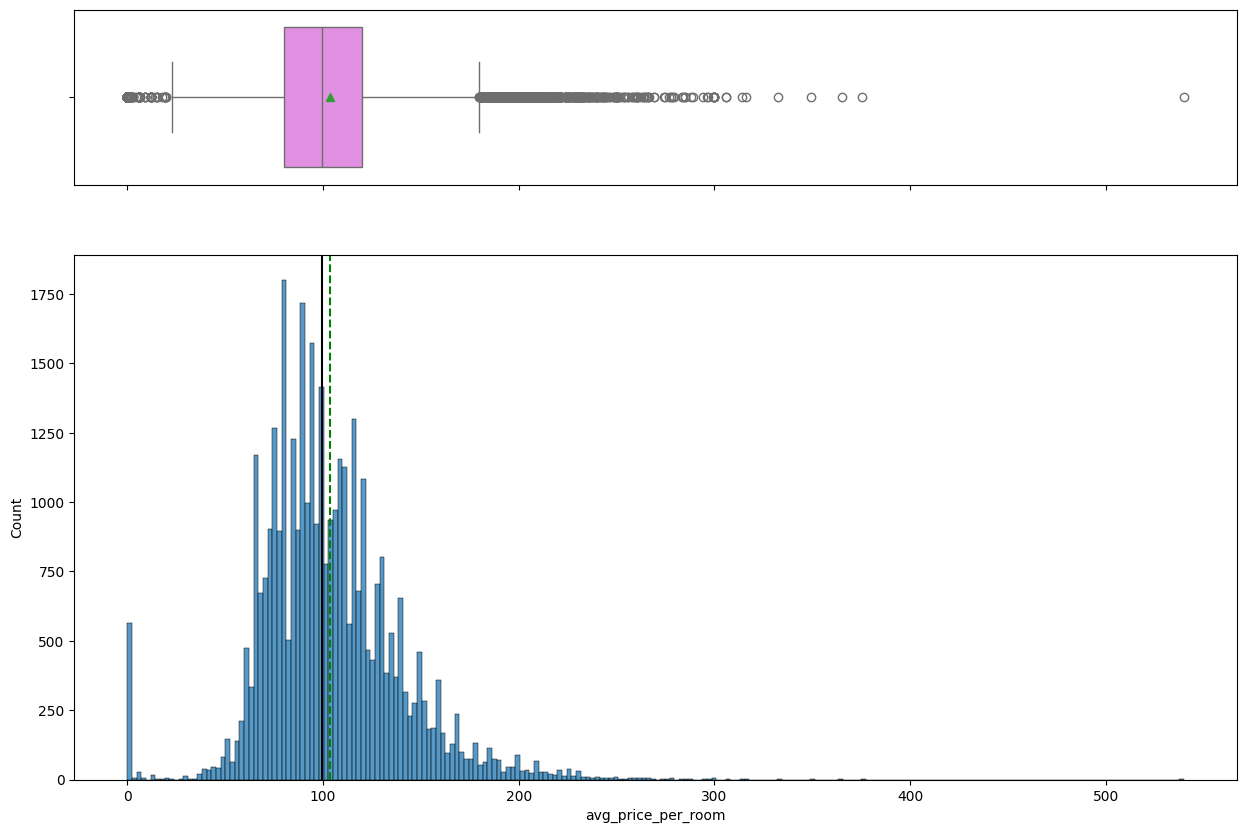

count   36275.00000
mean      103.42354
std        35.08942
min         0.00000
25%        80.30000
50%        99.45000
75%       120.00000
max       540.00000


In [39]:
#C39
print(len(numeric_columns), "numeric columns")
for col in numeric_columns:
    print("\nUnivariate:", col)
    histogram_boxplot(df, col)

In [40]:
#C40
#  Drop *room_type_reserved* because it is ecrypted. We no not know how these values relate to esch other or the dataset
# df.drop(labels='room_type_reserved', axis=1, inplace=True)

In [41]:
# #C41
# #  Dropping the date fields because we have counters for number of weekday and weekend
# # Also.. while some dates are more popular we cannot correlate this to any events.
# df.drop(labels='arrival_date', axis=1, inplace=True)
# df.drop(labels='arrival_month', axis=1, inplace=True)
# df.drop(labels='arrival_year', axis=1, inplace=True)



In [42]:
# #C42
# # cast  object to category
# for col in df.columns[df.dtypes=='object']:
#     df[col] = df[col].astype('category')

# category_columns = list(df.select_dtypes(['category']).columns)
# len(category_columns)
# print( "The category columns are" , len(category_columns) , category_columns)

In [43]:
#C43
float_columns = list(df.select_dtypes(["float"]).columns)
integer_columns = list(df.select_dtypes(["int"]).columns)
numeric_columns = float_columns + integer_columns
print("The numeric columns are", len(numeric_columns), numeric_columns)

The numeric columns are 14 ['avg_price_per_room', 'no_of_adults', 'no_of_children', 'no_of_weekend_nights', 'no_of_week_nights', 'required_car_parking_space', 'lead_time', 'arrival_year', 'arrival_month', 'arrival_date', 'repeated_guest', 'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled', 'no_of_special_requests']


## EDA

- Explore the data once again after manipulating it.

###UNIVARIATE ANALYSIS

####  for Categoricals :
No significant observations.
No missing values.
There are 8 categoricals.
Note: I am suprised we do not have day of week or weekday versus weekend columns. Will need to discuss the lack of a weekend or weekday varible with the SME.


Univariate: type_of_meal_plan


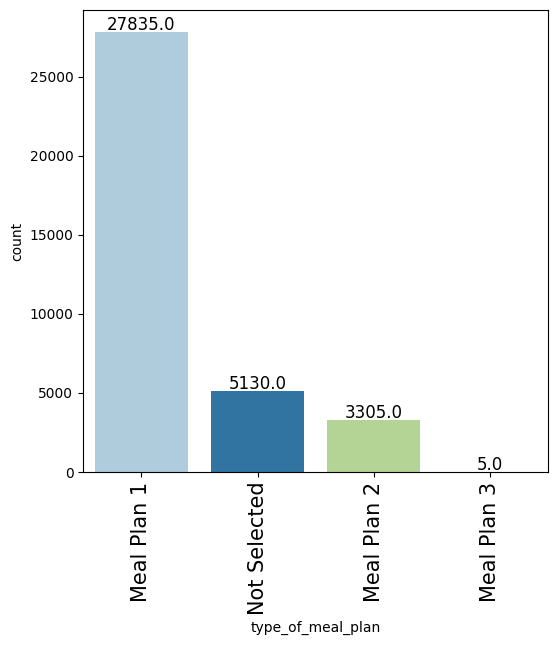

                   count percentage
type_of_meal_plan                  
Meal Plan 1        27835      76.7%
Not Selected        5130      14.1%
Meal Plan 2         3305       9.1%
Meal Plan 3            5       0.0%
type_of_meal_plan has 4 levels


Univariate: room_type_reserved


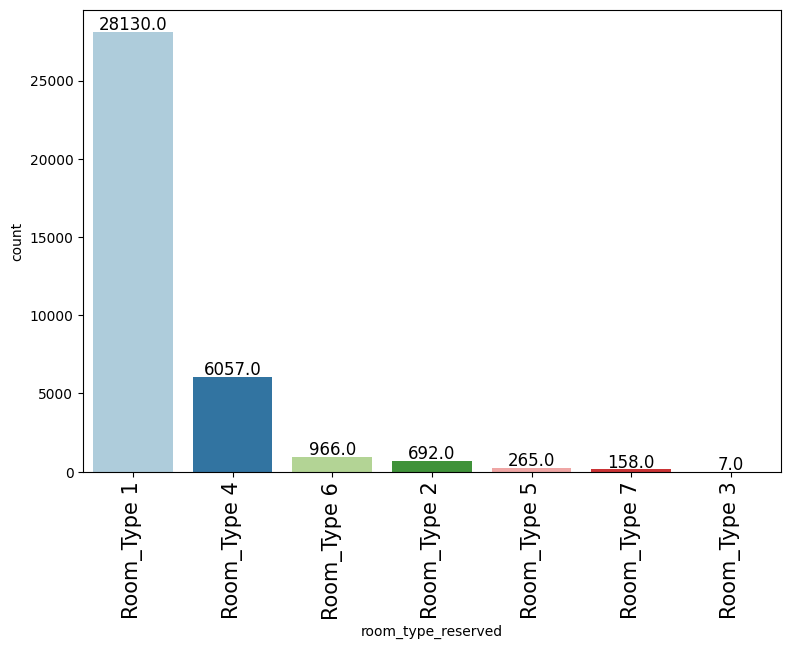

                    count percentage
room_type_reserved                  
Room_Type 1         28130      77.5%
Room_Type 4          6057      16.7%
Room_Type 6           966       2.7%
Room_Type 2           692       1.9%
Room_Type 5           265       0.7%
Room_Type 7           158       0.4%
Room_Type 3             7       0.0%
room_type_reserved has 7 levels


Univariate: market_segment_type


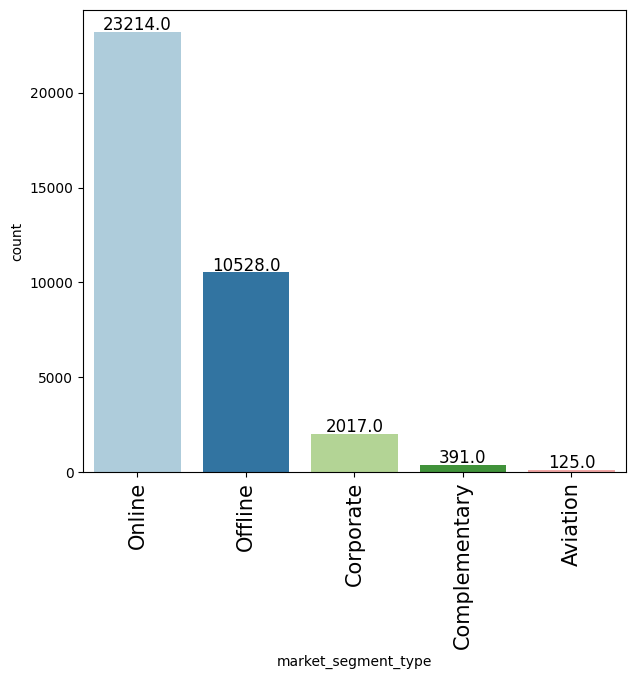

                     count percentage
market_segment_type                  
Online               23214      64.0%
Offline              10528      29.0%
Corporate             2017       5.6%
Complementary          391       1.1%
Aviation               125       0.3%
market_segment_type has 5 levels


Univariate: booking_status


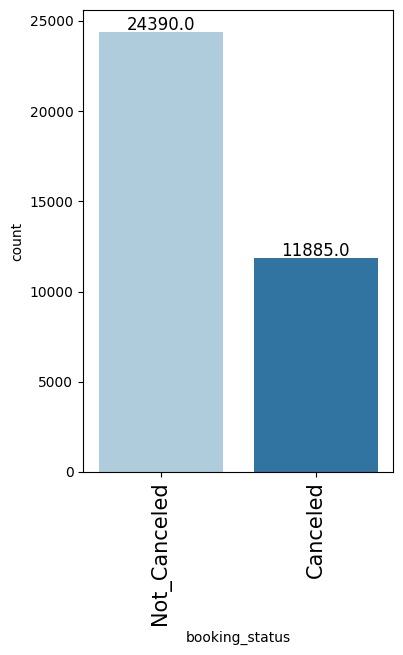

                count percentage
booking_status                  
Not_Canceled    24390      67.2%
Canceled        11885      32.8%
booking_status has 2 levels



In [44]:
#C44
# Univariate sweep. No cast. Booking_ID is an identifier, not a level.
sweep_categories = [
    "type_of_meal_plan",
    "room_type_reserved",
    "market_segment_type",
    "booking_status",
]
for col in sweep_categories:
    print("\nUnivariate:", col)
    labeled_barplot(df, col)
    print(col, "has", df[col].nunique(), "levels\n")

####for Numerics :
No significant observations.
No missing values.
There are 9 numeric columns and while there are outiliers present they to difficult treat as they contain data points required for analysis. I've decided no to treat these outliers.

14 numeric columns

Univariate: avg_price_per_room


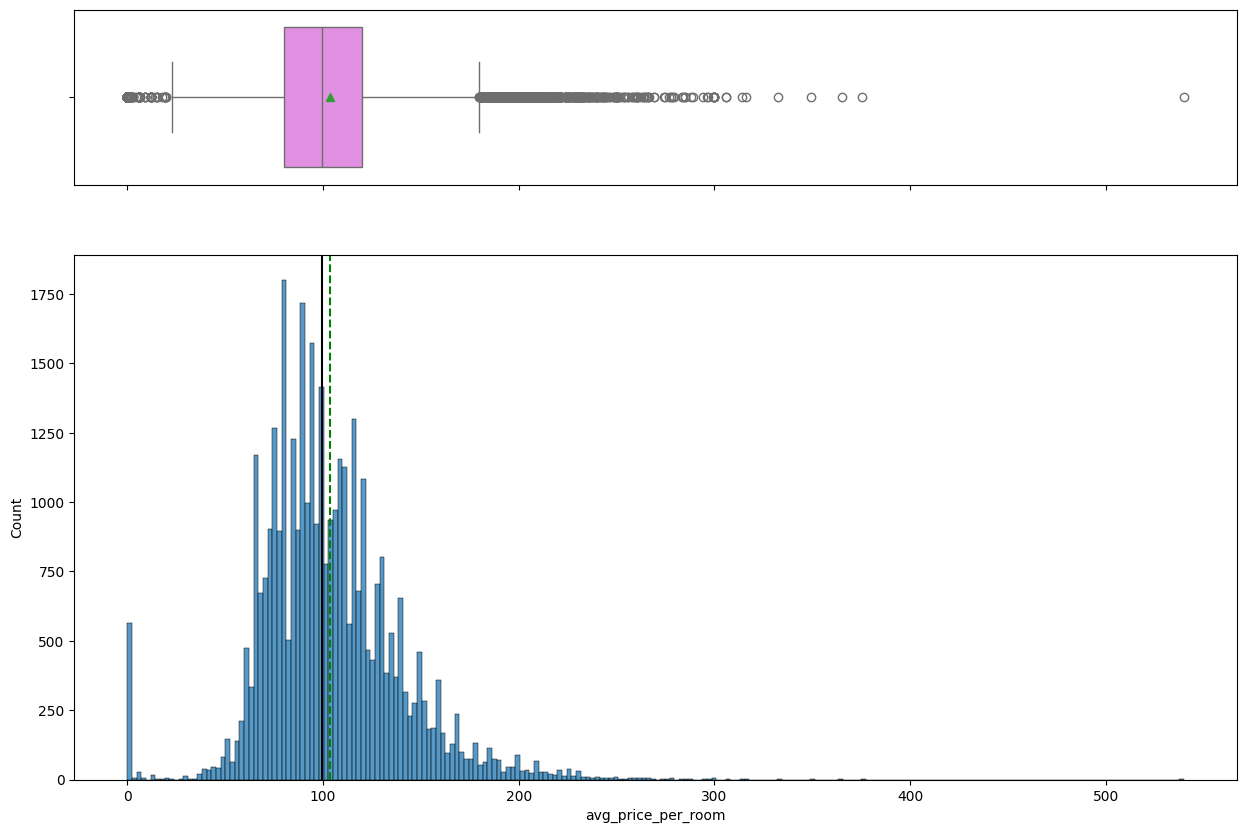

count   36275.00000
mean      103.42354
std        35.08942
min         0.00000
25%        80.30000
50%        99.45000
75%       120.00000
max       540.00000

Univariate: no_of_adults


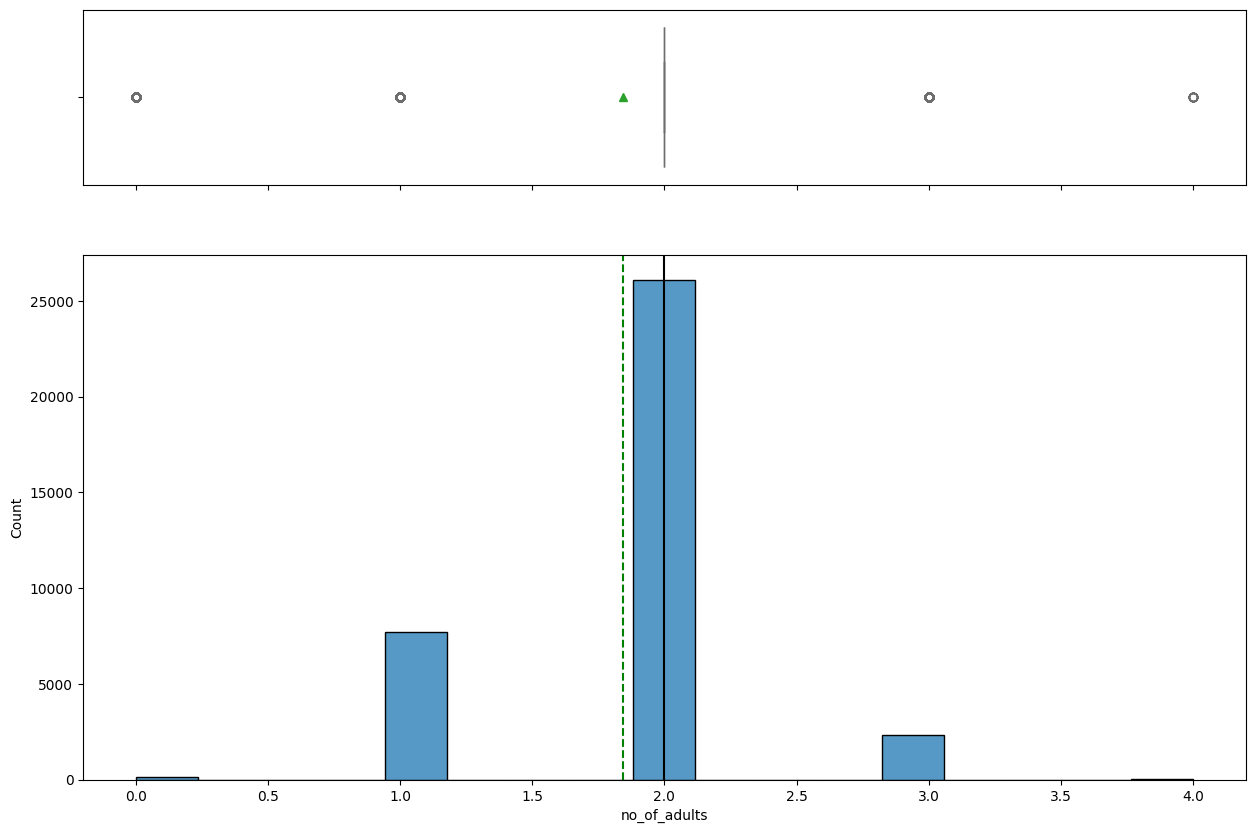

count   36275.00000
mean        1.84496
std         0.51871
min         0.00000
25%         2.00000
50%         2.00000
75%         2.00000
max         4.00000

Univariate: no_of_children


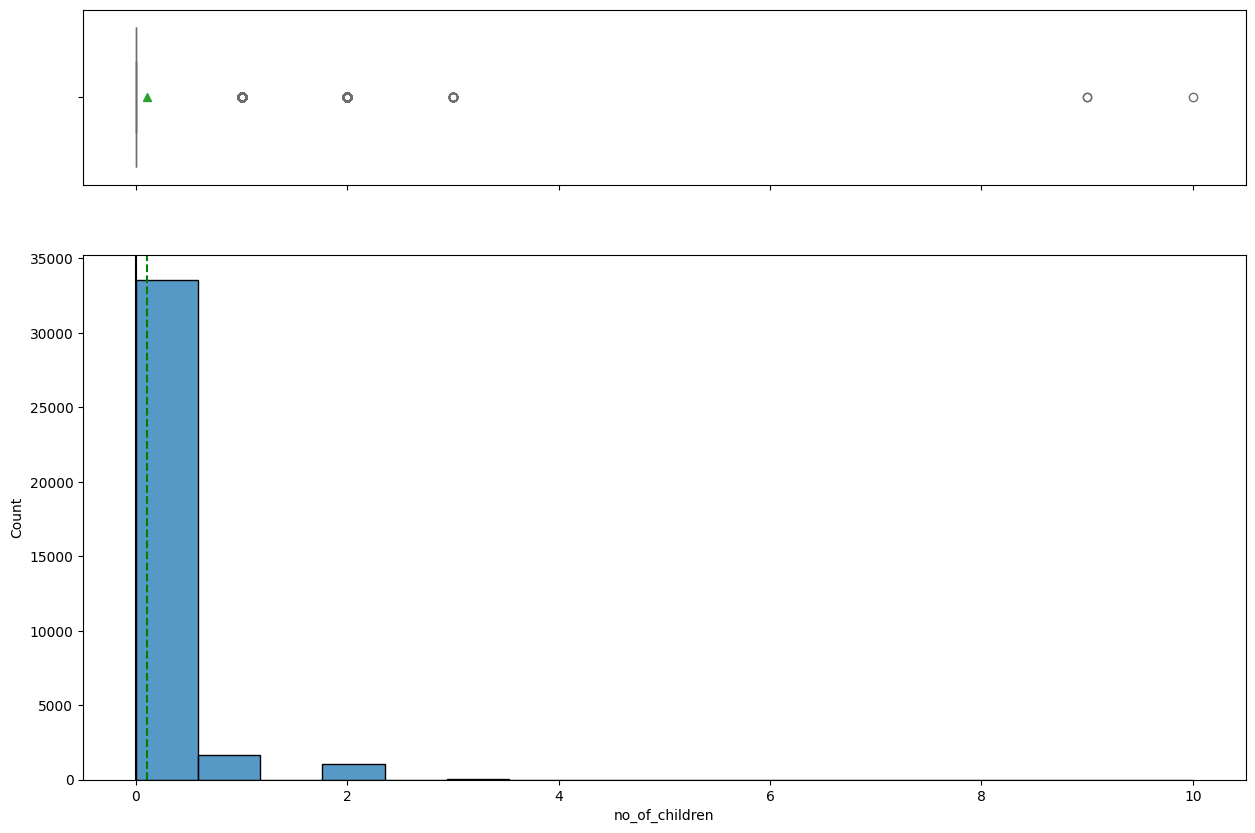

count   36275.00000
mean        0.10528
std         0.40265
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max        10.00000

Univariate: no_of_weekend_nights


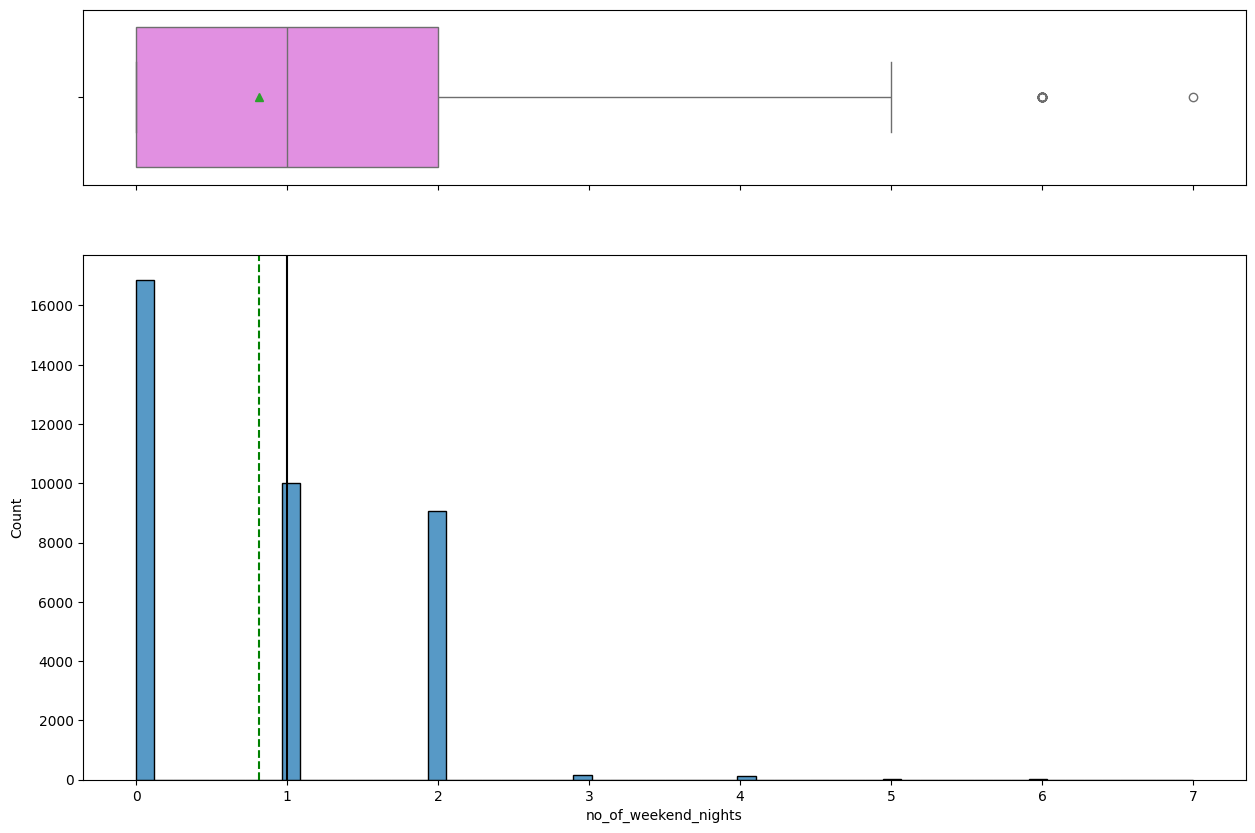

count   36275.00000
mean        0.81072
std         0.87064
min         0.00000
25%         0.00000
50%         1.00000
75%         2.00000
max         7.00000

Univariate: no_of_week_nights


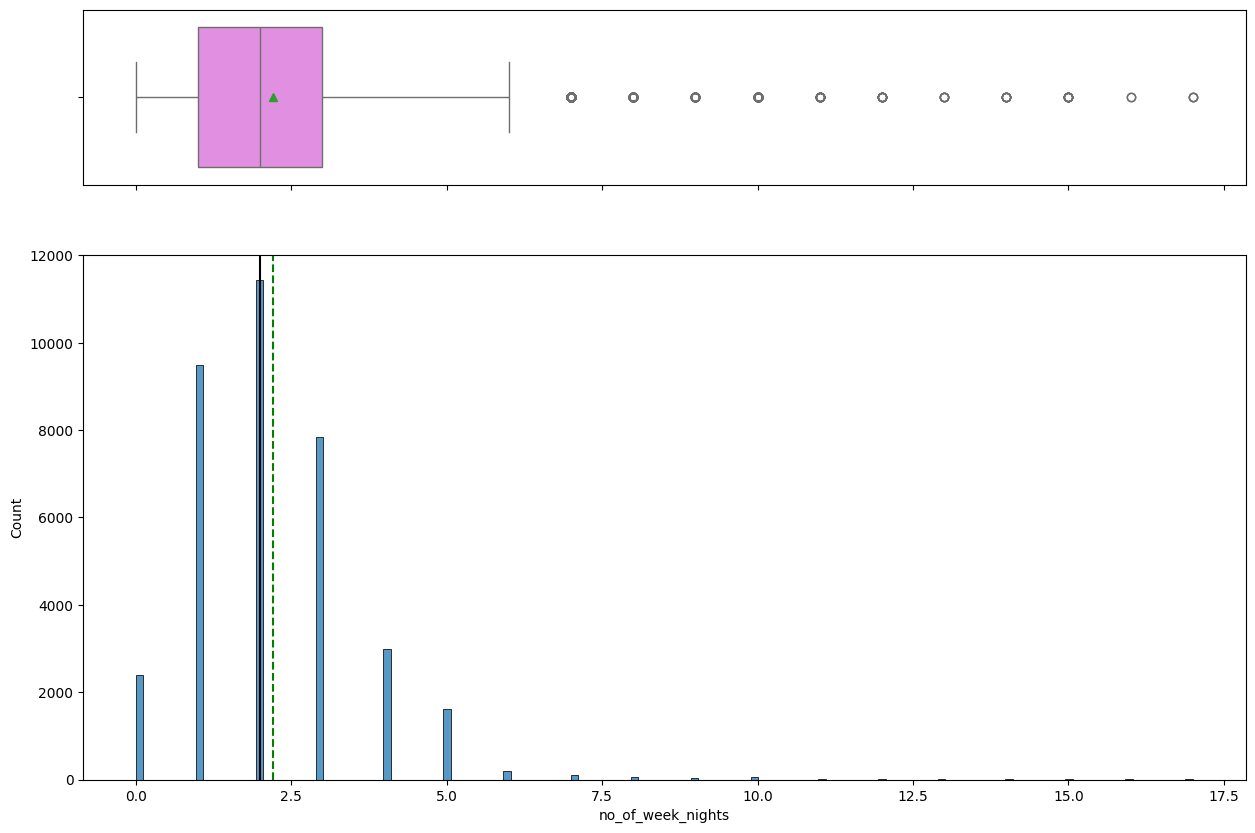

count   36275.00000
mean        2.20430
std         1.41090
min         0.00000
25%         1.00000
50%         2.00000
75%         3.00000
max        17.00000

Univariate: required_car_parking_space


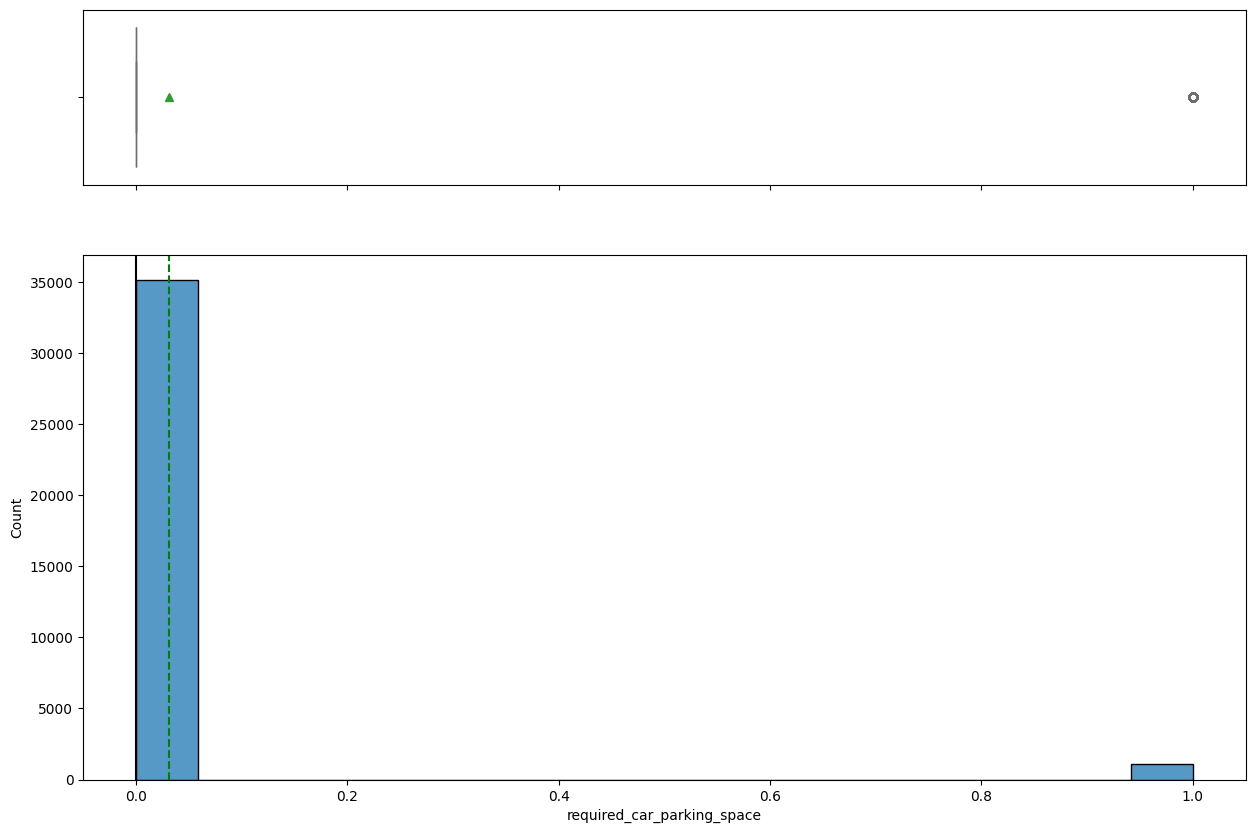

count   36275.00000
mean        0.03099
std         0.17328
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max         1.00000

Univariate: lead_time


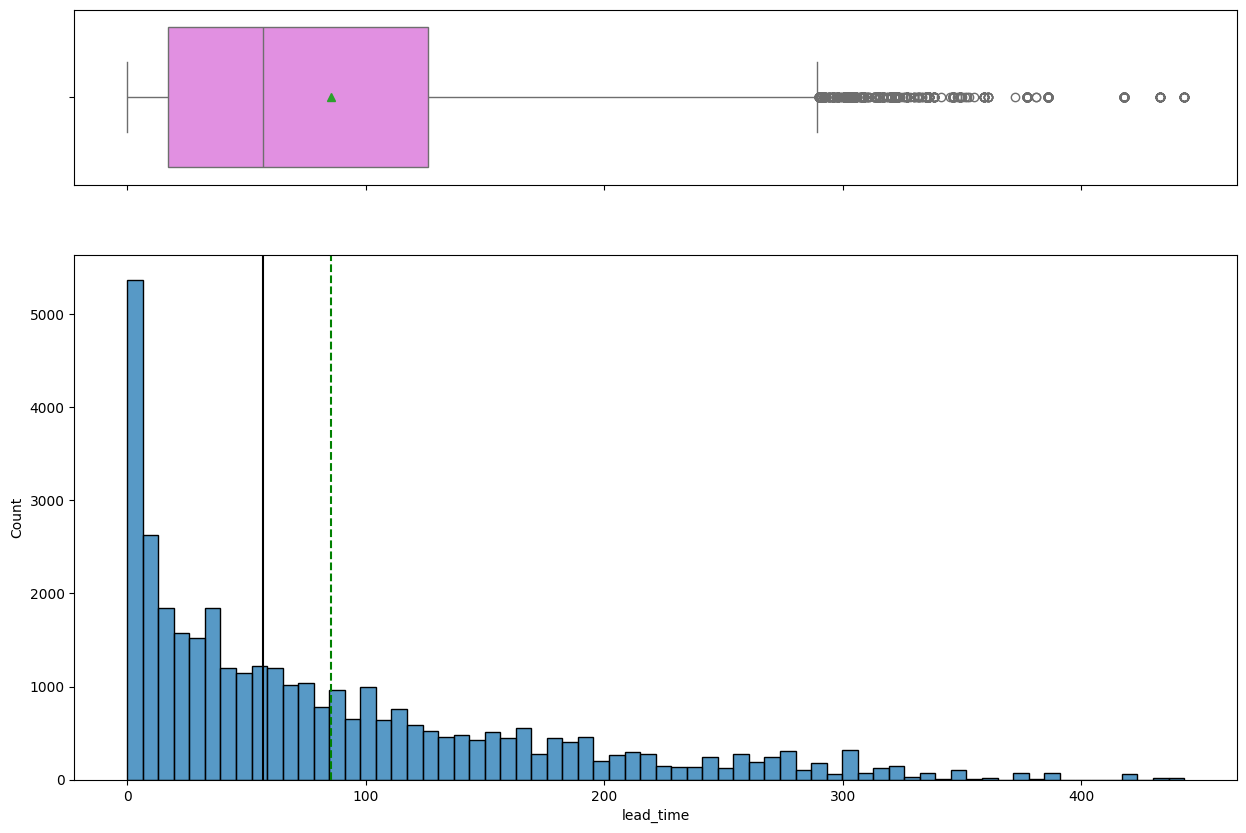

count   36275.00000
mean       85.23256
std        85.93082
min         0.00000
25%        17.00000
50%        57.00000
75%       126.00000
max       443.00000

Univariate: arrival_year


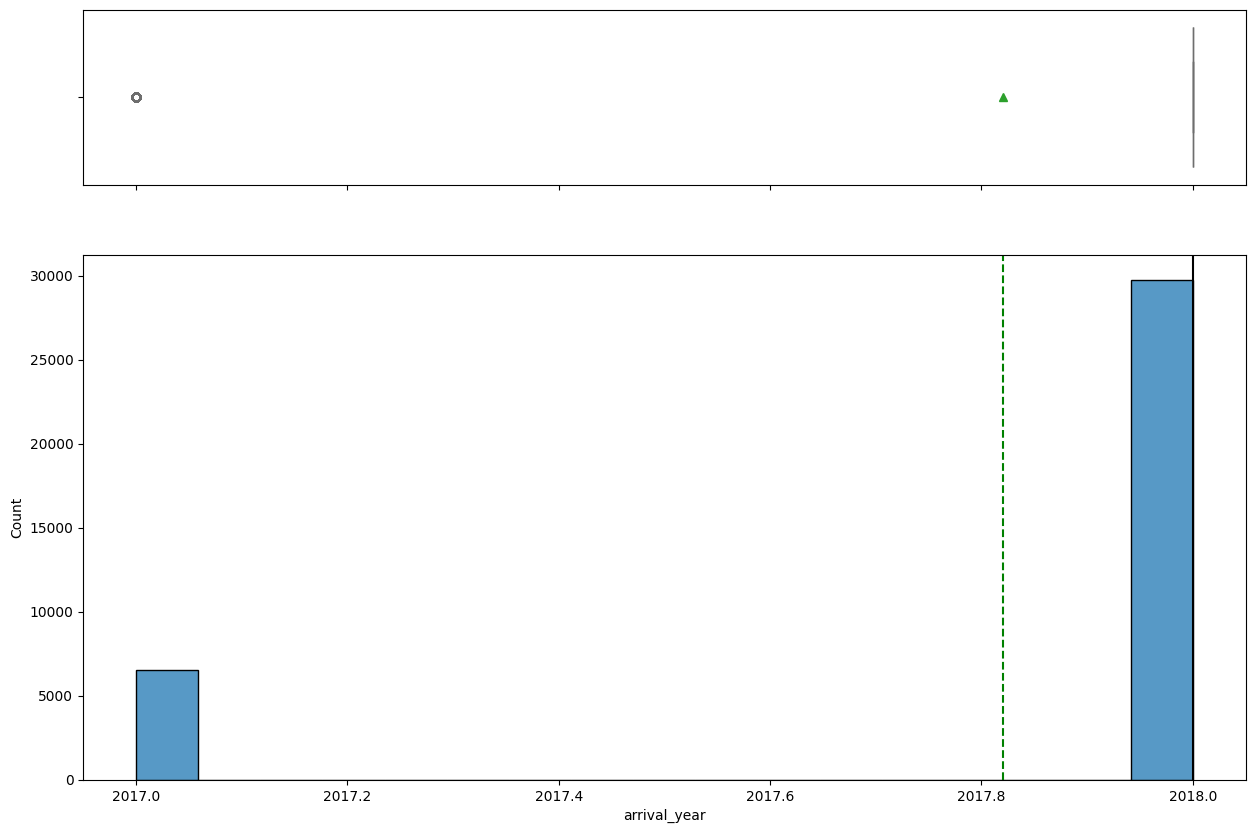

count   36275.00000
mean     2017.82043
std         0.38384
min      2017.00000
25%      2018.00000
50%      2018.00000
75%      2018.00000
max      2018.00000

Univariate: arrival_month


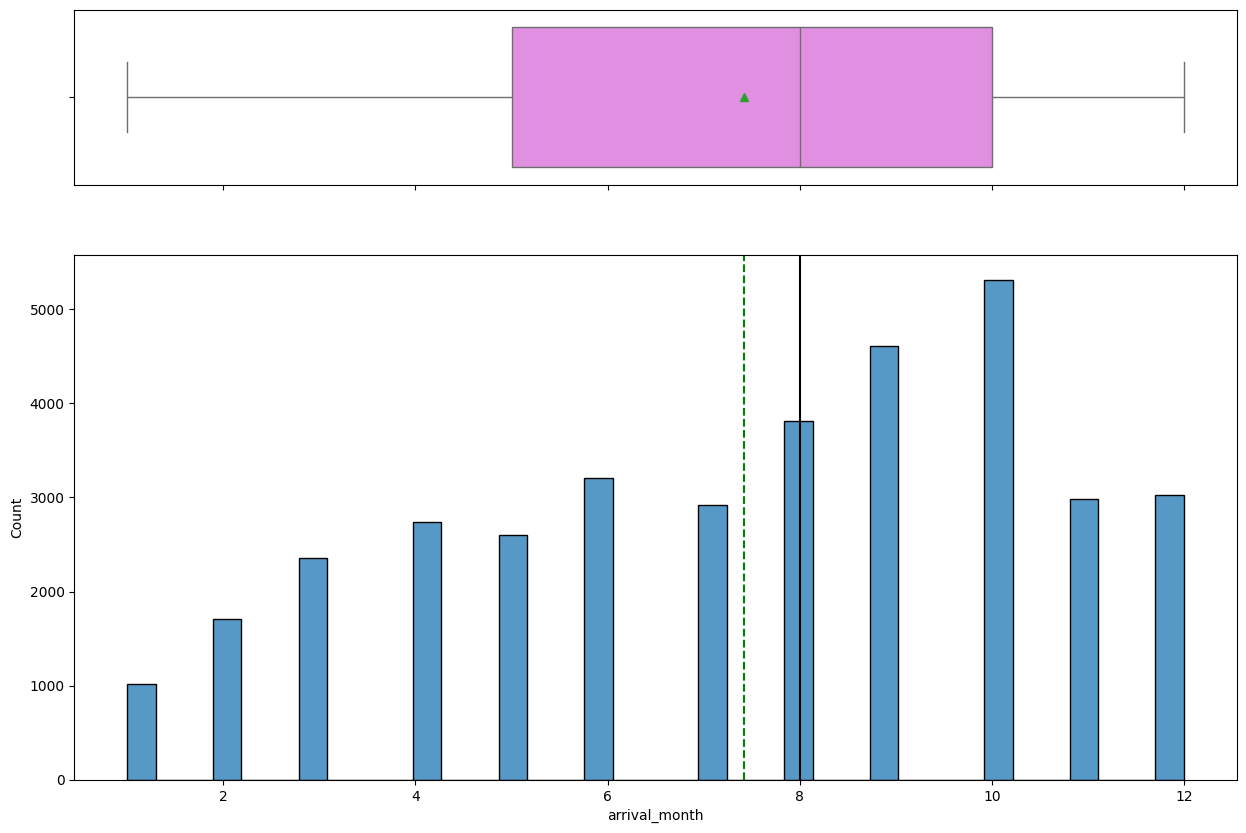

count   36275.00000
mean        7.42365
std         3.06989
min         1.00000
25%         5.00000
50%         8.00000
75%        10.00000
max        12.00000

Univariate: arrival_date


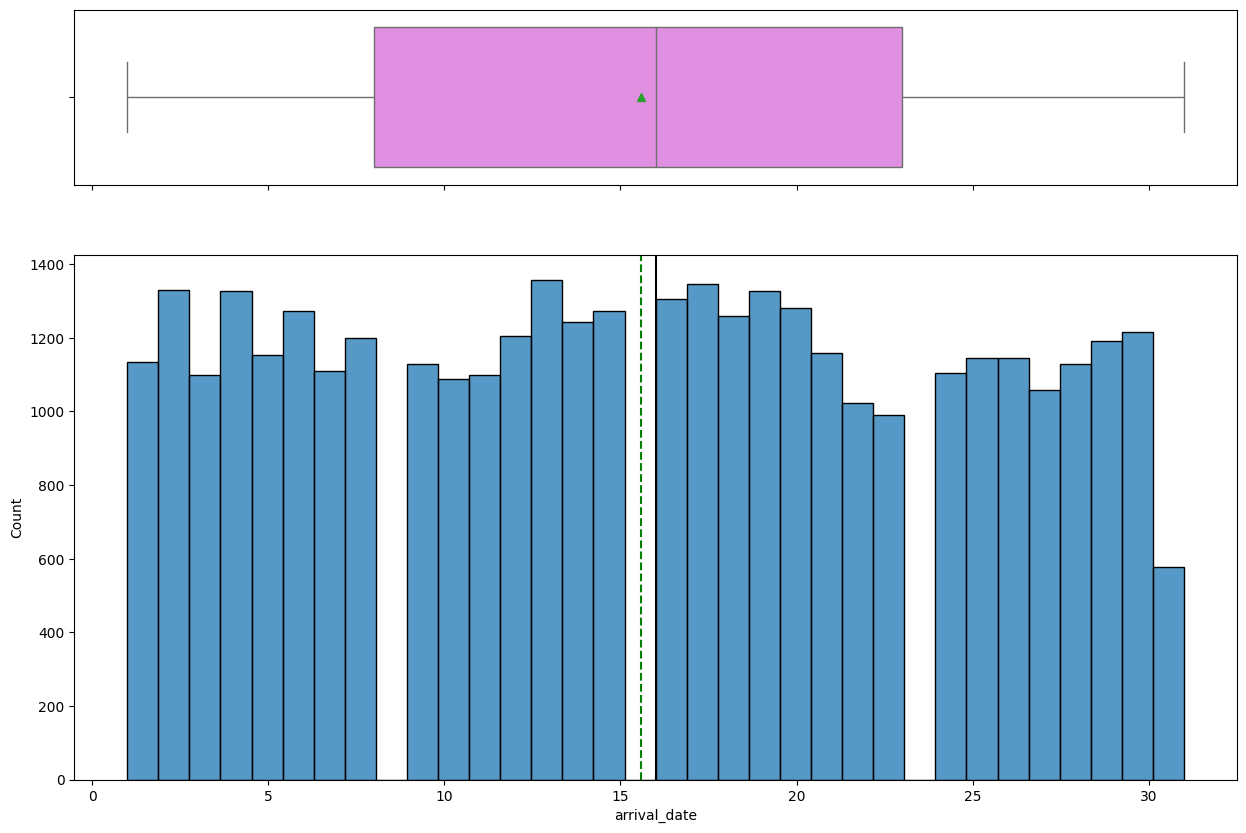

count   36275.00000
mean       15.59700
std         8.74045
min         1.00000
25%         8.00000
50%        16.00000
75%        23.00000
max        31.00000

Univariate: repeated_guest


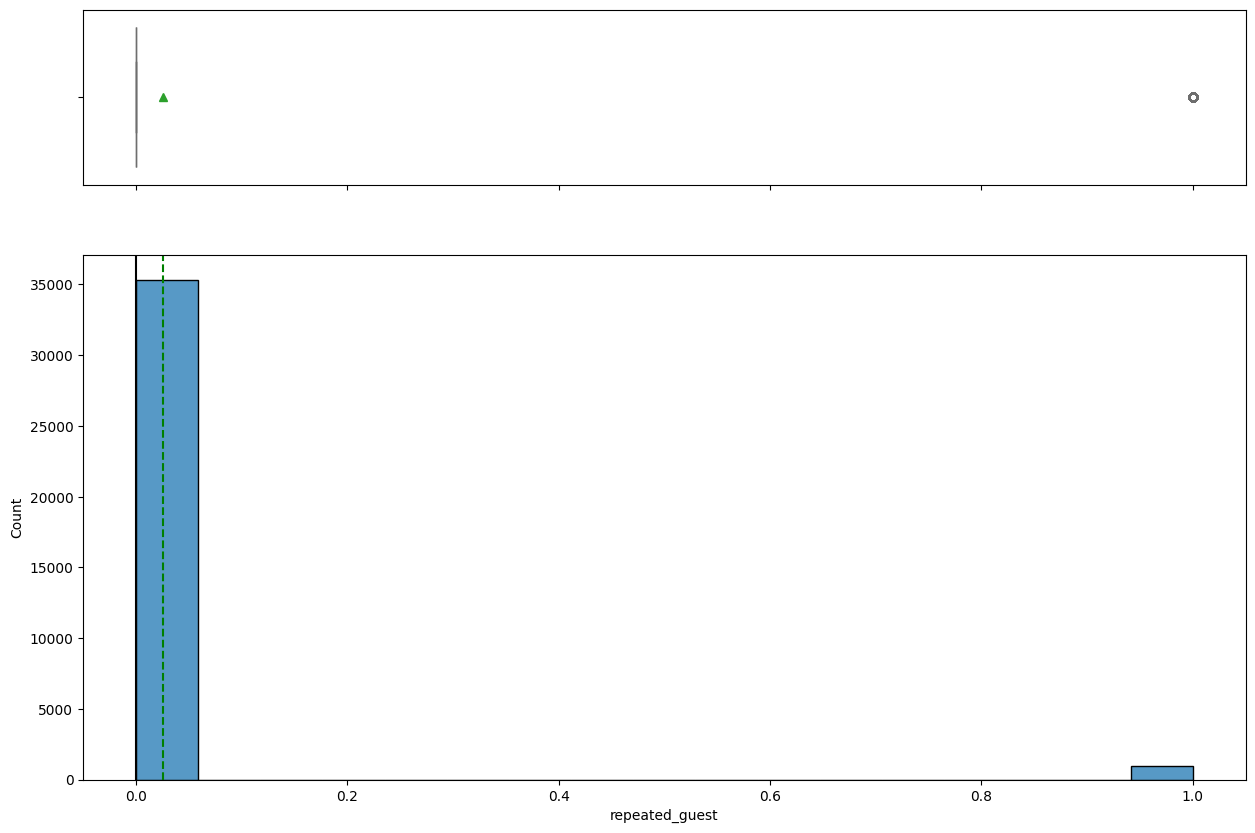

count   36275.00000
mean        0.02564
std         0.15805
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max         1.00000

Univariate: no_of_previous_cancellations


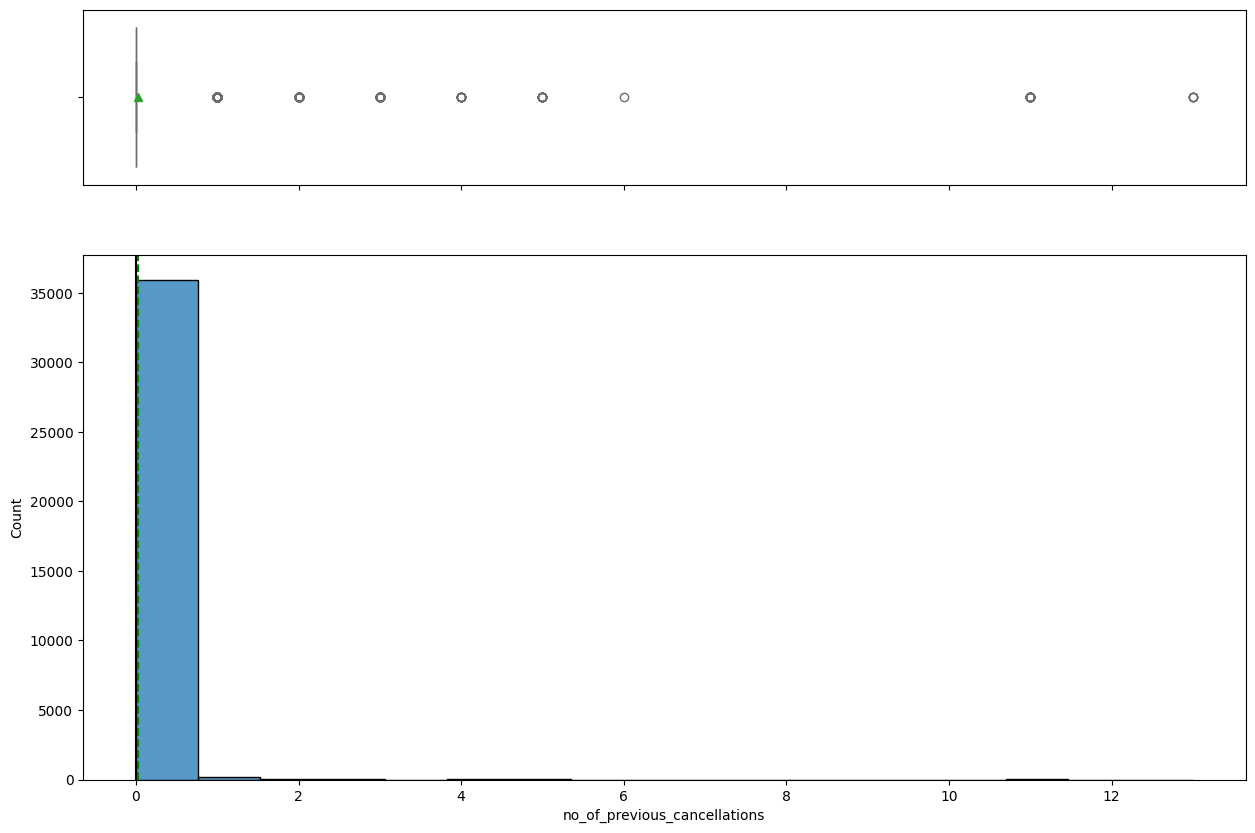

count   36275.00000
mean        0.02335
std         0.36833
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max        13.00000

Univariate: no_of_previous_bookings_not_canceled


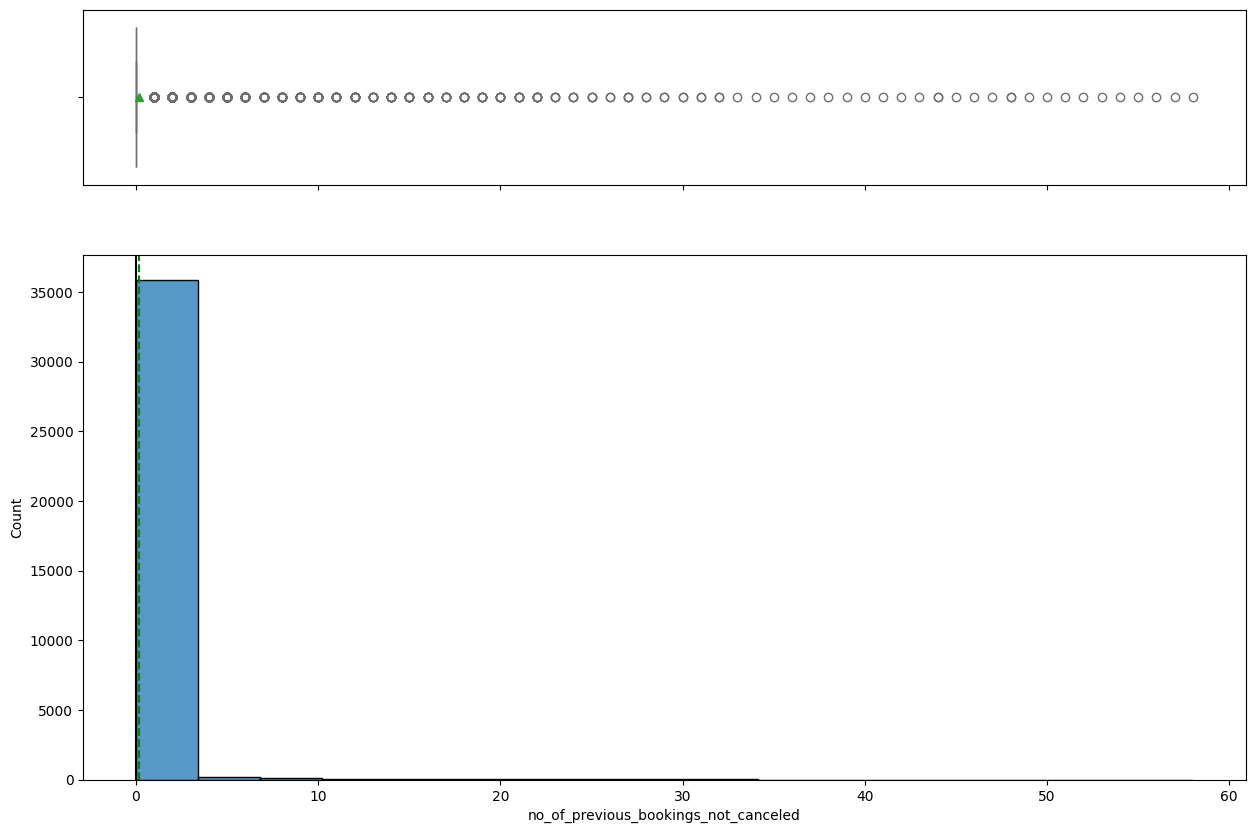

count   36275.00000
mean        0.15341
std         1.75417
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max        58.00000

Univariate: no_of_special_requests


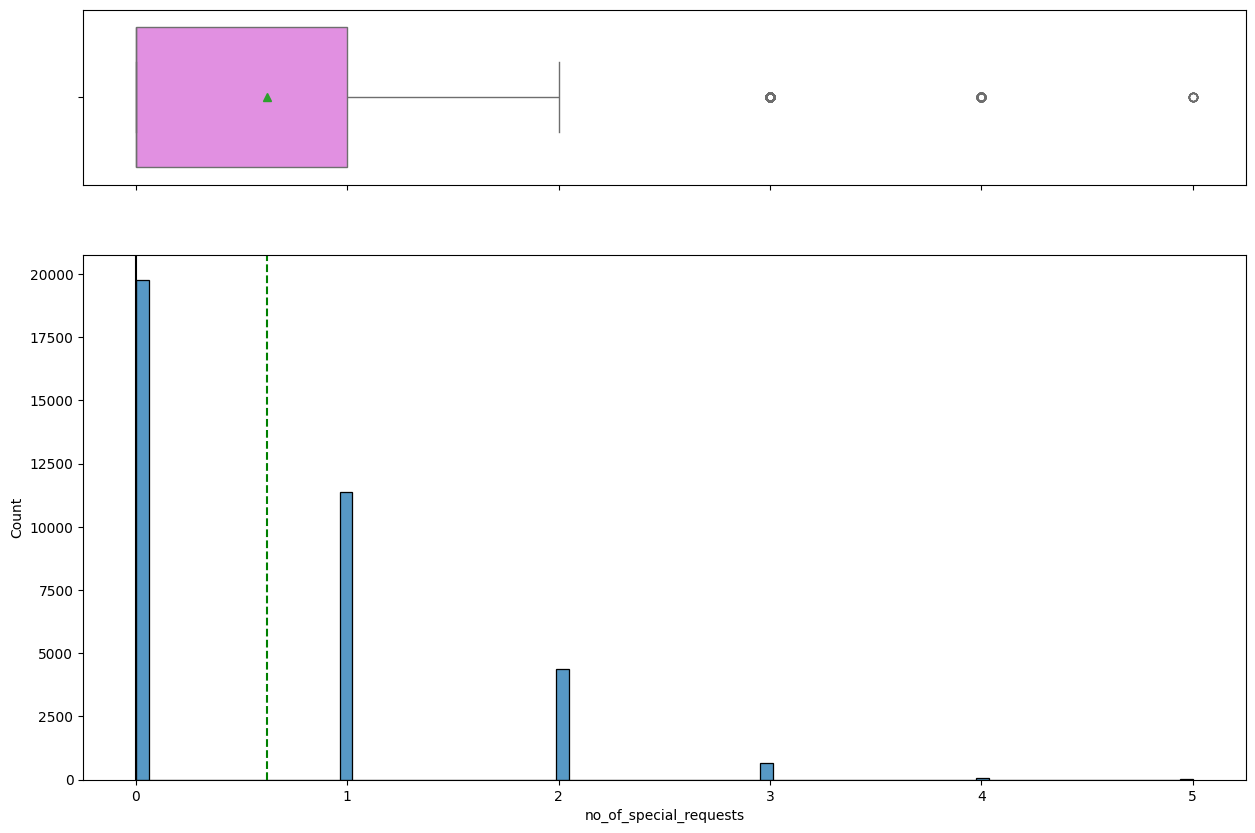

count   36275.00000
mean        0.61966
std         0.78624
min         0.00000
25%         0.00000
50%         0.00000
75%         1.00000
max         5.00000


In [45]:
#C45
print(len(numeric_columns), "numeric columns")
for col in numeric_columns:
    print("\nUnivariate:", col)
    histogram_boxplot(df, col)

####Observations:
1. 78.2% of reservation are by two or more adults
2. 92.6 % of reservations are no kids
3. 46.5 % of reservations have no weekend night
4. 6.6% have no WEEK nights
5. 14.1% did not select a meal plan
6. only 3.1% of guests require parking
7. Lead time is right skewed. Half the bookings are 57 days or less lead time. The other half are above 57
8. arrival year data is for 2017 (18%) and 2018 (82%)
9. 37.9 % of the reservation occur in Oct, Sep and Aug
10. the end of the month appears to be lest popular

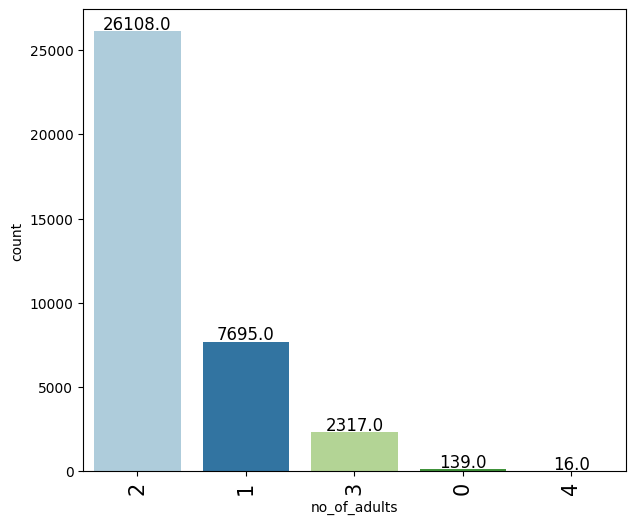

              count percentage
no_of_adults                  
2             26108      72.0%
1              7695      21.2%
3              2317       6.4%
0               139       0.4%
4                16       0.0%


In [46]:
#C46
num ='no_of_adults'
labeled_barplot(df, num)

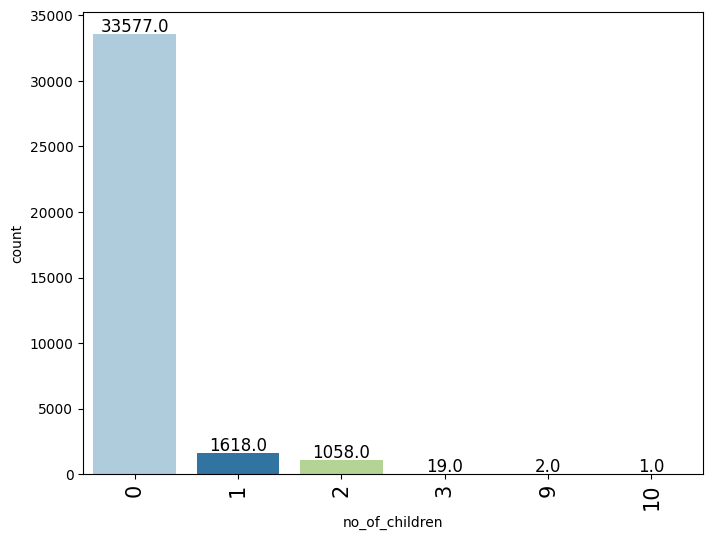

                count percentage
no_of_children                  
0               33577      92.6%
1                1618       4.5%
2                1058       2.9%
3                  19       0.1%
9                   2       0.0%
10                  1       0.0%


In [47]:
#C47
num ='no_of_children'
labeled_barplot(df, num)

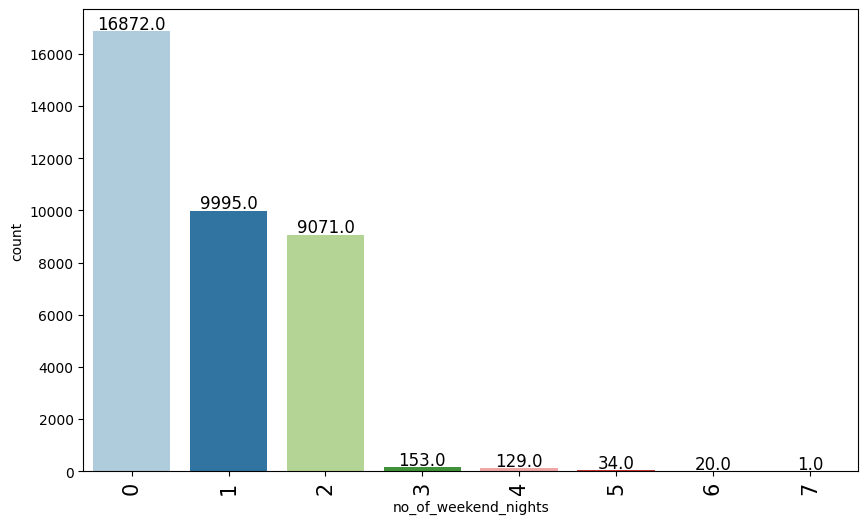

                      count percentage
no_of_weekend_nights                  
0                     16872      46.5%
1                      9995      27.6%
2                      9071      25.0%
3                       153       0.4%
4                       129       0.4%
5                        34       0.1%
6                        20       0.1%
7                         1       0.0%


In [48]:
#C48
num ='no_of_weekend_nights'
labeled_barplot(df, num)

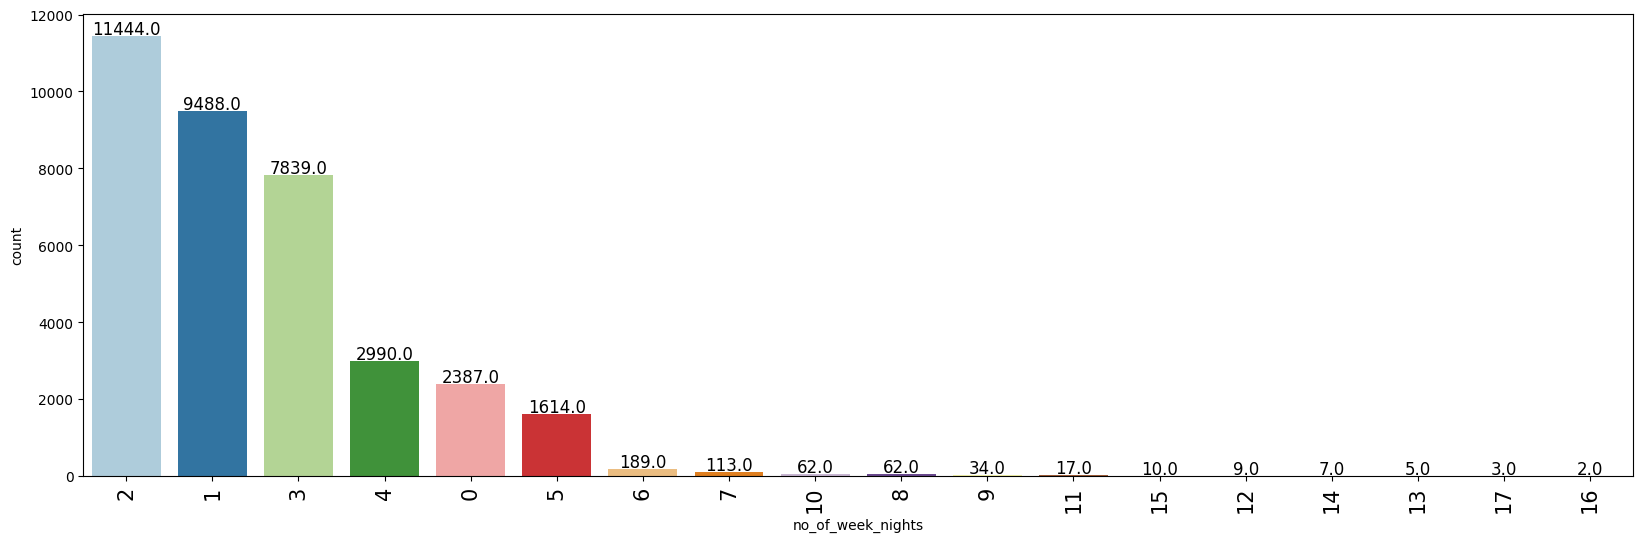

                   count percentage
no_of_week_nights                  
2                  11444      31.5%
1                   9488      26.2%
3                   7839      21.6%
4                   2990       8.2%
0                   2387       6.6%
5                   1614       4.4%
6                    189       0.5%
7                    113       0.3%
10                    62       0.2%
8                     62       0.2%
9                     34       0.1%
11                    17       0.0%
15                    10       0.0%
12                     9       0.0%
14                     7       0.0%
13                     5       0.0%
17                     3       0.0%
16                     2       0.0%


In [49]:
#C49
num ='no_of_week_nights'
labeled_barplot(df, num)

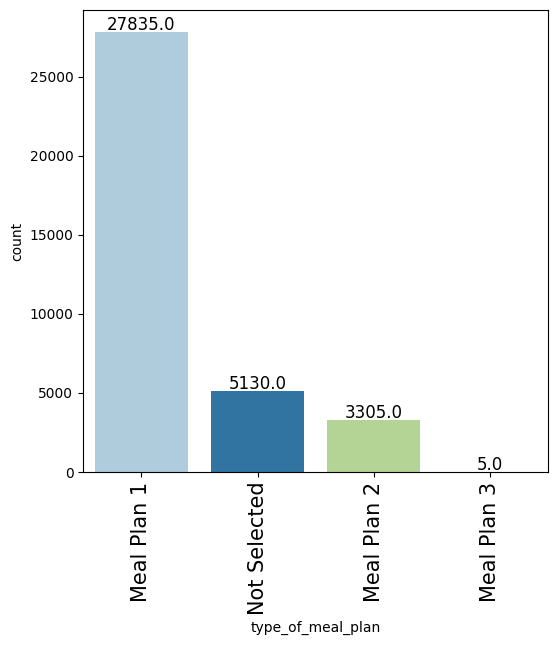

                   count percentage
type_of_meal_plan                  
Meal Plan 1        27835      76.7%
Not Selected        5130      14.1%
Meal Plan 2         3305       9.1%
Meal Plan 3            5       0.0%


In [50]:
#C50
num ='type_of_meal_plan'
labeled_barplot(df, num)

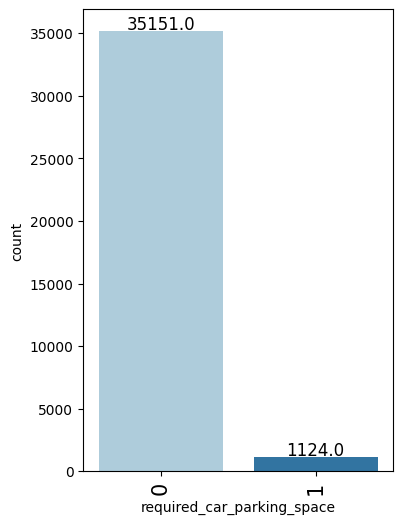

                            count percentage
required_car_parking_space                  
0                           35151      96.9%
1                            1124       3.1%


In [51]:
#C51
num ='required_car_parking_space'
labeled_barplot(df, num)

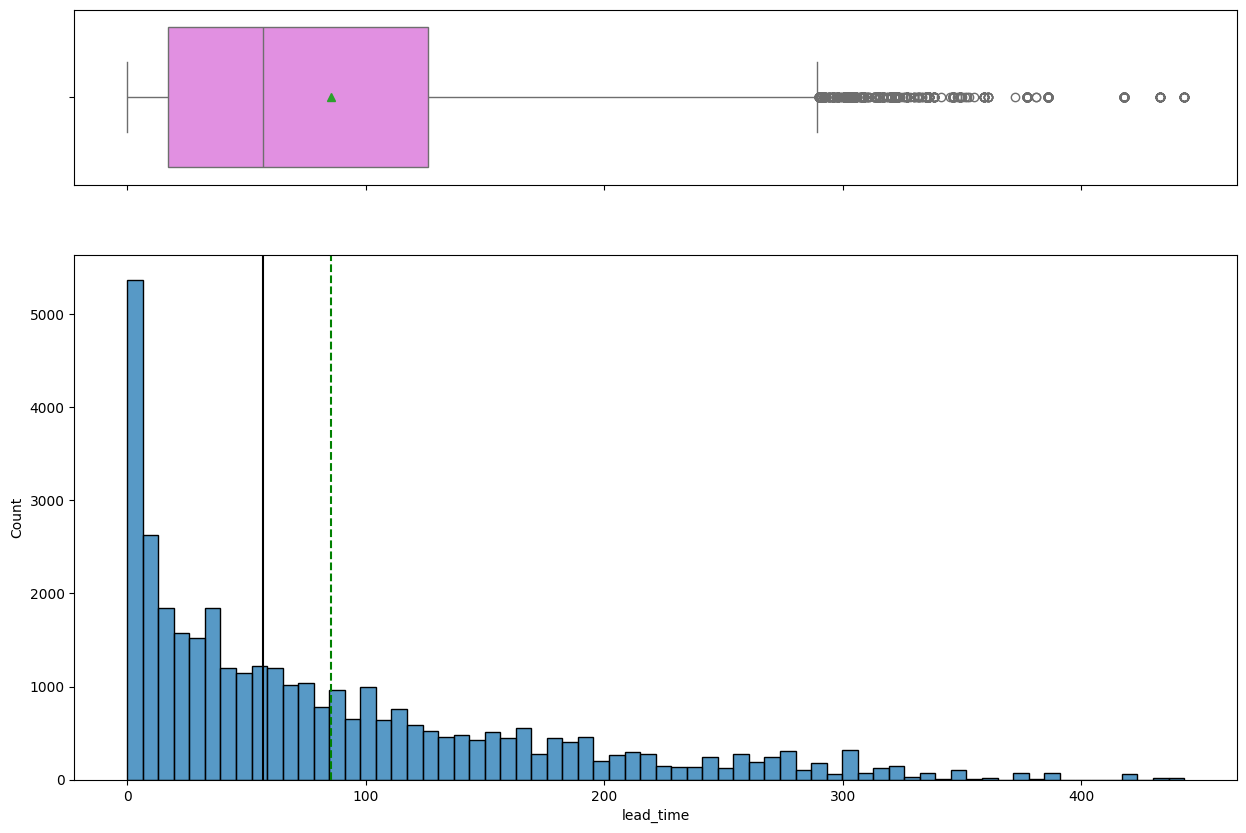

count   36275.00000
mean       85.23256
std        85.93082
min         0.00000
25%        17.00000
50%        57.00000
75%       126.00000
max       443.00000


In [52]:
#C52
num ='lead_time'
histogram_boxplot(df, num)

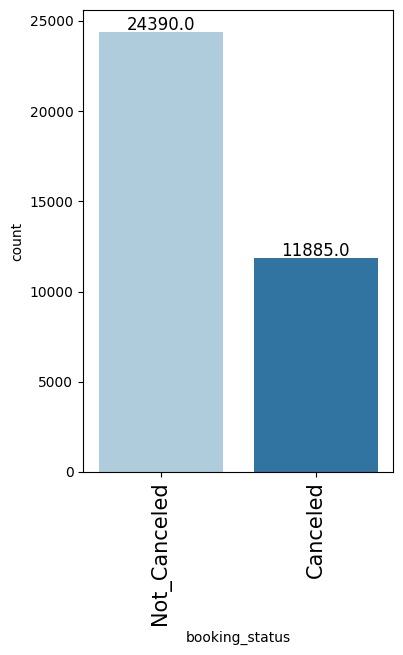

                count percentage
booking_status                  
Not_Canceled    24390      67.2%
Canceled        11885      32.8%


In [53]:
#C53
num ='booking_status'
labeled_barplot(df,( num))

### BIVARIATE ANALYSIS:

#### Corralation Matrix

Observations for numeric columns
 1. the strongest correlation is as follows

    a. no_of_previous_cancellations to no_of_previous_bookings_not_canceled .47 correlation

    b. avg_price_per_room  to no_of_children .34

    c. avg_price_per_room no_of_adults .30

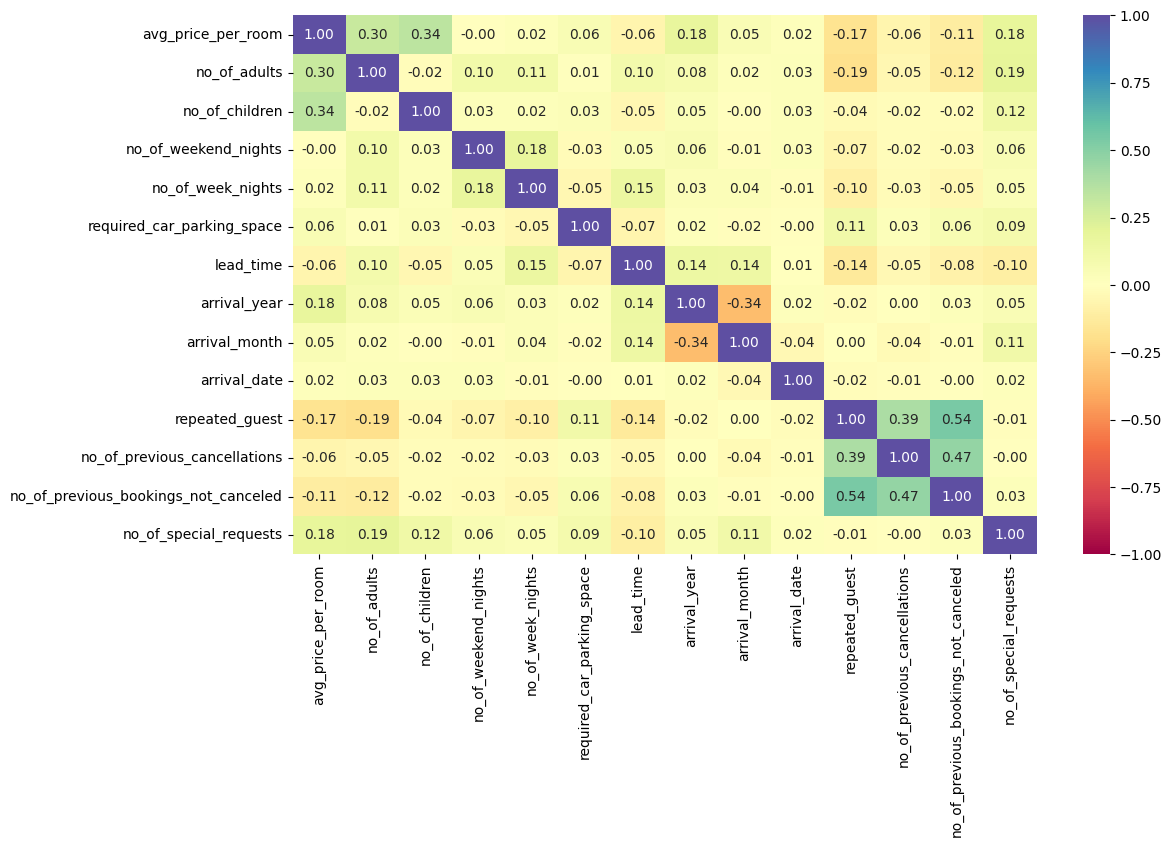

In [54]:
#C54
# A scan for collinearity
#  creating a list of numerical columns
num_cols = numeric_columns


#plot a heat map for the  numerics
plt.figure(figsize=(12, 7))
sns.heatmap(
    df[num_cols].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral"
)
plt.show()

#### Loop through each categorical against the numeric

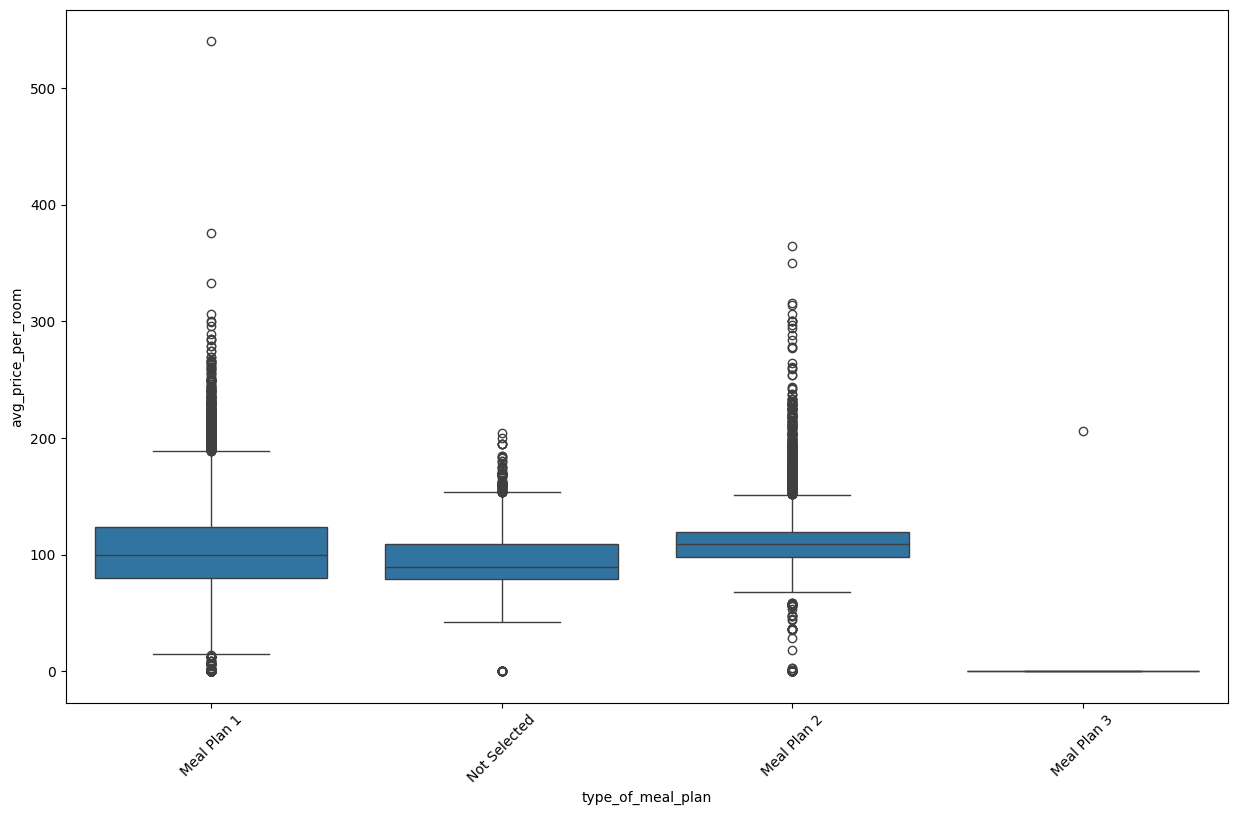

  type_of_meal_plan  count      mean      std     min     my25      my50  \
0       Meal Plan 1  27835 103.59314 35.98561 0.00000 80.00000  99.45000   
1      Not Selected   5130  94.90861 24.59845 0.00000 79.20000  89.25000   
2       Meal Plan 2   3305 115.30611 37.40526 0.00000 97.75000 109.00000   
3       Meal Plan 3      5  41.20000 92.12600 0.00000  0.00000   0.00000   

       my75       max      pct  
0 123.45500 540.00000 76.73329  
1 109.00000 204.00000 14.14197  
2 119.24000 365.00000  9.11096  
3   0.00000 206.00000  0.01378  


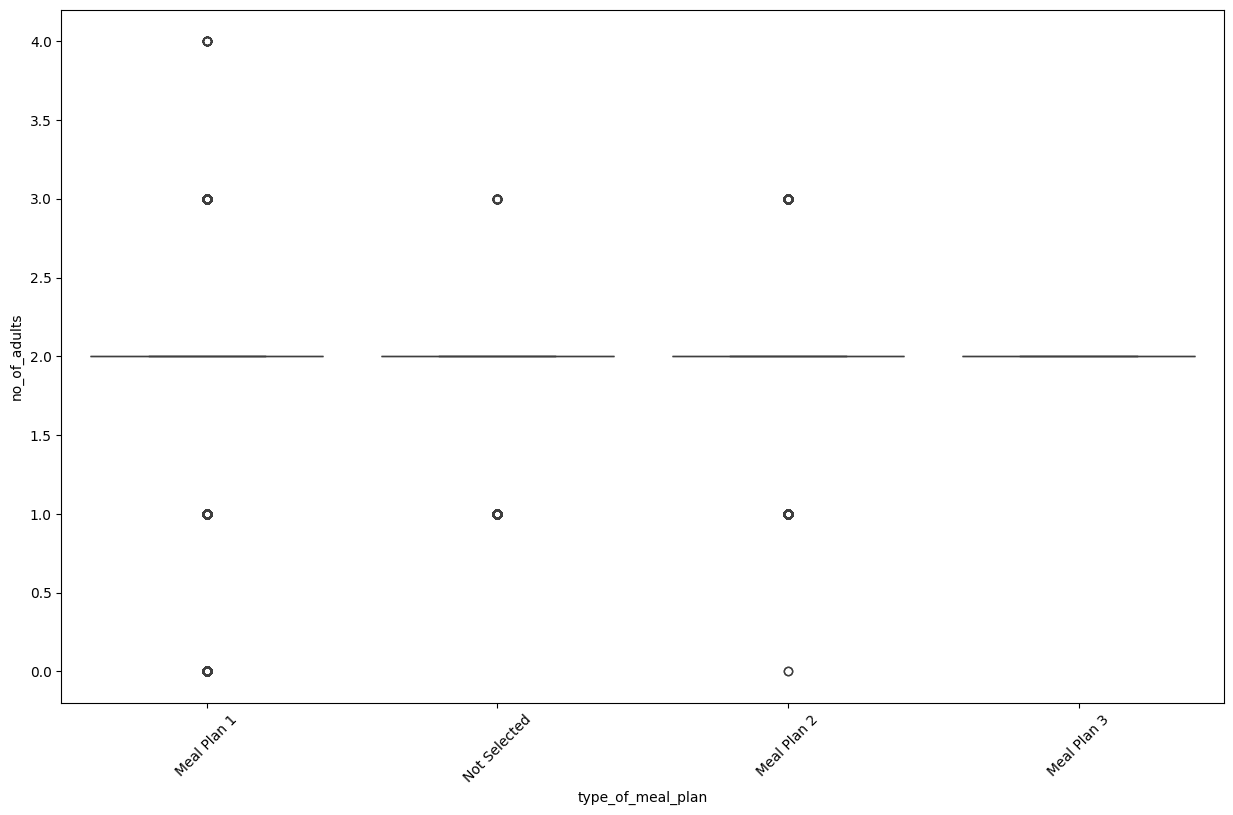

  type_of_meal_plan  count    mean     std  min    my25    my50    my75  max  \
0       Meal Plan 1  27835 1.83661 0.55264    0 2.00000 2.00000 2.00000    4   
1      Not Selected   5130 1.87135 0.35244    1 2.00000 2.00000 2.00000    3   
2       Meal Plan 2   3305 1.87413 0.43096    0 2.00000 2.00000 2.00000    3   
3       Meal Plan 3      5 2.00000 0.00000    2 2.00000 2.00000 2.00000    2   

       pct  
0 76.73329  
1 14.14197  
2  9.11096  
3  0.01378  


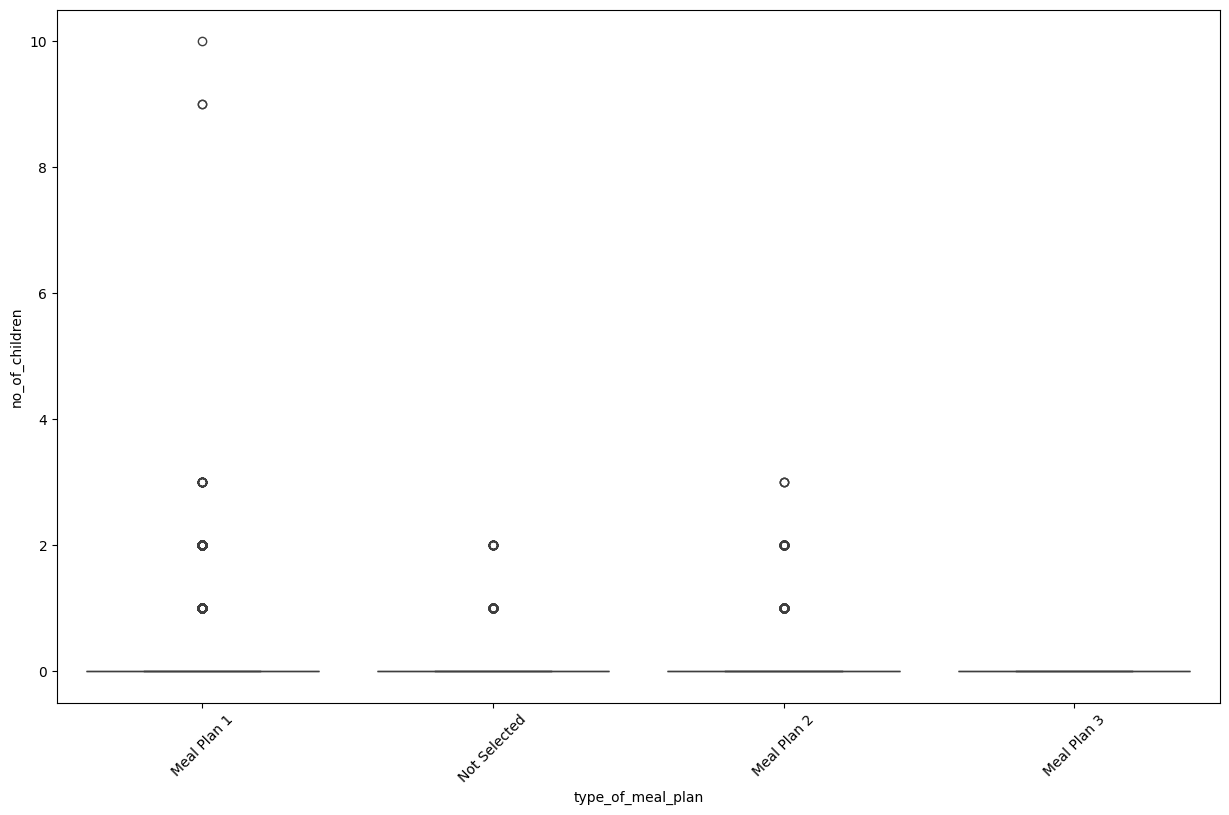

  type_of_meal_plan  count    mean     std  min    my25    my50    my75  max  \
0       Meal Plan 1  27835 0.12380 0.43626    0 0.00000 0.00000 0.00000   10   
1      Not Selected   5130 0.02612 0.18445    0 0.00000 0.00000 0.00000    2   
2       Meal Plan 2   3305 0.07231 0.33179    0 0.00000 0.00000 0.00000    3   
3       Meal Plan 3      5 0.00000 0.00000    0 0.00000 0.00000 0.00000    0   

       pct  
0 76.73329  
1 14.14197  
2  9.11096  
3  0.01378  


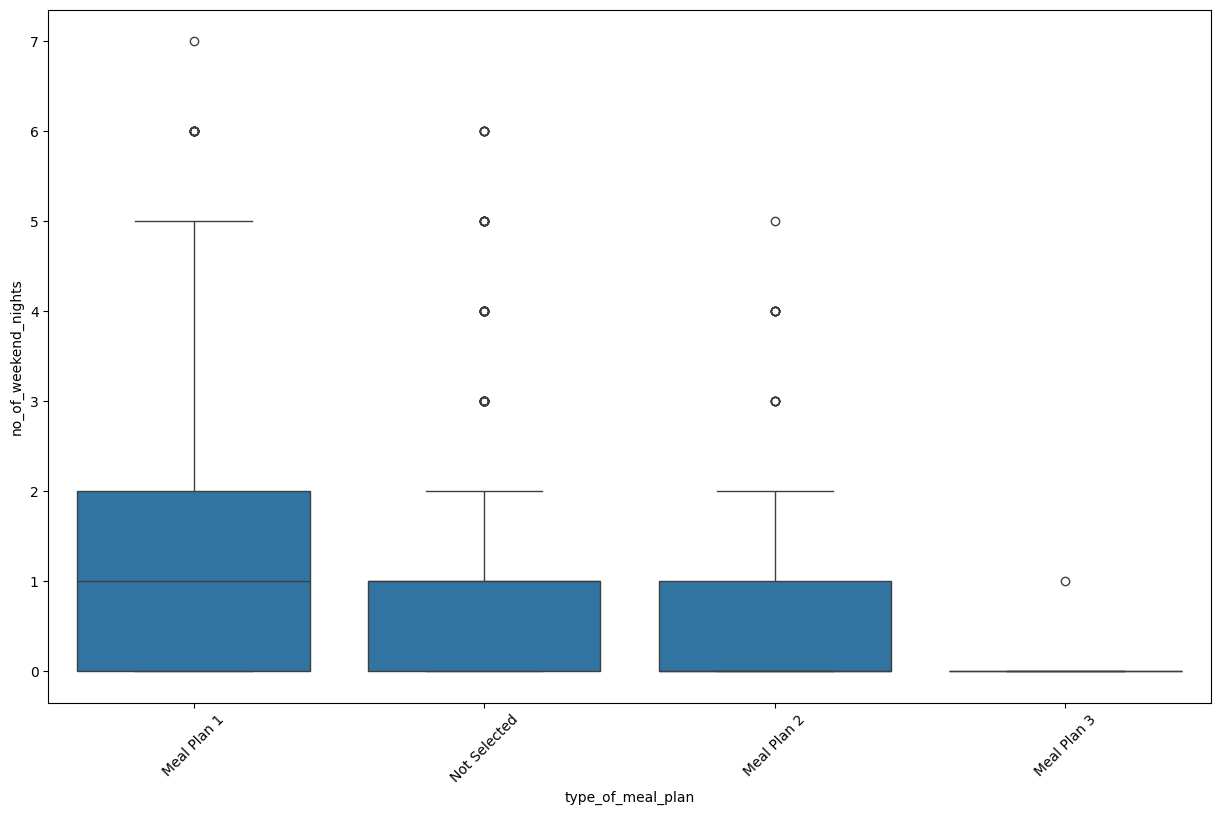

  type_of_meal_plan  count    mean     std  min    my25    my50    my75  max  \
0       Meal Plan 1  27835 0.83197 0.87139    0 0.00000 1.00000 2.00000    7   
1      Not Selected   5130 0.78051 0.86649    0 0.00000 1.00000 1.00000    6   
2       Meal Plan 2   3305 0.67958 0.85824    0 0.00000 0.00000 1.00000    5   
3       Meal Plan 3      5 0.20000 0.44721    0 0.00000 0.00000 0.00000    1   

       pct  
0 76.73329  
1 14.14197  
2  9.11096  
3  0.01378  


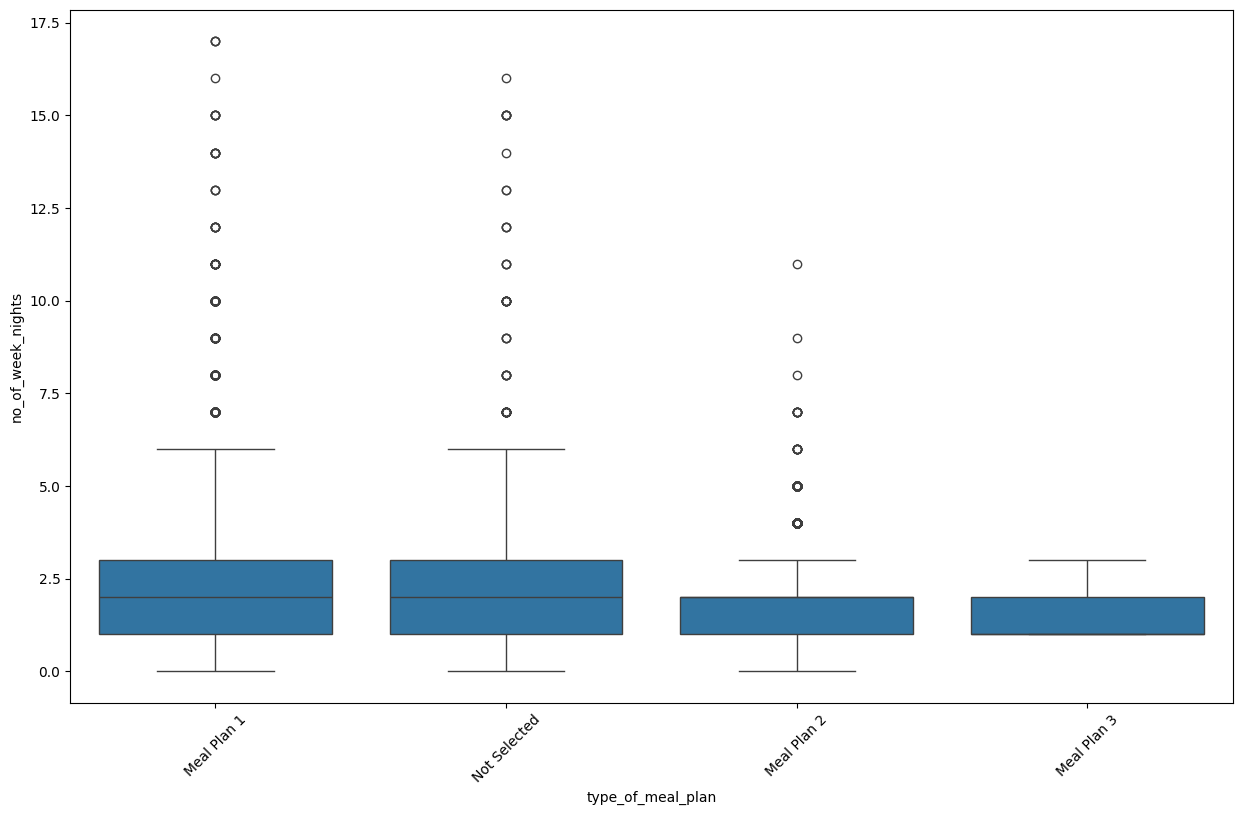

  type_of_meal_plan  count    mean     std  min    my25    my50    my75  max  \
0       Meal Plan 1  27835 2.27271 1.41344    0 1.00000 2.00000 3.00000   17   
1      Not Selected   5130 1.95400 1.52058    0 1.00000 2.00000 3.00000   16   
2       Meal Plan 2   3305 2.01755 1.12357    0 1.00000 2.00000 2.00000   11   
3       Meal Plan 3      5 1.60000 0.89443    1 1.00000 1.00000 2.00000    3   

       pct  
0 76.73329  
1 14.14197  
2  9.11096  
3  0.01378  


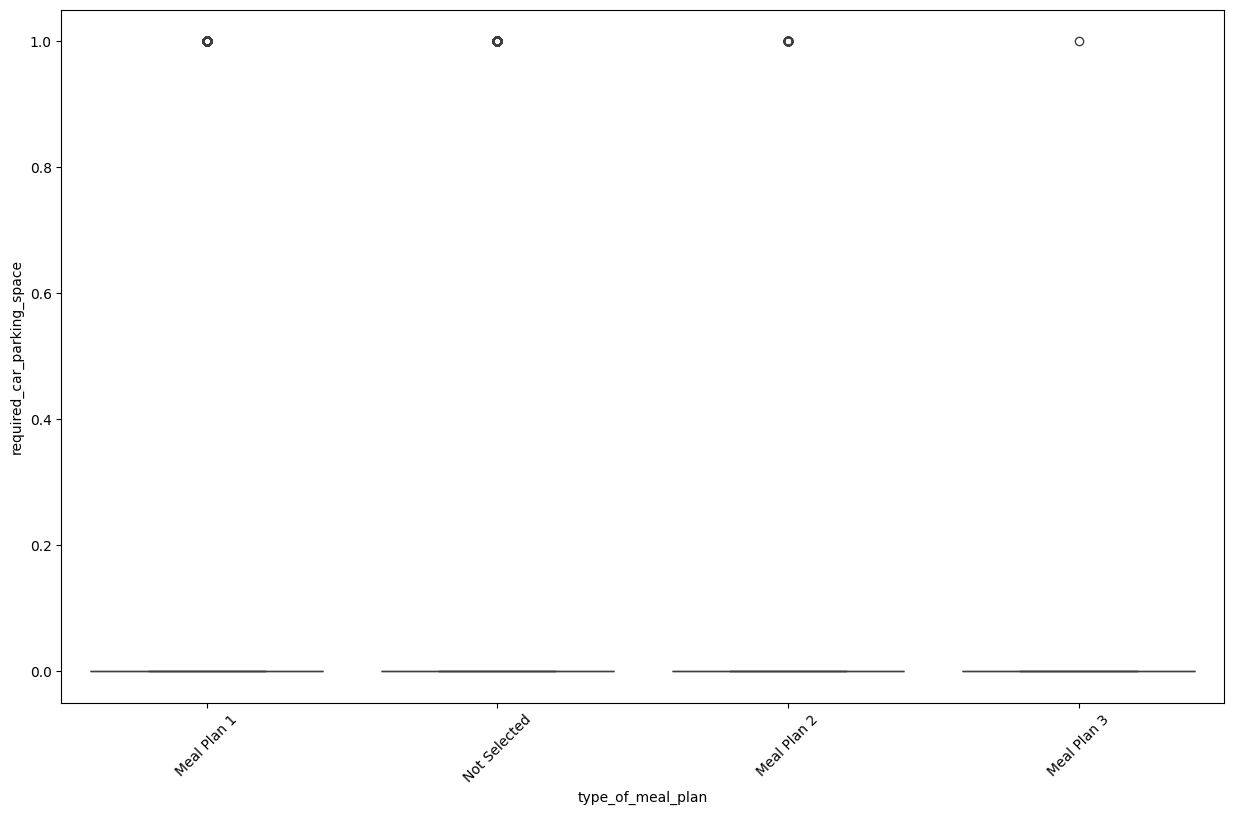

  type_of_meal_plan  count    mean     std  min    my25    my50    my75  max  \
0       Meal Plan 1  27835 0.03338 0.17962    0 0.00000 0.00000 0.00000    1   
1      Not Selected   5130 0.02904 0.16795    0 0.00000 0.00000 0.00000    1   
2       Meal Plan 2   3305 0.01362 0.11591    0 0.00000 0.00000 0.00000    1   
3       Meal Plan 3      5 0.20000 0.44721    0 0.00000 0.00000 0.00000    1   

       pct  
0 76.73329  
1 14.14197  
2  9.11096  
3  0.01378  


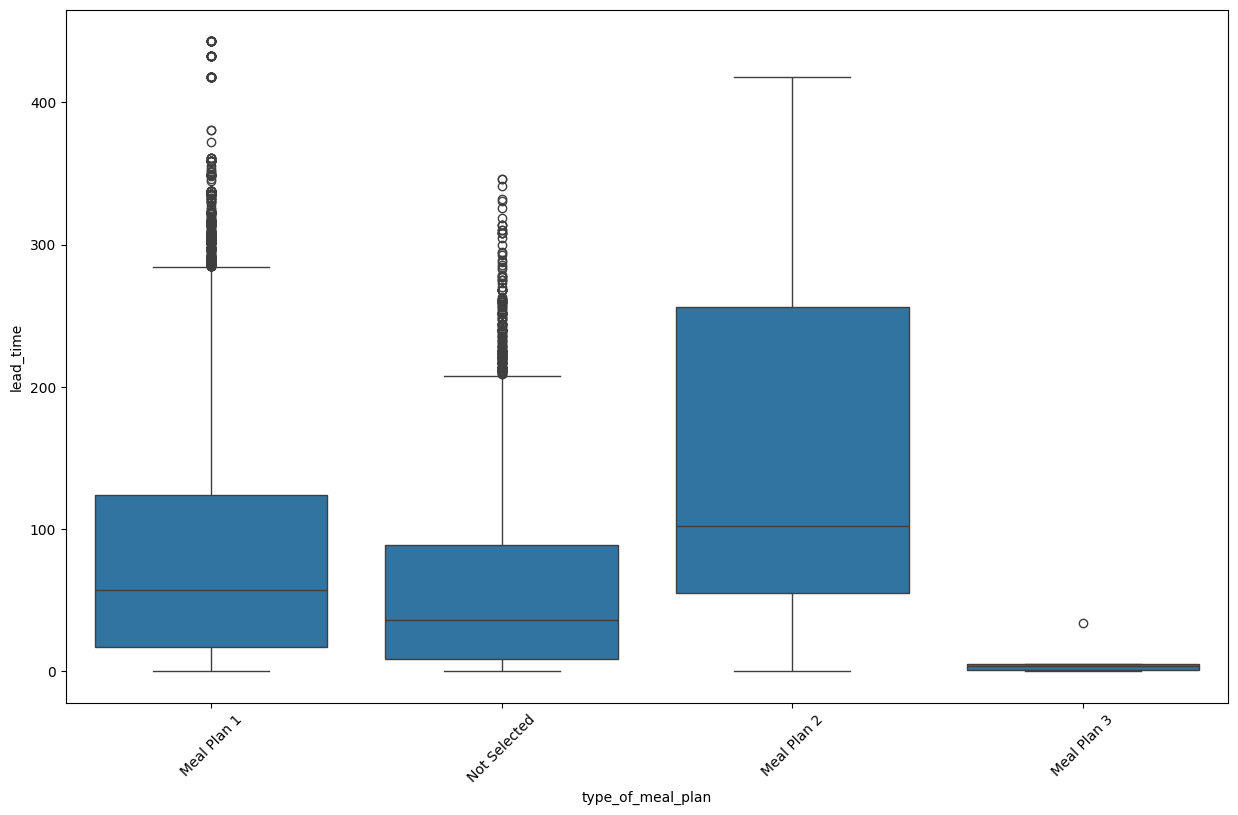

  type_of_meal_plan  count      mean       std  min     my25      my50  \
0       Meal Plan 1  27835  82.66039  81.81696    0 17.00000  57.00000   
1      Not Selected   5130  59.09961  64.19904    0  9.00000  36.00000   
2       Meal Plan 2   3305 147.57458 115.17434    0 55.00000 102.00000   
3       Meal Plan 3      5   8.80000  14.23728    0  1.00000   4.00000   

       my75  max      pct  
0 124.00000  443 76.73329  
1  88.75000  346 14.14197  
2 256.00000  418  9.11096  
3   5.00000   34  0.01378  


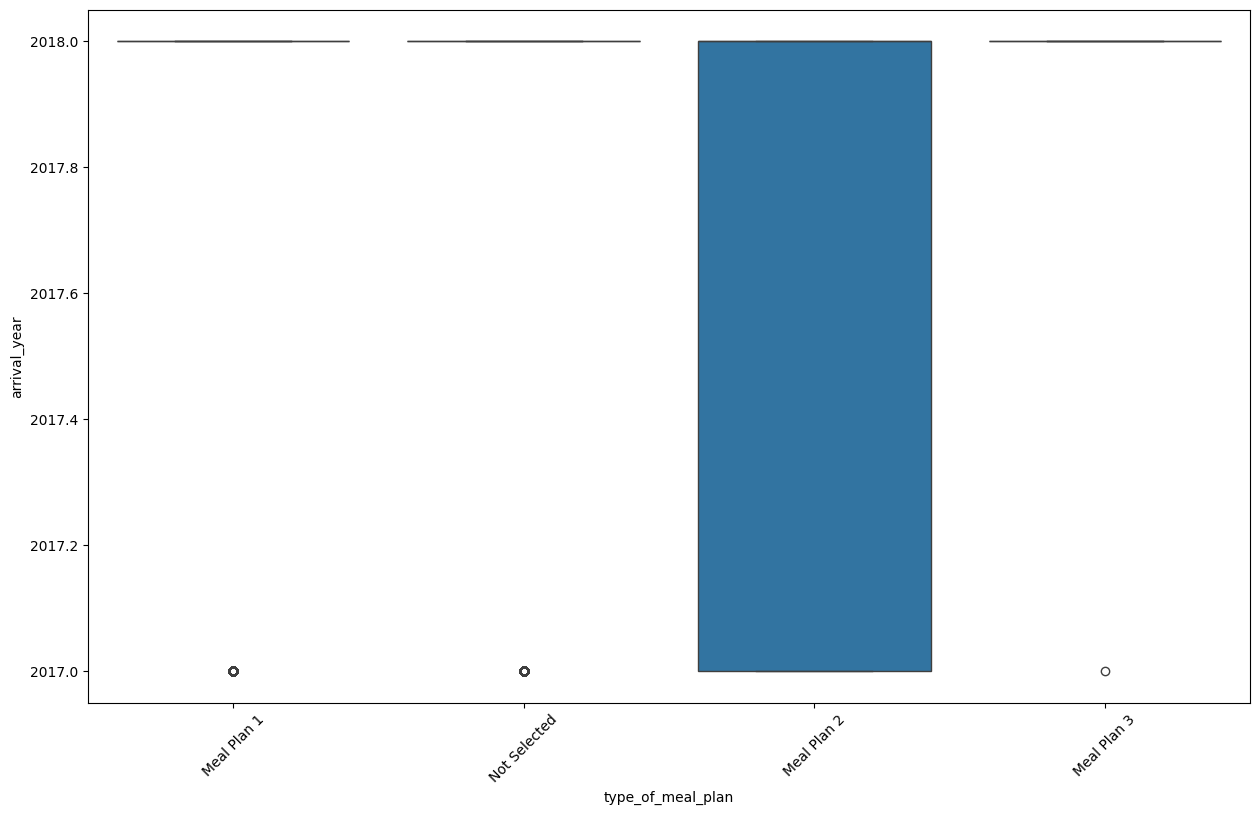

  type_of_meal_plan  count       mean     std   min       my25       my50  \
0       Meal Plan 1  27835 2017.82425 0.38061  2017 2018.00000 2018.00000   
1      Not Selected   5130 2017.93236 0.25115  2017 2018.00000 2018.00000   
2       Meal Plan 2   3305 2017.61452 0.48678  2017 2017.00000 2018.00000   
3       Meal Plan 3      5 2017.80000 0.44721  2017 2018.00000 2018.00000   

        my75   max      pct  
0 2018.00000  2018 76.73329  
1 2018.00000  2018 14.14197  
2 2018.00000  2018  9.11096  
3 2018.00000  2018  0.01378  


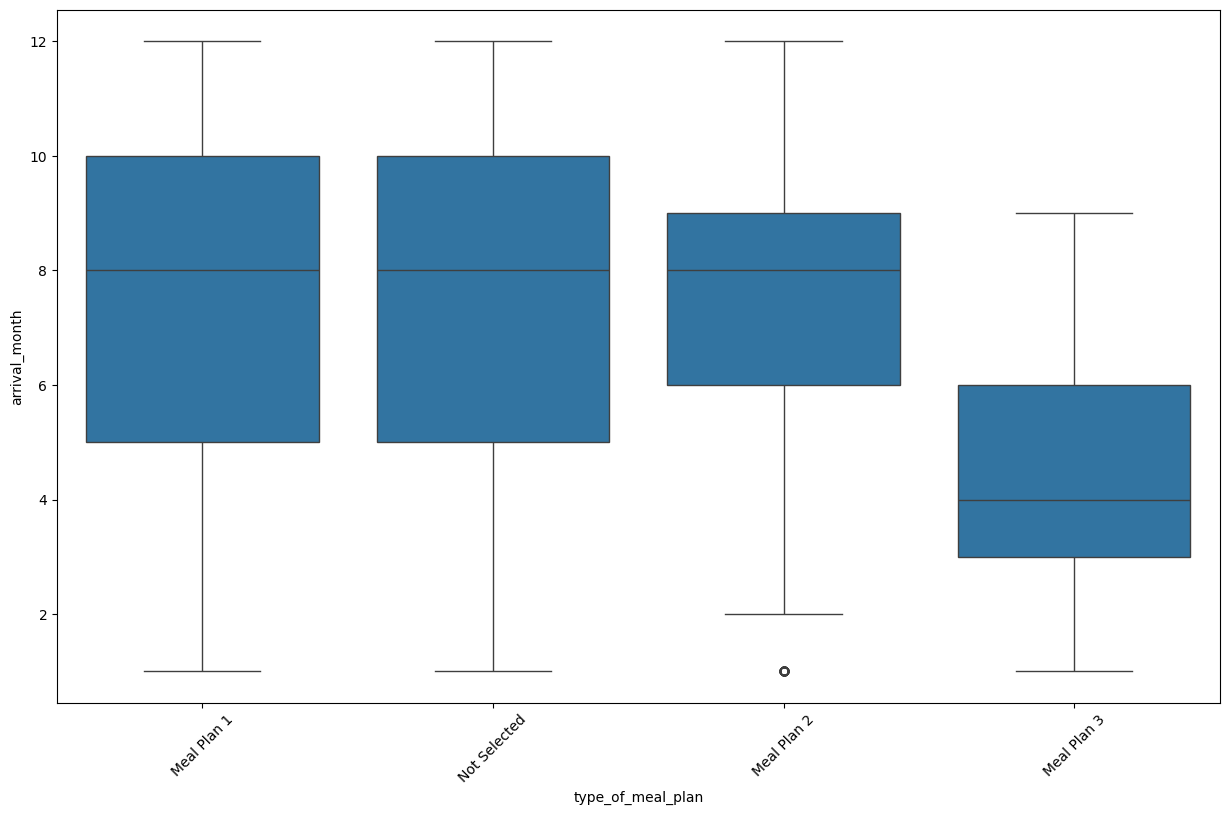

  type_of_meal_plan  count    mean     std  min    my25    my50     my75  max  \
0       Meal Plan 1  27835 7.38865 3.11622    1 5.00000 8.00000 10.00000   12   
1      Not Selected   5130 7.42749 3.19679    1 5.00000 8.00000 10.00000   12   
2       Meal Plan 2   3305 7.71679 2.38240    1 6.00000 8.00000  9.00000   12   
3       Meal Plan 3      5 4.60000 3.04959    1 3.00000 4.00000  6.00000    9   

       pct  
0 76.73329  
1 14.14197  
2  9.11096  
3  0.01378  


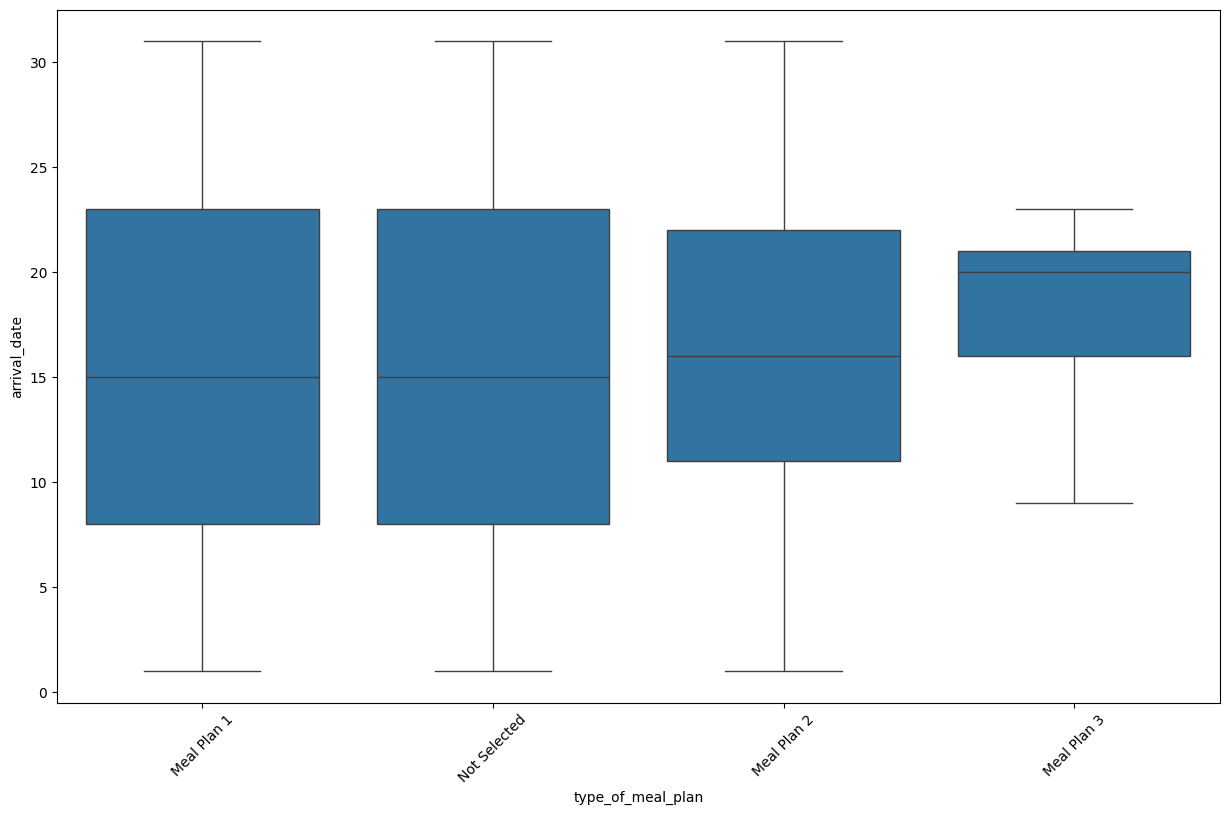

  type_of_meal_plan  count     mean     std  min     my25     my50     my75  \
0       Meal Plan 1  27835 15.52491 8.82446    1  8.00000 15.00000 23.00000   
1      Not Selected   5130 15.55692 8.75482    1  8.00000 15.00000 23.00000   
2       Meal Plan 2   3305 16.26293 7.94991    1 11.00000 16.00000 22.00000   
3       Meal Plan 3      5 17.80000 5.54076    9 16.00000 20.00000 21.00000   

   max      pct  
0   31 76.73329  
1   31 14.14197  
2   31  9.11096  
3   23  0.01378  


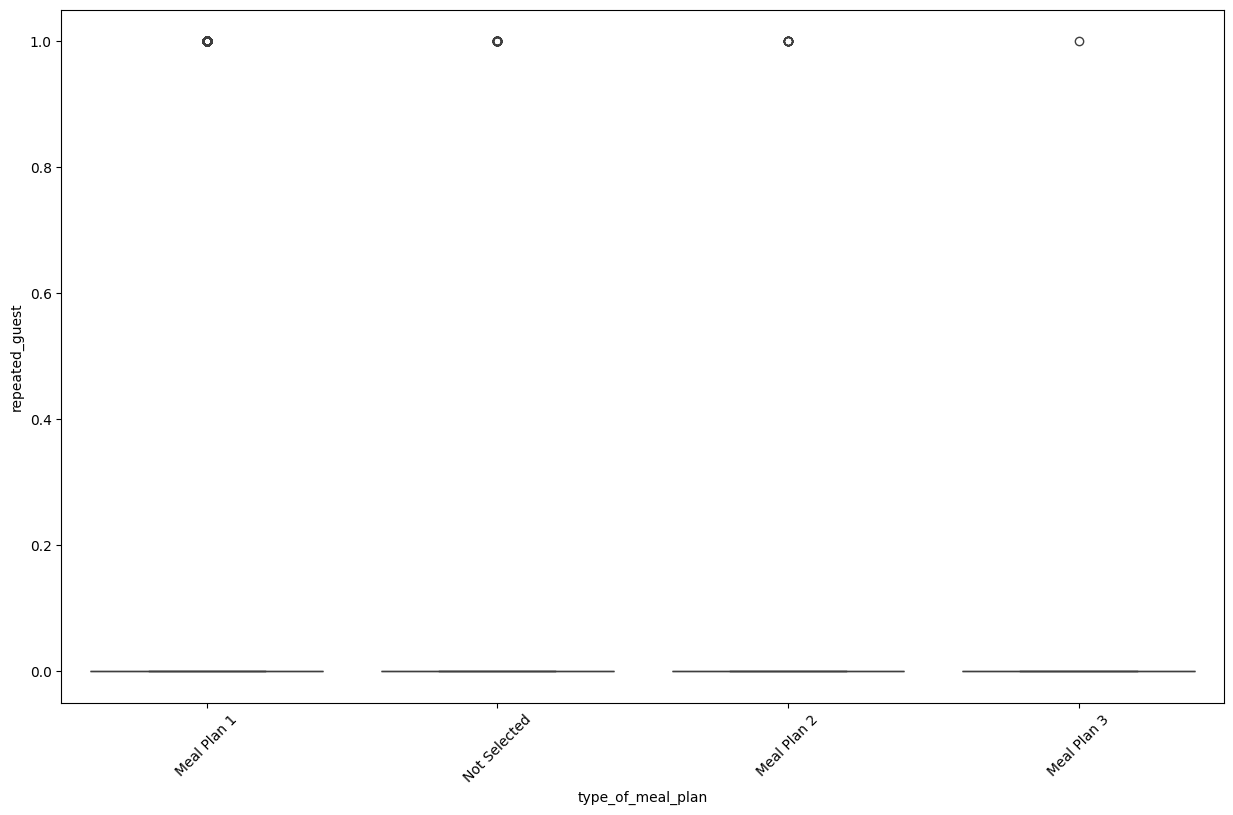

  type_of_meal_plan  count    mean     std  min    my25    my50    my75  max  \
0       Meal Plan 1  27835 0.03197 0.17593    0 0.00000 0.00000 0.00000    1   
1      Not Selected   5130 0.00585 0.07626    0 0.00000 0.00000 0.00000    1   
2       Meal Plan 2   3305 0.00272 0.05212    0 0.00000 0.00000 0.00000    1   
3       Meal Plan 3      5 0.20000 0.44721    0 0.00000 0.00000 0.00000    1   

       pct  
0 76.73329  
1 14.14197  
2  9.11096  
3  0.01378  


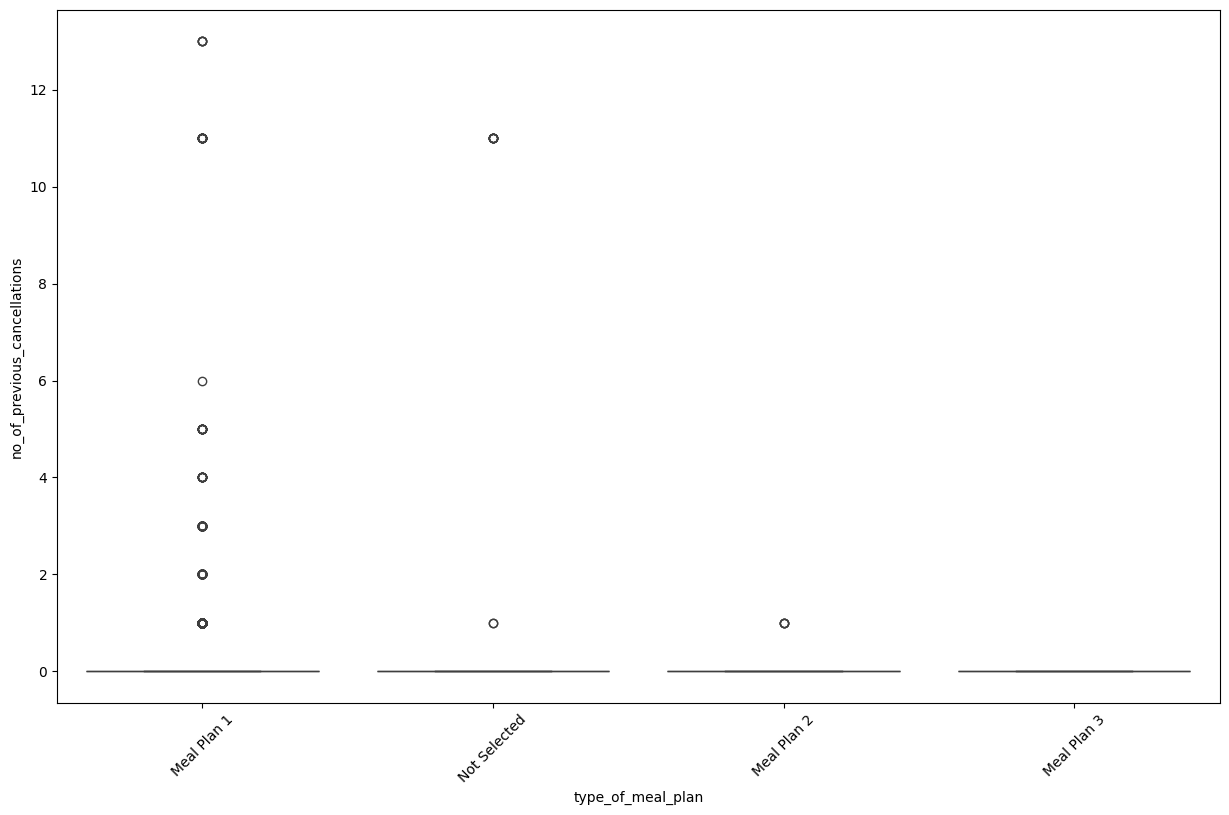

  type_of_meal_plan  count    mean     std  min    my25    my50    my75  max  \
0       Meal Plan 1  27835 0.02705 0.37655    0 0.00000 0.00000 0.00000   13   
1      Not Selected   5130 0.01754 0.43453    0 0.00000 0.00000 0.00000   11   
2       Meal Plan 2   3305 0.00121 0.03477    0 0.00000 0.00000 0.00000    1   
3       Meal Plan 3      5 0.00000 0.00000    0 0.00000 0.00000 0.00000    0   

       pct  
0 76.73329  
1 14.14197  
2  9.11096  
3  0.01378  


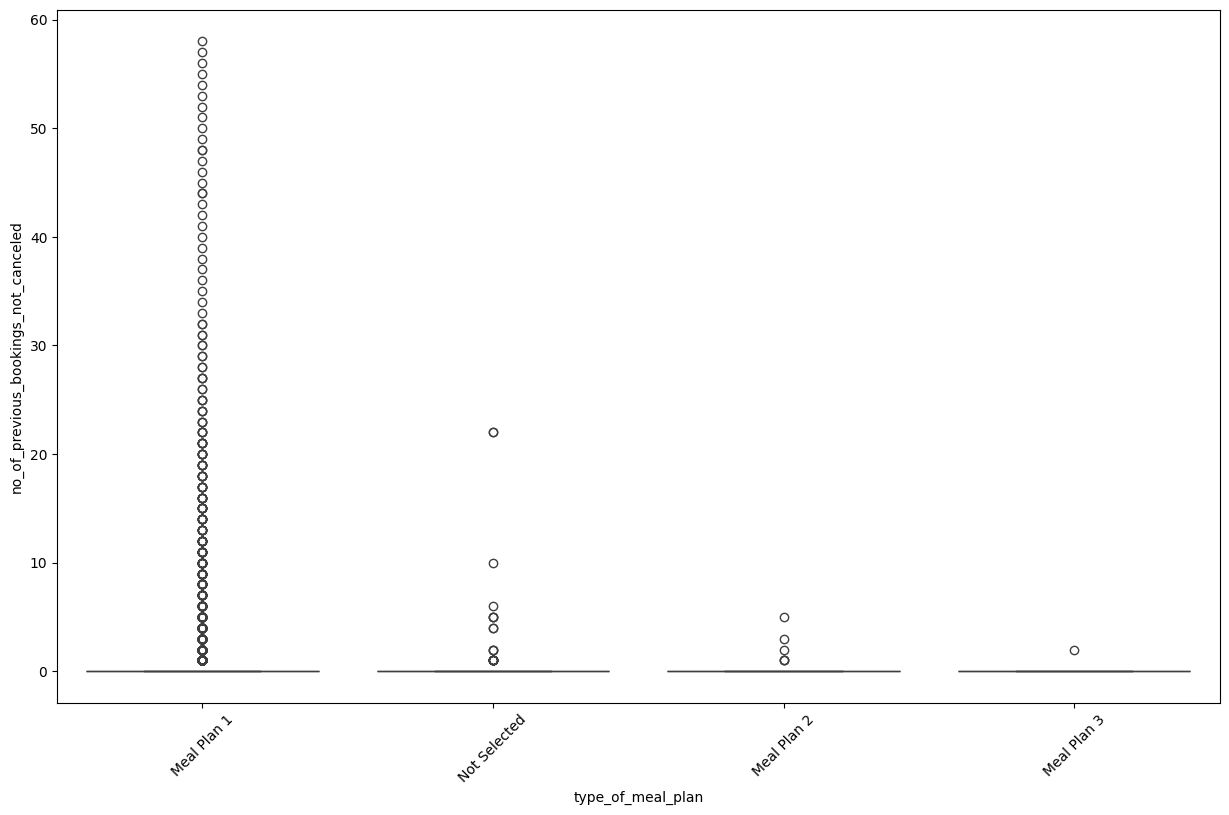

  type_of_meal_plan  count    mean     std  min    my25    my50    my75  max  \
0       Meal Plan 1  27835 0.19572 1.98910    0 0.00000 0.00000 0.00000   58   
1      Not Selected   5130 0.01988 0.49050    0 0.00000 0.00000 0.00000   22   
2       Meal Plan 2   3305 0.00393 0.11133    0 0.00000 0.00000 0.00000    5   
3       Meal Plan 3      5 0.40000 0.89443    0 0.00000 0.00000 0.00000    2   

       pct  
0 76.73329  
1 14.14197  
2  9.11096  
3  0.01378  


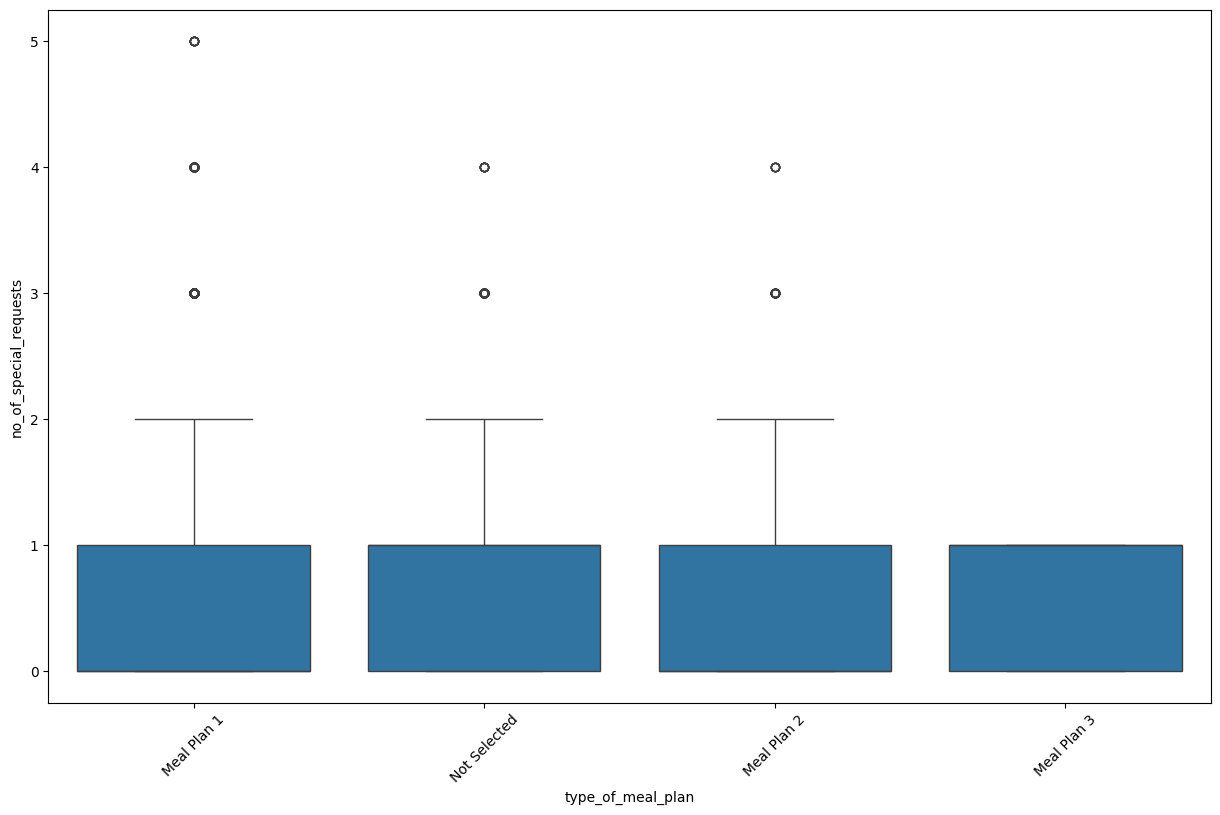

  type_of_meal_plan  count    mean     std  min    my25    my50    my75  max  \
0       Meal Plan 1  27835 0.63000 0.80226    0 0.00000 0.00000 1.00000    5   
1      Not Selected   5130 0.71209 0.75785    0 0.00000 1.00000 1.00000    4   
2       Meal Plan 2   3305 0.38911 0.63675    0 0.00000 0.00000 1.00000    4   
3       Meal Plan 3      5 0.60000 0.54772    0 0.00000 1.00000 1.00000    1   

       pct  
0 76.73329  
1 14.14197  
2  9.11096  
3  0.01378  


In [55]:
#C55
cat = "type_of_meal_plan"
for num in numeric_columns :
  category_boxplot(df, cat, num )
  print(category_pivot(df,cat, num ))

In [ ]:
# Meal Plan 1 is 27,835 bookings, 76.7 percent. Median price 99.45 euros.
# Not Selected is 14.1 percent, median price 89.25 euros.
# Meal Plan 2 is 9.1 percent, median price 109 euros, median lead time 102 days.
# Meal Plan 1 median lead time is 57 days. Not Selected is 36 days.
# Meal Plan 3 is 5 bookings.
# This is profile by meal plan.

In [56]:
print(df.columns[df.columns.duplicated()].to_list())
print(df["required_car_parking_space"].shape)

[]
(36275,)


In [57]:
#C56
print(pd.crosstab(df["required_car_parking_space"], df["booking_status"], margins=True).to_string())

booking_status              Canceled  Not_Canceled    All
required_car_parking_space                               
0                              11771         23380  35151
1                                114          1010   1124
All                            11885         24390  36275


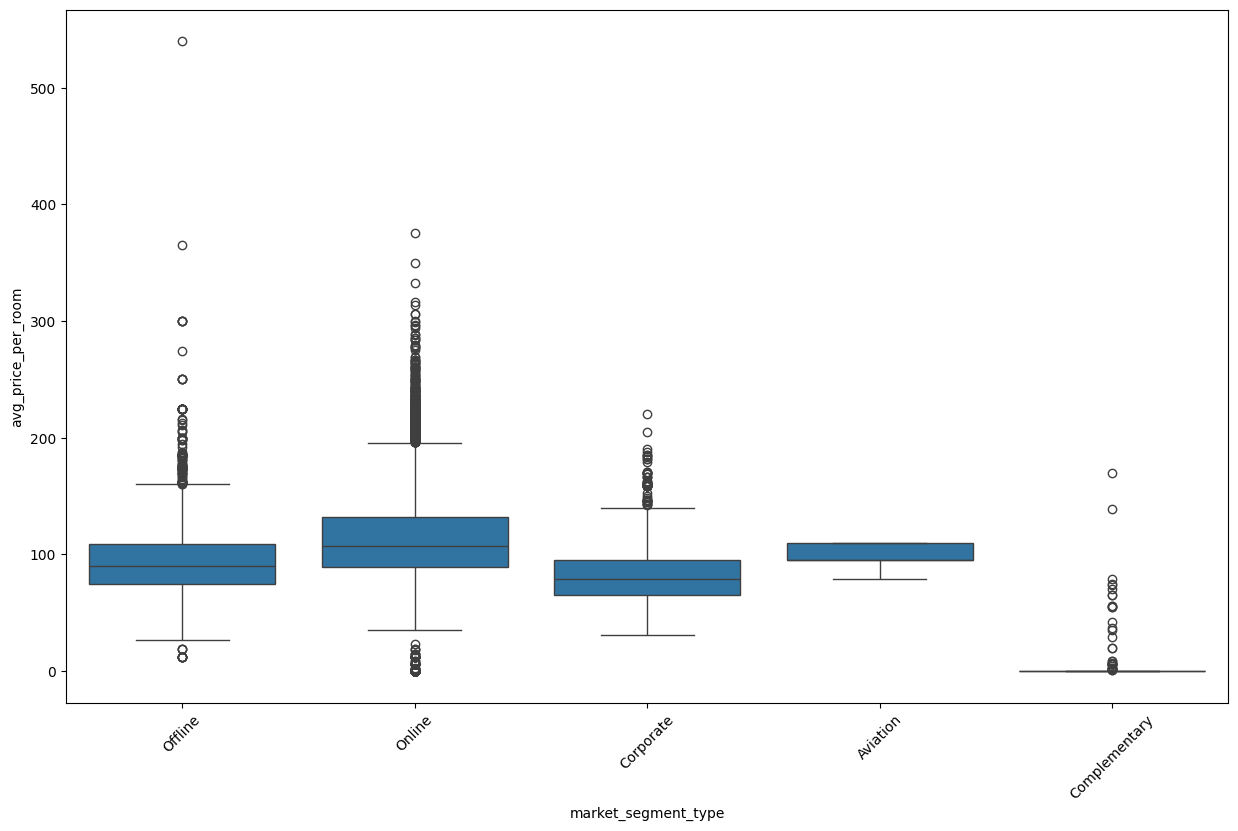

  market_segment_type  count      mean      std      min     my25      my50      my75       max      pct
0             Offline  10528  91.63268 24.99560 12.00000 75.00000  90.00000 109.00000 540.00000 29.02274
1              Online  23214 112.25685 35.22032  0.00000 89.00000 107.10000 131.75000 375.50000 63.99449
2           Corporate   2017  82.91174 23.69000 31.00000 65.00000  79.00000  95.00000 220.00000  5.56030
3            Aviation    125 100.70400  8.53836 79.00000 95.00000  95.00000 110.00000 110.00000  0.34459
4       Complementary    391   3.14176 15.51297  0.00000  0.00000   0.00000   0.00000 170.00000  1.07788
booking_status       Canceled  Not_Canceled
market_segment_type                        
Aviation              0.29600       0.70400
Complementary         0.00000       1.00000
Corporate             0.10907       0.89093
Offline               0.29949       0.70051
Online                0.36508       0.63492


In [58]:
#C57
category_boxplot(df, "market_segment_type", "avg_price_per_room")
print(category_pivot(df, "market_segment_type", "avg_price_per_room").to_string())
print(pd.crosstab(df["market_segment_type"], df["booking_status"], normalize="index").to_string())

In [59]:
# cat = "repeated_guest"
# for num in numberic_columns :
#   category_boxplot(df,num, cat )
#   print(category_pivot(df,cat, num ))

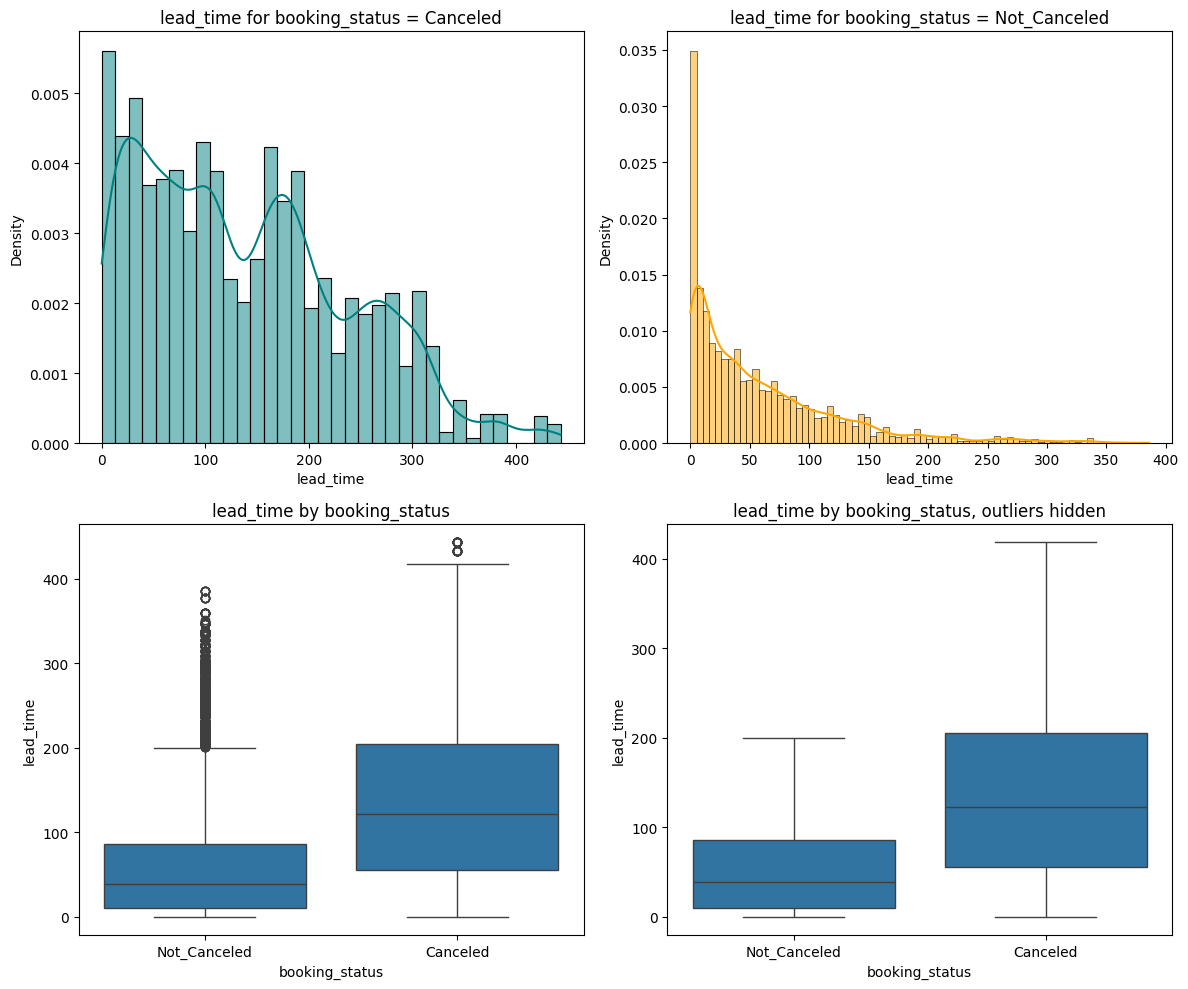

  booking_status  count      mean      std  min     my25      my50      my75  max      pct
0   Not_Canceled  24390  58.92722 64.02871    0 10.00000  39.00000  86.00000  386 67.23639
1       Canceled  11885 139.21548 98.94773    0 55.00000 122.00000 205.00000  443 32.76361


In [60]:
#C58
distribution_plot_wrt_target(df, "lead_time", "booking_status")
print(category_pivot(df, "booking_status", "lead_time").to_string())

In [ ]:
# Canceled bookings have longer lead times: median 122 days versus 39 for kept bookings.
# Kept bookings pile up near zero. The long tail is mostly canceled and is not treated as an error.
# Association, not proof that booking early causes a cancellation.

##Data Prepatation for Modeling

##Outlier Detection

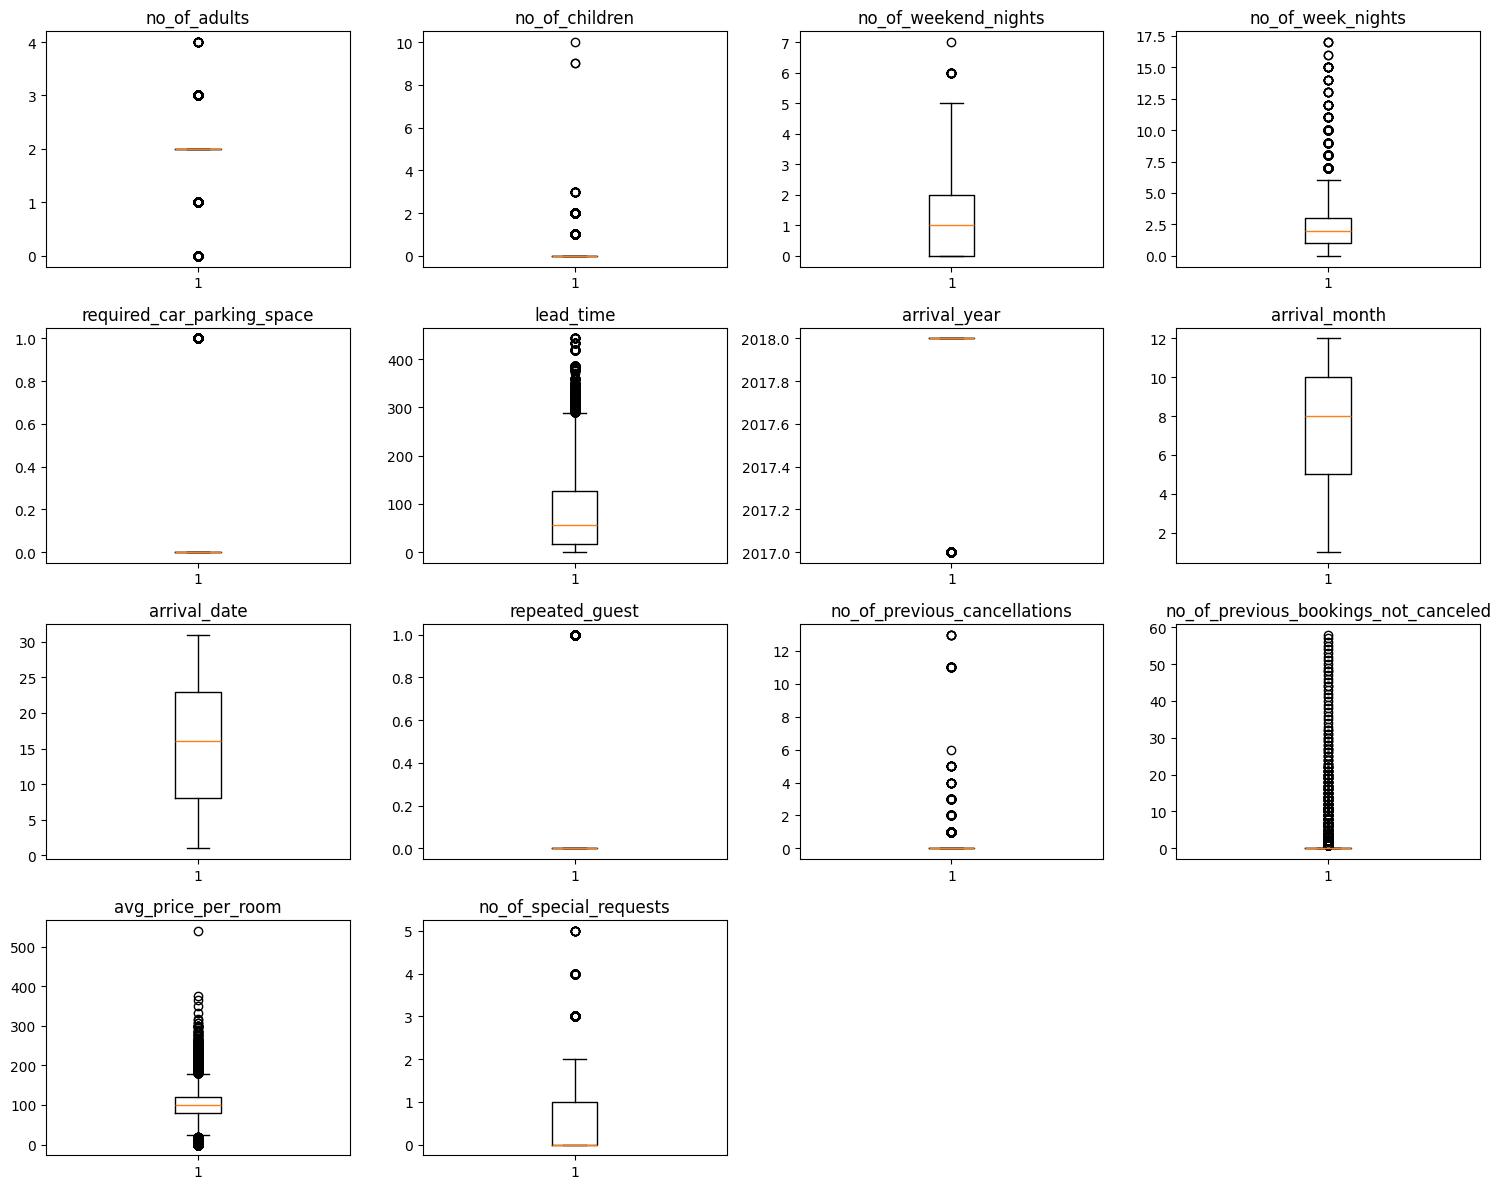

In [61]:
#C59
# outlier detection using boxplot
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(df[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

In [ ]:
# Whiskers are the 1.5 IQR fence. Points outside are not treated.
# 0 adults, 10 children, and 0 euros stay parked.
# Lead time and price tails stay. They can be real bookings.

In [62]:
#C60
# Encode booking_status Not_cancel to 0 and canceld to 1
replaceStruct = { "booking_status":     {"Not_Canceled": 0, "Canceled": 1 } }

df=df.replace(replaceStruct)
df.head(5)


,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00000,0,0
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68000,1,0
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00000,0,1
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00000,0,1
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50000,0,1


In [63]:
#C61 confirm
print(df["booking_status"].value_counts().to_string())

booking_status
0    24390
1    11885


## Building a Logistic Regression model

In [64]:
#C62
# X independent, y dependent
X = df.drop(columns=["booking_status", "Booking_ID"])
y = df["booking_status"]
X = pd.get_dummies(
    X,
    columns=["type_of_meal_plan", "room_type_reserved", "market_segment_type"],
    drop_first=True,
    dtype=float,
)
print(X.shape)
print(y.value_counts().to_string())

(36275, 27)
booking_status
0    24390
1    11885


In [65]:
#C63
X = sm.add_constant(X, has_constant="add")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=1, stratify=y
)

In [66]:
#C64 peak at y_train
print(y_train.value_counts(normalize=True).to_string())

booking_status
0   0.67238
1   0.32762


In [67]:
#C65
print("Shape of training set:", X_train.shape)
print("Shape of test set:", X_test.shape)
print("\nPercentage of classes in training set:")
print(y_train.value_counts(normalize=True).to_string())
print("\nPercentage of classes in test set:")
print(y_test.value_counts(normalize=True).to_string())

Shape of training set: (25392, 28)
Shape of test set: (10883, 28)

Percentage of classes in training set:
booking_status
0   0.67238
1   0.32762

Percentage of classes in test set:
booking_status
0   0.67233
1   0.32767


In [ ]:
# We had seen that around 67% of observations belongs to class 0 (Not Canceled)
# and 32% observations belongs to class 1 (Canceled), and this is preserved in the train and test sets

In [68]:
#C66
logit = sm.Logit(y_train, X_train.astype(float))
lg = logit.fit(disp=False, maxiter=1000)
print(lg.summary())

                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25392
Model:                          Logit   Df Residuals:                    25364
Method:                           MLE   Df Model:                           27
Date:                Thu, 08 Oct 2026   Pseudo R-squ.:                  0.3322
Time:                        13:37:26   Log-Likelihood:                -10724.
converged:                      False   LL-Null:                       -16060.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
const                                 -886.9562    121.332     -7.310      0.000   -1124.762    -649.150
no_of_adults                             0.0333      

In [69]:
#C67 converged = False, drop meal plan 3 and complementary market
X_train = X_train.drop(columns=["type_of_meal_plan_Meal Plan 3", "market_segment_type_Complementary"])
X_test = X_test.drop(columns=["type_of_meal_plan_Meal Plan 3", "market_segment_type_Complementary"])
logit = sm.Logit(y_train, X_train.astype(float))
lg = logit.fit(disp=False, maxiter=500)
print(lg.converged)
print(lg.summary())

True
                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25392
Model:                          Logit   Df Residuals:                    25366
Method:                           MLE   Df Model:                           25
Date:                Thu, 08 Oct 2026   Pseudo R-squ.:                  0.3317
Time:                        13:37:26   Log-Likelihood:                -10732.
converged:                       True   LL-Null:                       -16060.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
const                                 -885.1684    121.148     -7.306      0.000   -1122.615    -647.722
no_of_adults                             0.0275 

In [ ]:
# C67 converged after dropping Meal Plan 3 and Complementary (too few rows).
# Train pseudo R^2 0.33. Not accuracy.
# Longer lead time and higher price raise cancel log-odds.
# Special requests, parking, and repeat guests lower them.
# Do not quote the intercept without arrival_year.

In [70]:
#C68
print("Training performance:")
print(model_performance_classification_statsmodels(lg, X_train, y_train).to_string())


Training performance:
   Accuracy  Recall  Precision      F1
0   0.80640 0.63205    0.73921 0.68144


In [71]:
#C69
print(model_performance_classification_statsmodels(lg, X_test, y_test).to_string())

   Accuracy  Recall  Precision      F1
0   0.80345 0.62647    0.73463 0.67625


In [ ]:
# Test matches train at cutoff 0.5. Not overfit.
# Recall about 0.63: about 37 percent of cancellations are missed.
# Precision about 0.73. Accuracy is above the 0.67 base rate and is not the decision score.

##Test for Multicollinearity
VIF asks whether a coefficient is unstable because that column repeats another column. It needs the constant, which X_train already has. A VIF near 1 means no overlap. Around 5 is moderate. 10 or more is high. A high VIF is not a delete on the first pass. arrival_year and const are the pair to watch.

In [73]:
#C70
print(checking_vif(X_train).sort_values(by="VIF", ascending=False).to_string())

                                 feature      VIF
25            market_segment_type_Online 21.10697
24           market_segment_type_Offline 18.67406
23         market_segment_type_Corporate  5.18064
2                         no_of_children  2.00554
21        room_type_reserved_Room_Type 6  1.98316
13                    avg_price_per_room  1.94995
10                        repeated_guest  1.74716
12  no_of_previous_bookings_not_canceled  1.56891
7                           arrival_year  1.43317
6                              lead_time  1.40171
19        room_type_reserved_Room_Type 4  1.35574
1                           no_of_adults  1.33348
11          no_of_previous_cancellations  1.32151
16        type_of_meal_plan_Not Selected  1.27764
8                          arrival_month  1.27688
15         type_of_meal_plan_Meal Plan 2  1.25959
14                no_of_special_requests  1.24352
17        room_type_reserved_Room_Type 2  1.09457
4                      no_of_week_nights  1.09072


In [ ]:
# VIF is high only inside market segment: Online 21, Offline 19, Corporate 5.
# Lead time, price, and special requests are near 1.

##  Converting coefficients to odds
* The coefficients of the logistic regression model are in terms of log(odd), to find the odds we have to take the exponential of the coefficients.
* Therefore, **odds =  exp(b)**
* The percentage change in odds is given as **odds = (exp(b) - 1) * 100**

In [74]:
#C71
odds = pd.DataFrame({"coef": lg.params, "odds": np.exp(lg.params)})
odds["pct_change_odds"] = (odds["odds"] - 1) * 100
print(odds.sort_values("odds", ascending=False).to_string())

                                           coef    odds  pct_change_odds
room_type_reserved_Room_Type 3          0.82558 2.28320        128.32021
arrival_year                            0.43711 1.54823         54.82321
market_segment_type_Online              0.39527 1.48479         48.47860
no_of_previous_cancellations            0.34689 1.41466         41.46571
type_of_meal_plan_Not Selected          0.20344 1.22562         22.56177
type_of_meal_plan_Meal Plan 2           0.16993 1.18522         18.52165
no_of_weekend_nights                    0.14824 1.15979         15.97869
no_of_children                          0.07870 1.08188          8.18812
no_of_week_nights                       0.03680 1.03748          3.74820
no_of_adults                            0.02750 1.02789          2.78866
avg_price_per_room                      0.01869 1.01887          1.88659
lead_time                               0.01580 1.01593          1.59284
arrival_date                            0.00296 1.0

In [ ]:
# Odds are multipliers versus the left-out level, not probabilities.
# Per day of lead time: odds 1.016. Per euro: odds 1.019.
# Per special request: odds 0.225. Parking: 0.199. Repeat guest: 0.147.
# Do not quote const, arrival_year, or Room_Type 3.

In [ ]:
# #C72
# #  finding the percentage change
# perc_change_odds = (np.exp(lg7.params) - 1) * 100

# # adding the change_odds% to a datafra
# pd.DataFrame(perc_change_odds, x_train7.columns, columns=["change_odds%"])

In [ ]:
# Coefficient interpretations. Odds are multipliers, holding the other columns at their values.
# Compared with the left-out level. Not probabilities.

# no_of_weekend_nights: one more weekend night multiplies cancel odds by 1.16, about 16 percent higher odds.
# no_of_week_nights: one more week night multiplies cancel odds by 1.04, about 3.7 percent higher odds.
# lead_time: one more day multiplies cancel odds by 1.016, about 1.6 percent higher odds.
# no_of_previous_cancellations: one more prior cancel multiplies odds by 1.41, about 41 percent higher odds.
# avg_price_per_room: one more euro multiplies cancel odds by 1.019, about 1.9 percent higher odds.
# no_of_special_requests: one more request multiplies odds by 0.225, about 77.5 percent lower odds.
# type_of_meal_plan_Not Selected: versus Meal Plan 1, odds 1.23, about 23 percent higher odds.

In [ ]:
# Model performance evaluation

# The model can be wrong in two ways.
# False negative: predict the booking will be kept, and the guest cancels.
# The hotel holds the room and may not resell it.
# False positive: predict the booking will cancel, and the guest shows up.
# The hotel may have resold the room or tightened the policy on a good booking.

# Those costs are not equal. A missed cancellation is the empty room.
# A false cancellation flag can annoy a guest who was going to stay.
# Recall is the share of real cancellations the model catches.
# Raising recall cuts missed cancels and usually raises false flags.
# The cutoff is the tradeoff. 0.5 is the default, not the hotel's choice.

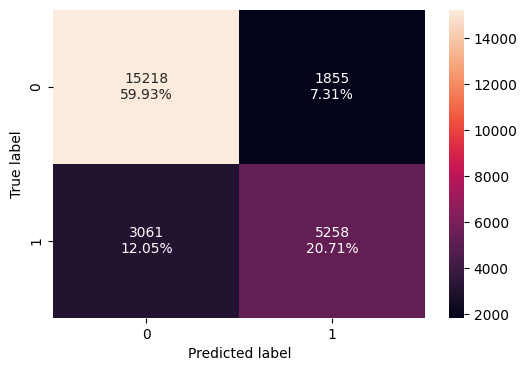

In [75]:
#C73
# Train confusion matrix at cutoff 0.5. True label on y, predicted on x.
confusion_matrix_statsmodels(lg, X_train, y_train, threshold=0.5)

In [77]:
#C74
# Train at 0.5: 5,258 cancels caught, 3,061 missed, 1,855 kept bookings flagged.
# Recall 0.632, precision 0.739. Same row as C68.
pred_train = (lg.predict(X_train) > 0.5).astype(int)
print(pd.crosstab(y_train, pred_train, rownames=["Actual"], colnames=["Predicted"]).to_string())

Predicted      0     1
Actual                
0          15218  1855
1           3061  5258


##ROC-AUC on training set

The Receiver Operating Characteristic (ROC) curve plots the share of cancels caught against the share of kept bookings flagged, across cutoffs. The area under the curve (AUC) is the ranking skill. 0.5 dashed line is a coin flip. This is not the hotel's chosen cutoff.

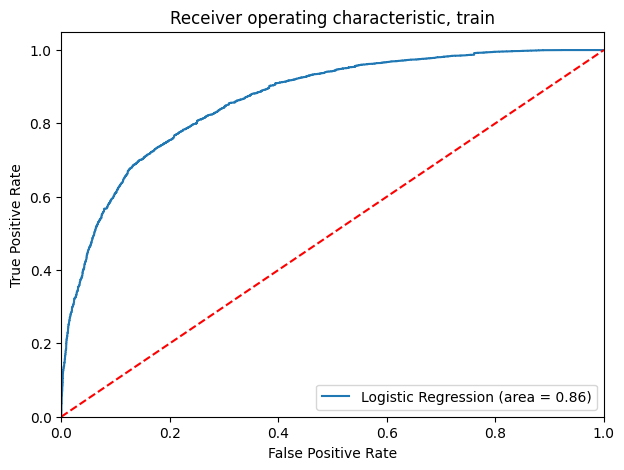

Train ROC-AUC: 0.864


In [78]:
#C75
# ROC on the training set. Uses probabilities, not the 0.5 cutoff.
logit_roc_auc_train = roc_auc_score(y_train, lg.predict(X_train))
fpr, tpr, thresholds = roc_curve(y_train, lg.predict(X_train))
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label="Logistic Regression (area = %0.2f)" % logit_roc_auc_train)
plt.plot([0, 1], [0, 1], "r--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver operating characteristic, train")
plt.legend(loc="lower right")
plt.show()
print("Train ROC-AUC:", round(logit_roc_auc_train, 3))

In [80]:
#76
# Train ROC-AUC 0.864. Test ROC-AUC 0.861.
# Ranking skill held on bookings the model did not see.
# This is not the 0.5 accuracy, and it is not a chosen cutoff.

print("Test ROC-AUC:", round(roc_auc_score(y_test, lg.predict(X_test)), 3))

Test ROC-AUC: 0.861


In [81]:
#C77
pred_test = (lg.predict(X_test) > 0.5).astype(int)

In [82]:
#C78
pred_train = (lg.predict(X_train) > 0.5).astype(int)
pred_test = (lg.predict(X_test) > 0.5).astype(int)
print("Accuracy on training set:", round(accuracy_score(y_train, pred_train), 5))
print("Accuracy on test set:", round(accuracy_score(y_test, pred_test), 5))

Accuracy on training set: 0.8064
Accuracy on test set: 0.80345


## Final Model Summary

## Building a Decision Tree model

   Accuracy  Recall  Precision      F1
0   0.99437 0.98570    0.99708 0.99136
   Accuracy  Recall  Precision      F1
0   0.86658 0.79445    0.79758 0.79601


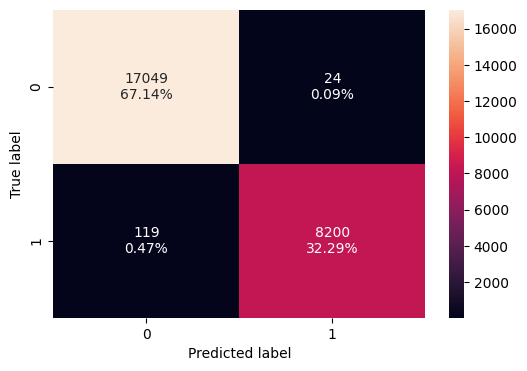

In [85]:
#C80
# Unrestricted tree: train accuracy 0.994, test 0.867. Overfit.
# Test recall 0.794 versus logistic regression 0.626 at cutoff 0.5.

model0 = DecisionTreeClassifier(random_state=1)
model0.fit(X_train, y_train)
confusion_matrix_sklearn(model0, X_train, y_train)
print(model_performance_classification_sklearn(model0, X_train, y_train).to_string())
print(model_performance_classification_sklearn(model0, X_test, y_test).to_string())



   Accuracy  Recall  Precision      F1
0   0.99358 0.99423    0.98629 0.99024
   Accuracy  Recall  Precision      F1
0   0.86033 0.79192    0.78401 0.78795


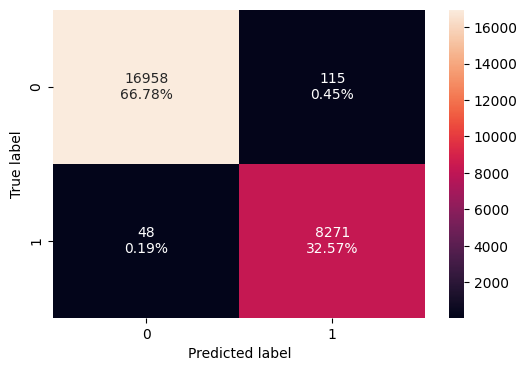

In [84]:
#C81
model = DecisionTreeClassifier(random_state=1, class_weight="balanced")
model.fit(X_train, y_train)
confusion_matrix_sklearn(model, X_train, y_train)
print(model_performance_classification_sklearn(model, X_train, y_train).to_string())
print(model_performance_classification_sklearn(model, X_test, y_test).to_string())

In [ ]:
# Both unrestricted trees memorize the train set.
# * Unweighted train accuracy 0.994, test 0.867.
# * Balanced train accuracy 0.994, test 0.860.
# * A tree with no depth limit keeps splitting until train bookings are sorted.
# * That is overfit: train looks almost perfect, test is clearly worse.
# * Test is still above the 0.67 base rate. It did not collapse.
# * class_weight="balanced" is not a prune.

## Model performance evaluation

This section scores the logistic model already fit. It does not build a new model.

`lg` converged after Meal Plan 3 and Complementary were dropped. The train set has 25,392 rows. The test set has 10,883 rows. Class 1 is canceled, about 32.8 percent on both sides.

At cutoff 0.5, train and test match: accuracy about 0.80, recall about 0.63, precision about 0.73. The ROC-AUC is 0.864 on train and 0.861 on test.

The goal is the four counts, not just the score row.

- A false negative is a cancellation predicted as kept. The room may go empty.
- A false positive is a kept booking flagged as a cancellation. A guest who would have stayed is flagged.
- Recall is the share of real cancellations caught.
- Precision is the share of cancellation flags that are real.
- Accuracy is above the 0.67 base rate and is not the decision score.

Do not refit. Do not drop columns. Do not choose the cutoff here. The 0.5 matrix is the baseline the next section will move.

### Confusion matrix at cutoff 0.5


In [106]:
#C82
# Test confusion matrix at cutoff 0.5. Rows are actual, columns are predicted.

pred_test = (lg.predict(X_test) > 0.5).astype(int)
print(pd.crosstab(y_test, pred_test, rownames=["Actual"], colnames=["Predicted"]).to_string())

# Test at 0.5: 2,234 cancels caught, 1,332 missed, 807 kept bookings flagged.
# Recall 0.626, precision 0.735. Same row as the test score.

Predicted     0     1
Actual               
0          6510   807
1          1332  2234


### ROC-AUC, train and test

The Receiver Operating Characteristic (ROC) curve uses the predicted probabilities, not the 0.5 cutoff. The area under the curve is ranking skill. A value of 0.5 is no better than chance.

The train curve is in the ROC cell. The train ROC-AUC is 0.864. The test ROC-AUC is 0.861. The ranking held on bookings the model did not see. This is not the 0.5 accuracy, and it is not a chosen cutoff.

see code cell #C75

## Choosing a cutoff

The logistic model stays as fit. This section only moves the line where a probability becomes a cancellation flag.

At 0.5 the test set misses 1,332 cancellations and flags 807 kept bookings. A lower cutoff catches more cancellations and raises false flags. A higher cutoff does the reverse. Recall and precision move in opposite directions.

The goal is one cutoff, with train and test scores at that cutoff. The default 0.5 is the baseline, not the hotel's choice.

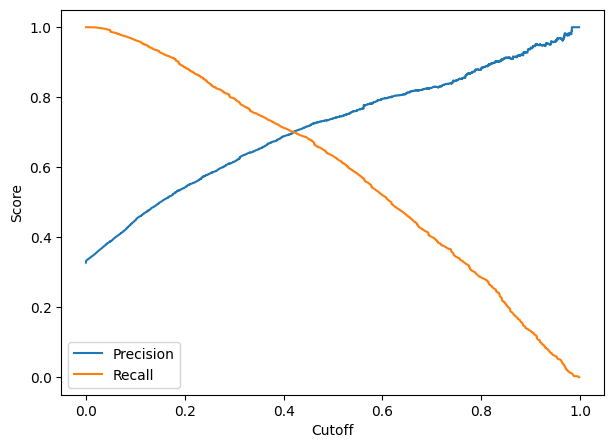

In [107]:
#C83
# Precision and recall across cutoffs, train probabilities.
prec, rec, thresh = precision_recall_curve(y_train, lg.predict(X_train))
plt.figure(figsize=(7, 5))
plt.plot(thresh, prec[:-1], label="Precision")
plt.plot(thresh, rec[:-1], label="Recall")
plt.xlabel("Cutoff")
plt.ylabel("Score")
plt.legend()
plt.show()

In [108]:
#C84
# Candidate cutoff 0.40. Compare with 0.5. Class 1 is canceled.
print("Train 0.40")
print(model_performance_classification_statsmodels(lg, X_train, y_train, threshold=0.40).to_string())
print("Test 0.40")
print(model_performance_classification_statsmodels(lg, X_test, y_test, threshold=0.40).to_string())

Train 0.40
   Accuracy  Recall  Precision      F1
0   0.80006 0.71235    0.68827 0.70010
Test 0.40
   Accuracy  Recall  Precision      F1
0   0.79436 0.70864    0.67821 0.69309


In [109]:
# Chosen cutoff 0.40. Test recall 0.709, precision 0.678, accuracy 0.794.
# Versus 0.5: more cancels caught, more false flags. Train and test still match.
# Balance choice. No dollar cost was in the file.

### Precision-recall across thresholds

Precision rises as the cutoff rises. Recall falls. The curves cross a little below 0.45. At 0.5, precision is above recall. Around 0.40 the two scores are close, near 0.70. No dollar cost was in the file, so 0.40 is a balance choice, not a proven optimum.

### Train and test scores at the chosen cutoff

The chosen cutoff is 0.40. Class 1 is canceled. Train and test still match.

| Cutoff | Set | Accuracy | Recall | Precision | F1 |
|---|---|---|---|---|---|
| 0.50 | Test | 0.803 | 0.626 | 0.735 | 0.676 |
| 0.40 | Train | 0.800 | 0.712 | 0.688 | 0.700 |
| 0.40 | Test | 0.794 | 0.709 | 0.678 | 0.693 |

At 0.40 the model catches about 71 percent of cancellations, against 63 percent at 0.5. Precision falls from 0.73 to 0.68, so more kept bookings are flagged. Accuracy stays above the 0.67 base rate. This is a balance choice. No dollar cost was in the file.

## Decision Tree

A decision tree sorts bookings by rules, such as lead time above a cut or special requests equal to zero. It does not use log-odds.

Two unrestricted trees are already fit. Both memorize the train set: accuracy about 0.994 on train and about 0.86 on test. `class_weight="balanced"` changes which mistakes count. It is not a prune.

The goal of this section is one limited tree.

### Unrestricted tree, train versus test

An unrestricted tree is the baseline, not the model to quote. With no depth limit it sorts train bookings until almost every one is correct.

Unweighted: train accuracy 0.994, test 0.867. Balanced: train accuracy 0.994, test 0.860. Test recall is about 0.79 either way. The weight is not a prune. The next table has to improve the test score, or at least match it with a simpler tree.

### Prune by max depth


In [110]:
#C85
rows = []
for depth in range(2, 11):
    tree_d = DecisionTreeClassifier(random_state=1, max_depth=depth)
    tree_d.fit(X_train, y_train)
    tr = model_performance_classification_sklearn(tree_d, X_train, y_train)
    te = model_performance_classification_sklearn(tree_d, X_test, y_test)
    rows.append(
        {
            "max_depth": depth,
            "train_recall": tr["Recall"].iloc[0],
            "test_recall": te["Recall"].iloc[0],
            "test_precision": te["Precision"].iloc[0],
            "test_f1": te["F1"].iloc[0],
        }
    )
print(pd.DataFrame(rows).to_string(index=False))

 max_depth  train_recall  test_recall  test_precision  test_f1
         2       0.43575      0.43298         0.72183  0.54128
         3       0.73494      0.73051         0.66050  0.69374
         4       0.70008      0.68761         0.76363  0.72362
         5       0.71066      0.70022         0.77283  0.73474
         6       0.68265      0.67274         0.81933  0.73884
         7       0.71908      0.70275         0.81789  0.75596
         8       0.78255      0.76304         0.80337  0.78268
         9       0.79445      0.77145         0.81007  0.79029
        10       0.80659      0.77790         0.81950  0.79816


In [111]:
# Chosen depth 5. Test recall 0.700, test precision 0.773.
# Train recall 0.711. Not the 0.99 unrestricted train score.
# Depth 8 is the higher-recall alternate: test recall 0.763.

### Chosen tree, test score

The quoted tree has max depth 5. It is unweighted. The unrestricted train accuracy of 0.994 is not the score.

Depth 5 test recall is 0.700 and test precision is 0.773. Train recall is 0.711, so the quiz matches the lesson.

In [112]:
#C86
tree_5 = DecisionTreeClassifier(random_state=1, max_depth=5)
tree_5.fit(X_train, y_train)
print("Train")
print(model_performance_classification_sklearn(tree_5, X_train, y_train).to_string())
print("Test")
print(model_performance_classification_sklearn(tree_5, X_test, y_test).to_string())

Train
   Accuracy  Recall  Precision      F1
0   0.83310 0.71066    0.76353 0.73615
Test
   Accuracy  Recall  Precision      F1
0   0.83433 0.70022    0.77283 0.73474


In [113]:
# Quoted tree: max depth 5. Test recall 0.700, precision 0.773, accuracy 0.834.
# Train matches test.

## Model comparison

Both scores are on the test set. The logistic model is the one that converged, scored at cutoff 0.40. The tree is max depth 5. The unrestricted train accuracy of 0.994 is not in this comparison.

| Model | Accuracy | Recall | Precision | F1 |
|---|---|---|---|---|
| Logistic regression, cutoff 0.40 | 0.794 | 0.709 | 0.678 | 0.693 |
| Tree, max depth 5 | 0.834 | 0.700 | 0.773 | 0.735 |

Recall is almost the same: about 70 percent of cancellations caught. The tree is more precise, 0.773 against 0.678, so fewer kept bookings are flagged. Accuracy is higher for the tree.

The logistic model explains the direction: longer lead time and higher price raise cancel odds; special requests, parking, and repeat guests lower them.

Use the tree when the hotel wants a higher share of flags to be real cancellations.

Neither score is a dollar cost. No cost was in the file.

### Logistic regression at the chosen cutoff versus the pruned tree

Test set only. Logistic regression at cutoff 0.40 versus the depth-5 tree.

| Model | Accuracy | Recall | Precision | F1 |
|---|---|---|---|---|
| Logistic regression, cutoff 0.40 | 0.794 | 0.709 | 0.678 | 0.693 |
| Tree, max depth 5 | 0.834 | 0.700 | 0.773 | 0.735 |

Both catch about 70 percent of cancellations.
The tree flags fewer kept bookings: precision 0.773 against 0.678.
The logistic model explains more: longer lead time and higher price raise cancel odds; special requests, parking, and a repeat guest lower them.

## Recommendations

Logistic regression at cutoff 0.40 catches about 71 percent of cancellations. The depth-5 tree catches about 70 percent and is more precise, 0.773 against 0.678.

Repeat guests kept 914 of 930 bookings, about 98.3 percent. They are 930 of 36,275 rows, about 2.6 percent. Make the second booking easy.

A parking request goes with a lower cancel rate, about 10 percent against 33.5 percent. Only 3.1 percent of bookings request it. It is a small group, not a growth plan.

Longer lead time raises cancel odds, about 1.6 percent per extra day. Higher price raises cancel odds, about 1.9 percent per extra euro.

One more special request multiplies cancel odds by 0.225. That is an association, not proof that asking for a high floor prevents a cancellation.

No monetary cost was in the file. The cutoff at 0.40 is a balance between missed cancels and false flags, not a computed optimum.

### What the coefficients support

These are odds multipliers from the converged logistic model, holding the other columns at their values. They are not probabilities.

- One extra day of lead time multiplies cancel odds by 1.016, about 1.6 percent higher odds.
- One extra euro multiplies cancel odds by 1.019, about 1.9 percent higher odds.
- One extra special request multiplies odds by 0.225, about 77.5 percent lower odds.
- A parking request multiplies odds by 0.199, about 80 percent lower odds.
- A repeat guest multiplies odds by 0.147, about 85 percent lower odds.
- One extra weekend night multiplies odds by 1.16, about 16 percent higher odds.



### What we can't say

- We can't say the model proves a cause. Lead time, price, and special requests are associations.
- We can't say booking further ahead reduces cancellations. The coefficient goes the other way.
- We can't say a discount will make guests stay. The price coefficient supports that direction. It was not a test of a discount.
- We can't say a special request or a parking request prevents a cancellation.
- We can't say repeat guests pay less. That price table was not run.
- We can't say Online cancels more than a typical booking. The Online odds are versus Aviation, a tiny left-out segment.
- We can't quote the intercept, arrival year, or Room_Type 3.
- We can't quote the unrestricted tree accuracy of 0.994. That was the train set.
- We can't say 0.40 is the best cutoff. No dollar cost was in the file.
- We can't say accuracy of 0.80 means the hotel catches most cancellations. At 0.40 it catches about 71 percent.
- We can't say Meal Plan 3 or Complementary were useless. They were dropped because the fit would not converge.
- We can't say a p-value above 0.05 means a column has no link to cancellation. Those columns stayed in.